# Wind VISION · Clean continuation after P31

**Purpose:** Recover saved experiment results, verify integrity, recover P18's original report from the scope-locked vault *if available*, and begin a clean P32+ notebook. **Safe to Run all with default settings:** earlier experiments A–O and P1–P31 are **not included**. The only experiment, P32, is locked by `P32_EXECUTE = False` at the end.

**Research baseline:** P31 completed on Oct 30; November 3 presentation remains frozen. P32 never executed. The separate P25/P27 generator is not a trained c-LFM flow; P18 is conditional reconstruction, not independent validation.

**Known provenance exception:** on Nov 2 P18 `recovery_and_evaluation.json` changed SHA-256 from `1b473f27c74d5681bba7f889037d0bfbec88b4baf01f76336fb2669b5cf3d458` to `3208ceaf4422b9d5ca2253e4aa6fae1247d7db4046e4f91831de8a9083339e9d`. Original 12 other frozen evidence files still matched. Never rewrite P18 or change the frozen manifest.

**Git:** only commit this clean notebook, the code-only historical export, scripts, and docs. Do **not** commit the exact original notebook with outputs, research HDF5/model checkpoints, `_research_vault`, presentation ZIPs, personal files, or Colab credentials.

Uploaded legacy notebook exact SHA-256: `519a0784953912596eb547501e976da4d3d752dcf1de59cc0f9a20898fb6826d`.

**Order:** Run the recovery cells (1–5). Review the P18 recovery and runtime checks. Only then intentionally change the last cell's `P32_EXECUTE` flag to `True` and execute that cell alone. No training or pip installations are performed here.

In [10]:
# 1 — Mount existing Google Drive; no model execution or pip installs.
from pathlib import Path
import hashlib, json, subprocess, sys
from datetime import datetime, timezone
BASE_WV = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
if not BASE_WV.is_dir():
    try:
        from google.colab import drive
    except ImportError as exc:
        raise RuntimeError('Open this notebook in Colab or mount the existing Drive path. No files were changed.') from exc
    drive.mount('/content/drive', force_remount=False)
assert BASE_WV.is_dir(), f'Original research directory missing: {BASE_WV}'

def wv_sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(8*1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

print('Drive research root:', BASE_WV)
print('Old experiments are NOT executed by this notebook.')


Drive research root: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1
Old experiments are NOT executed by this notebook.


In [11]:
# 2 — Audit P29/P30 frozen presentation + all 13 original evidence digests.
WV29 = BASE_WV / 'meeting_deliverables/p29_jim_nov3_meeting_freeze_20261030T141838Z_8292e4'
WV30 = BASE_WV / 'meeting_deliverables/p30_visual_qa_and_rehearsal_20261030T142437Z_8d0b4e'
WV_MANIFEST = WV29 / 'FROZEN_EVIDENCE_MANIFEST.json'
WV_QA = WV30 / 'P30_PRESENTATION_QA.json'
for p in (WV_MANIFEST, WV_QA):
    assert p.is_file(), f'Missing frozen reference: {p}'
wv_m = json.loads(WV_MANIFEST.read_text())
wv_qa = json.loads(WV_QA.read_text())
wv_deck29 = WV29 / 'JIM_NOV3_OFFLINE_SLIDES.html'
wv_deck30 = WV30 / 'JIM_NOV3_OFFLINE_SLIDES_QA_REVISED.html'
wv_present_checks = {
  'P29 original manifest': (WV_MANIFEST, wv_qa['source_manifest_sha256']),
  'P29 original deck': (wv_deck29, wv_qa['p29_original_slide_deck_sha256']),
  'P30 revised deck': (wv_deck30, wv_qa['p30_new_deck_sha256']),
}
for label, (path, expected) in wv_present_checks.items():
    ok = path.is_file() and wv_sha(path)==expected
    print(f'{label}:', 'VERIFIED' if ok else 'MISMATCH/MISSING')
    assert ok, f'Frozen presentation failed integrity: {label}. Stop.'
wv_audit = []
for row in wv_m['source_evidence']:
    p = Path(row['path'])
    status = 'MATCH' if p.is_file() and wv_sha(p)==row['sha256'] else ('MISSING' if not p.is_file() else 'CHANGED')
    wv_audit.append(dict(key=row['key'],status=status,path=str(p),expected=row['sha256']))
    print(f"{row['key']:12} {status}")
assert len(wv_audit)==13, f'Unexpected evidence count: {len(wv_audit)}'
wv_differences=[row for row in wv_audit if row['status']!='MATCH']
wv_only_p18_mismatch=all(row['key']=='P18' and row['status']=='CHANGED' for row in wv_differences)
wv_other_frozen_ok = all(row['key']=='P18' or row['status']=='MATCH' for row in wv_audit)
print('Evidence mismatches:',[(x['key'],x['status']) for x in wv_differences])
print('Other 12 scientific sources intact:',wv_other_frozen_ok)
if not wv_other_frozen_ok:
    print('STOP: additional frozen evidence differs. Do not enable P32.')


P29 original manifest: VERIFIED
P29 original deck: VERIFIED
P30 revised deck: VERIFIED
P11          MATCH
P17          MATCH
P18          CHANGED
P25          MATCH
P25_MODEL    MATCH
P26          MATCH
P27          MATCH
P27_MODEL    MATCH
P27_CODE     MATCH
P27_FIG      MATCH
P28          MATCH
P28_FIG      MATCH
P28_PAIRS    MATCH
Evidence mismatches: [('P18', 'CHANGED')]
Other 12 scientific sources intact: True


In [12]:
# 3 — Search for the EXACT original P18 content-addressed vault object.
# Does not recurse through, export, or mutate the private historical vault.
wv_p18_entry=next(row for row in wv_m['source_evidence'] if row['key']=='P18')
wv_p18_current=Path(wv_p18_entry['path'])
wv_p18_digest=wv_p18_entry['sha256']
wv_p18_object=(BASE_WV/'_research_vault'/'objects'/wv_p18_digest[:2]/wv_p18_digest)
wv_p18_verified_bytes = None
if wv_p18_object.is_file() and wv_sha(wv_p18_object)==wv_p18_digest:
    wv_p18_verified_bytes = wv_p18_object.read_bytes()
    print('ORIGINAL P18 REPORT RECOVERABLE FROM VAULT: YES (verified exact October 30 SHA-256)')
else:
    print('ORIGINAL P18 REPORT RECOVERABLE FROM VAULT: NO — do not guess or overwrite current report')
wv_p18_original = json.loads(wv_p18_verified_bytes) if wv_p18_verified_bytes else None
wv_p18_latest = json.loads(wv_p18_current.read_text()) if wv_p18_current.is_file() else None

def wv_json_differences(a,b,prefix='$',limit=35):
    result=[]
    def walk(x,y,path):
        if len(result)>=limit:return
        if isinstance(x,dict) and isinstance(y,dict):
            for key in sorted(set(x)|set(y)):
                if key not in x or key not in y:result.append((path+'.'+key,'MISSING OR EXTRA KEY'))
                else:walk(x[key],y[key],path+'.'+key)
        elif isinstance(x,list) and isinstance(y,list):
            if len(x)!=len(y):result.append((path,'list lengths differ'))
            else:
                for k,(u,v) in enumerate(zip(x,y)):walk(u,v,f'{path}[{k}]')
        elif x!=y:result.append((path,'value differs'))
    walk(a,b,prefix)
    return result
if wv_p18_original is not None and wv_p18_latest is not None:
    diffs=wv_json_differences(wv_p18_original,wv_p18_latest)
    print('P18 original/current JSON differences (limited):',diffs or 'none')
    package=wv_p18_original.get('artifact')
    original_model_digest=wv_p18_original.get('artifact_sha256')
    if package and original_model_digest:
        current_pkg=Path(package)
        print('P18 original model path:',current_pkg)
        if current_pkg.is_file():
            current_pkg_sha=wv_sha(current_pkg)
            print('P18 model package matches ORIGINAL report SHA:',current_pkg_sha==original_model_digest)
            if current_pkg_sha!=original_model_digest:
                original_pkg_object=BASE_WV/'_research_vault'/'objects'/original_model_digest[:2]/original_model_digest
                print('Original P18 model package object recoverable:',original_pkg_object.is_file() and wv_sha(original_pkg_object)==original_model_digest)
        else:print('P18 model package missing — preserve state and stop before dependent model work')
print('Recovery is IN MEMORY ONLY. No file restored or overwritten.')


ORIGINAL P18 REPORT RECOVERABLE FROM VAULT: YES (verified exact October 30 SHA-256)
P18 original/current JSON differences (limited): [('$.created_utc', 'value differs')]
P18 original model path: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p18_linear_adapter_958d60a71ba5d6df/linear_fourier_adapter.npz
P18 model package matches ORIGINAL report SHA: True
Recovery is IN MEMORY ONLY. No file restored or overwritten.


In [13]:
# 4 — Reload existing scientific reports without computing new results.
wv_reports={}
for key in ('P11','P17','P25','P26','P27','P28'):
    p=Path(next(row['path'] for row in wv_audit if row['key']==key))
    if p.is_file() and next(row['status'] for row in wv_audit if row['key']==key)=='MATCH':
        wv_reports[key]=json.loads(p.read_text())
        print(f'{key}: loaded, SHA-256 matches Oct 30 manifest')
    else:
        print(f'{key}: unavailable or changed, not loaded')
wv_reports['P18_ORIGINAL'] = wv_p18_original  # None if original SHA object unavailable
wv_reports['P18_CURRENT_UNVERIFIED'] = wv_p18_latest
print('P18 ORIGINAL verified:',wv_reports['P18_ORIGINAL'] is not None)
print('Frozen interpreted results (not newly computed or independently validated):')
print('  P11 NVIDIA L4 exact 80-step parity, median 311.475 ms vs 59.451 ms (5.2392x)')
if wv_p18_original is not None:
    print('  P18 original native MSE:',wv_p18_original.get('original_native',{}).get('mse'))
    print('  P18 original Fourier MSE:',wv_p18_original.get('linear_head',{}).get('mse'))
else:
    print('  P18 18.538% MSE reduction is historical; ORIGINAL report SHA not yet recovered')
if 'P27' in wv_reports:
    print('  P27 training 40-sensor low-power CV:',wv_reports['P27'].get('training_field_low_power_cv'))
print('  P28 historical Gaussian-theory CV 0.687831, generated CV 0.649915')
print('NO retraining, new generated samples, or independent test access occurred.')


P11: loaded, SHA-256 matches Oct 30 manifest
P17: loaded, SHA-256 matches Oct 30 manifest
P25: loaded, SHA-256 matches Oct 30 manifest
P26: loaded, SHA-256 matches Oct 30 manifest
P27: loaded, SHA-256 matches Oct 30 manifest
P28: loaded, SHA-256 matches Oct 30 manifest
P18 ORIGINAL verified: True
Frozen interpreted results (not newly computed or independently validated):
  P11 NVIDIA L4 exact 80-step parity, median 311.475 ms vs 59.451 ms (5.2392x)
  P18 original native MSE: 0.004198543421009256
  P18 original Fourier MSE: 0.0034202276007976673
  P27 training 40-sensor low-power CV: 0.04245926093009935
  P28 historical Gaussian-theory CV 0.687831, generated CV 0.649915
NO retraining, new generated samples, or independent test access occurred.


In [14]:
# 5 — P32 prerequisites: only check paths and pinned commit; NO setup/reinstall.
WV_PIN='921e666c8d6060ae13bfd901dcc7f74f819d0eea'
WV_TRAIN_SHA='676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'
WV_REPO=Path('/content/nasa_clfm_reference')
WV_SNAP=Path('/content/clfm_snapshot')
WV_TRAIN=WV_SNAP/'data/wind/wind_train_data.hdf5'
WV_CKPT=WV_SNAP/'results/control_reference_vae_resume_epoch10_cpu64_v2/checkpoints/epoch-epoch=0009-step=12500.ckpt'
wv_head=None
if (WV_REPO/'.git').exists():
    cp=subprocess.run(['git','-C',str(WV_REPO),'rev-parse','HEAD'],capture_output=True,text=True)
    if cp.returncode==0:wv_head=cp.stdout.strip()
print('Pinned reference checkout present:',WV_REPO.is_dir())
print('Pinned commit actual:',wv_head or 'NOT AVAILABLE')
print('Pinned commit matches:',wv_head==WV_PIN)
print('Trusted training HDF5 exists:',WV_TRAIN.is_file())
print('Trusted epoch-10 checkpoint exists (optional for P32):',WV_CKPT.is_file())
WV_SAVED_SOURCE=BASE_WV/'wind_vision_physicsnemo_day1_patched.py'
wv_source_ok=(WV_SAVED_SOURCE.is_file() and 'P25' in wv_reports and wv_sha(WV_SAVED_SOURCE)==wv_reports['P25'].get('source_sha256'))
print('Saved experiment source matches P25:',wv_source_ok)
print('P25 / P27 / P28 reports loaded:',all(k in wv_reports for k in ('P25','P27','P28')))
print('Correct old P18 original report object recovered:',wv_p18_original is not None)
wv_p32_prepared=(wv_other_frozen_ok and wv_p18_original is not None and
                  all(k in wv_reports for k in ('P25','P27','P28')) and
                  wv_head==WV_PIN and WV_TRAIN.is_file() and wv_source_ok)
print('P32 preflight READY:',wv_p32_prepared)
if not wv_p32_prepared:
    print('Do not enable P32. Resolve the indicated missing conditions without replaying old experiments.')
print('HDF5 hash will be checked INSIDE P32 before any new P32 output is written.')


Pinned reference checkout present: True
Pinned commit actual: 921e666c8d6060ae13bfd901dcc7f74f819d0eea
Pinned commit matches: True
Trusted training HDF5 exists: True
Trusted epoch-10 checkpoint exists (optional for P32): False
Saved experiment source matches P25: True
P25 / P27 / P28 reports loaded: True
Correct old P18 original report object recovered: True
P32 preflight READY: True
HDF5 hash will be checked INSIDE P32 before any new P32 output is written.


In [15]:
# 5b — OPTIONAL restore ONLY missing pinned inputs into temporary /content paths.
# Disabled by default; does not train, install packages, or change Drive files.
RESTORE_MINIMAL_INPUTS = True  # Enable ONLY if stage 5 reports missing inputs.
if not RESTORE_MINIMAL_INPUTS:
    print('No runtime files restored. Existing research remains untouched.')
else:
    import zipfile, shutil, os
    if not (WV_REPO/'.git').is_dir():
        assert not WV_REPO.exists() or not any(WV_REPO.iterdir()), 'Nonempty checkout without Git — stop; no overwrite'
        if WV_REPO.exists():WV_REPO.rmdir()  # empty directory only
        subprocess.run(['git','clone','--filter=blob:none','--no-checkout',
                        'https://github.com/nasa/random_field_c-lfm',str(WV_REPO)], check=True)
        subprocess.run(['git','-C',str(WV_REPO),'fetch','--depth','1','origin',WV_PIN], check=True)
        subprocess.run(['git','-C',str(WV_REPO),'checkout','--detach',WV_PIN], check=True)
    got=subprocess.check_output(['git','-C',str(WV_REPO),'rev-parse','HEAD'],text=True).strip()
    assert got==WV_PIN, 'Wrong source checkout — stop; no overwrite'
    # HDF5 was originally restored into /content/clfm_snapshot from an existing Drive transfer ZIP.
    if not WV_TRAIN.is_file():
        transfer=Path('/content/drive/MyDrive/CLFM_CLOUD_BUNDLE.zip')
        assert transfer.is_file(), f'Existing input transfer ZIP absent: {transfer}'
        target_rel='data/wind/wind_train_data.hdf5'
        with zipfile.ZipFile(transfer) as z:
            matches=[name for name in z.namelist() if name==target_rel or name.endswith('/'+target_rel)]
            assert len(matches)==1, f'Unexpected training-file count: {matches}'
            WV_TRAIN.parent.mkdir(parents=True,exist_ok=True)
            partial=WV_TRAIN.with_name(WV_TRAIN.name+'.p32partial')
            assert not partial.exists(), f'Stale partial file: {partial}; inspect manually'
            try:
                with z.open(matches[0]) as src, partial.open('xb') as dst:
                    shutil.copyfileobj(src,dst,length=8*1024*1024)
                assert wv_sha(partial)==WV_TRAIN_SHA, 'Training HDF5 SHA mismatch — do not replace'
                assert not WV_TRAIN.exists(), 'Input appeared during restore — do not replace'
                os.replace(partial,WV_TRAIN)
            finally:
                if partial.exists():partial.unlink()
    assert wv_sha(WV_TRAIN)==WV_TRAIN_SHA, 'Trusted training HDF5 checksum failed'
    print('Only the pinned source and training input restored to temporary /content.')
    print('Re-run cell 5 (preflight) before executing P32. No Drive research artifacts were changed.')


Only the pinned source and training input restored to temporary /content.
Re-run cell 5 (preflight) before executing P32. No Drive research artifacts were changed.


## Research ledger for new work — scoped, append-only, explicit

The historical P1 v4 recorder must **not** be replayed to bootstrap this new notebook. It previously scanned the entire research scope, and its old vault contains unrelated historical objects. Instead P32 writes a new provenance note **only within its uniquely created P32 folder** with hashes for its own output files; the original P1 recorder, vault, and meeting artifacts are untouched. This is a separate provenance mechanism, not a claim that P1's entire vault was reverified. Code changes can be Git-committed locally from the supplied package.

The final P32 cell is self-contained but initially disabled. Do not turn it on until all recovery checks pass. If the pinned checkout is absent after a Colab restart, restore only that source checkout at the pinned SHA, never rerun historical training.

In [16]:
# 6 — Define P32-only scoped recorder; DOES NOT write or call legacy recorder.
def _wv_p32_recorder(verified_root):
    import json, hashlib
    from pathlib import Path
    from datetime import datetime,timezone
    root=Path(verified_root).resolve()
    allowed=(root/'fidelity_diagnostics').resolve()
    assert root.is_dir() and root.name=='physicsnemo_day1'
    def _checked_run():
        run=Path(globals().get('RUN','/nonexistent')).resolve()
        assert run.is_dir() and run.parent==allowed and run.name.startswith('p32_source_phase_audit_'), f'P32 run location is not scope-locked: {run}'
        return run
    def note(title,question,methods,evidence,findings,limitations,decision):
        run=_checked_run()
        authorized={str(p.resolve()) for p in run.iterdir() if p.is_file()}
        normalized=[]
        for x in evidence:
            p=Path(x).resolve()
            assert str(p) in authorized, f'P32 note references out-of-scope evidence: {p}'
            normalized.append({'name':p.name,'sha256':wv_sha(p),'bytes':p.stat().st_size})
        record=dict(time_utc=datetime.now(timezone.utc).isoformat(),scope='P32_NEW_RUN_ONLY',
                    title=title,question=question,methods=methods,evidence=normalized,
                    findings=findings,limitations=limitations,decision=decision,
                    old_vault_not_scanned_or_modified=True)
        target=run/'P32_PROVENANCE_NOTE.json'
        with target.open('x',encoding='utf-8') as f:
            json.dump(record,f,indent=2,allow_nan=False)
        print('P32-only provenance recorded:',target)
    def verify():
        run=_checked_run()
        note_file=run/'P32_PROVENANCE_NOTE.json'
        assert note_file.is_file()
        record=json.loads(note_file.read_text())
        for e in record['evidence']:
            p=run/e['name']
            assert p.is_file() and wv_sha(p)==e['sha256']
        return {'scope':'P32 new folder only','verified_artifacts':len(record['evidence']),
                'historical_vault_verified':False}
    return note,verify
print('New scoped recorder defined (not invoked). Legacy vault unchanged.')


New scoped recorder defined (not invoked). Legacy vault unchanged.


## P32 — Source-generation phase versus Gaussian-amplitude diagnostic (opt-in)

**Hypothesis:** The fixed-amplitude/random-phase source sampler may explain P28's narrow low-band fieldwise energy distribution. **Controls:** use the same reconstructed source CSD factor with independent uniform phases versus circular Gaussian factors, compare full 100 versus sparse 40 sensors, include uncertainty and source-spectrum checks. **Negative outcomes:** mismatched full-grid constancy, observed/simulated power, or CV require further provenance audit rather than inventing a model. **Decision:** only create a source-aligned baseline if the source mechanism passes all preregistered checks.

*This cell intentionally does nothing during Run all*. To execute P32 after a successful recovery/preflight, change `P32_EXECUTE` to `True` **in this cell alone** and run only it. New run results go under `BASE/fidelity_diagnostics/p32_source_phase_audit_<unique_id>` for the NEXT presentation. No changes to frozen November 3 materials.

In [17]:
# 7 — ONLY new experiment in this notebook: P32. Locked by default.
P32_EXECUTE = False  # Change to True ONLY after cells 1–6 pass. Never Run all to replay.
if not P32_EXECUTE:
    print('P32 NOT EXECUTED. Historical A–P31 results were not rerun.')
else:
    assert wv_p32_prepared, 'Read-only preflight failed; do NOT proceed.'
    assert wv_p18_original is not None, 'Original P18 report is not recovered.'
    note, verify = _wv_p32_recorder(BASE_WV)
    # CELL P32 — Source-phase energy audit (READ-ONLY source/data; no training)
    # PLACE: one NEW Colab code cell immediately below completed P31.
    # Do NOT Run All. P32 evidence goes only to the NEXT presentation.
    from pathlib import Path
    from datetime import datetime, timezone
    import hashlib, json, uuid, sys, subprocess, importlib.metadata, inspect
    import numpy as np
    import h5py
    import matplotlib.pyplot as plt

    BASE = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
    P25 = BASE/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149'
    P27 = BASE/'fidelity_diagnostics/p27_analytic_lowband_calibration_20261030T140550Z_c62259'
    P28 = BASE/'fidelity_diagnostics/p28_energy_dispersion_20261030T141247Z_7887d4'
    REPO = Path('/content/nasa_clfm_reference')
    PIN = '921e666c8d6060ae13bfd901dcc7f74f819d0eea'
    TRAIN_SHA = '676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'
    assert callable(globals().get('note')) and callable(globals().get('verify')), 'Restore corrected scope-locked recorder before P32; never rerun unsafe P1.'
    assert all(p.is_file() for p in (P25/'result.json', P27/'result.json', P28/'result.json'))
    p25 = json.loads((P25/'result.json').read_text())
    p27 = json.loads((P27/'result.json').read_text())
    p28 = json.loads((P28/'result.json').read_text())
    assert p25['status'] == p27['status'] == p28['status'] == 'completed'
    assert subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip() == PIN
    assert (REPO/'data/wind_data_generation/wind_sampler.py').is_file()
    assert (REPO/'data/wind_data_generation/generate_wind_data.py').is_file()

    def sha256(path):
        h = hashlib.sha256()
        with Path(path).open('rb') as f:
            for chunk in iter(lambda: f.read(8*1024*1024), b''):
                h.update(chunk)
        return h.hexdigest()

    # Resolve only the verified training file, not any possible unseen test file.
    # P32 statistical source audit does not need to import the VAE, CUDA,
    # or PhysicsNeMo; verify the archived source bytes against P25 instead.
    archived_source = BASE / 'wind_vision_physicsnemo_day1_patched.py'
    assert archived_source.is_file() and sha256(archived_source) == p25['source_sha256'], 'Archived experiment source differs from P25.'
    train_path = Path('/content/clfm_snapshot/data/wind/wind_train_data.hdf5').resolve()
    assert sha256(train_path) == TRAIN_SHA, 'Training HDF5 SHA differs from the trusted handoff.'
    assert len(p25['training_indices']) == 256
    ids = np.asarray(p25['training_indices'],dtype=int)
    assert len(np.unique(ids)) == 256
    sparse_idx = np.concatenate([np.arange(s,s+10) for s in (0,30,60,90)])

    with h5py.File(train_path,'r') as h5:
        coords = np.asarray(h5['x_grid'],dtype=float)
        time_grid = np.asarray(h5['t_grid'],dtype=float)
        sample_group = h5['wind_samples']
        assert coords.shape == (100,3) and time_grid.shape == (256,)
        assert len(sample_group) == 5000 and np.all(ids >= 0) and np.all(ids < len(sample_group))
        assert np.allclose(coords[:,0], 0)
        expected_coords = np.zeros_like(coords)
        expected_coords[:,1] = np.repeat(np.linspace(0,100,10),10)
        expected_coords[:,2] = np.tile(np.linspace(1,100,10),10)
        assert np.allclose(coords,expected_coords), 'Unexpected grid; do not infer source match.'
        fgrid = np.asarray(h5['input_parameters/freq_grid'],dtype=float)
        shear = float(np.asarray(h5['input_parameters/shear_velocity']))
        assert fgrid.shape == (128,) and np.allclose(fgrid,np.linspace(3/128,3,128))
        assert np.isclose(shear,1.9)
        raw = np.stack([np.asarray(sample_group[str(i)]['v1'],dtype=np.float32) for i in ids])
        assert raw.shape == (256,100,256) and np.isfinite(raw).all()
        metadata = {'top_level_keys':list(h5.keys()),'input_parameter_keys':list(h5['input_parameters'].keys()),
                    'root_attributes':{k:str(v) for k,v in h5.attrs.items()},
                    'sample_count':len(sample_group),'train_indices_count':len(ids),
                    'time_step':float(time_grid[1]-time_grid[0]),'frequency_grid_first_last':[float(fgrid[0]),float(fgrid[-1])]}

    # Match the historical float32 normalization and P28's rFFT statistic.
    normalized = ((raw+np.float32(2.0))/np.float32(49.0)).astype(np.float64)
    F = np.fft.rfft(normalized-normalized.mean(axis=-1,keepdims=True),axis=-1)
    p40 = np.mean(np.abs(F[:,sparse_idx,1:7])**2,axis=(1,2))
    p100 = np.mean(np.abs(F[:,:,1:7])**2,axis=(1,2))
    perbin40 = np.mean(np.abs(F[:,sparse_idx,1:7])**2,axis=1)
    perbin100 = np.mean(np.abs(F[:,:,1:7])**2,axis=1)
    assert np.all(p40>0) and np.all(p100>0)
    def cv(x):
        x = np.asarray(x,dtype=float)
        return float(x.std(ddof=1)/x.mean())
    train_cv40 = cv(p40)
    assert abs(train_cv40-float(p27['training_field_low_power_cv'])) < .002, 'P32 40-sensor training statistic differs from P27; stop.'

    # Source mathematics: replicate EXACT expressions in the pinned wind_sampler.py.
    # In the pinned source, `_get_turbulence_length_scales` receives shear_velocity
    # as its first positional argument, although that parameter is named z_0.
    # Also `(... ) ** 5 / 3` parses as fifth power DIVIDED by three, not ^(5/3).
    source = (REPO/'data/wind_data_generation/wind_sampler.py').read_text()
    assert 'SpectralRepresentation(' in source and 'np.sqrt(S_vj_vj[h, n] * S_vj_vj[k, n])' in source
    z = coords[:,2]
    mean_v = 2.5*shear*np.log(z/0.015)
    variance = (6.0-1.1*np.arctan(np.log(0.015)+1.75))*shear**2
    L = 300*(z/200)**(0.67+0.05*np.log(shear))
    distance = np.linalg.norm((coords[:,None,:]-coords[None,:,:])*np.array([3.,3.,.5]),axis=-1)
    scale_fft = (256/2)**2*(4*(fgrid[1]-fgrid[0]))/(49**2)
    B = []
    S_min_eigs = []
    for k in range(1,7):
        freq = fgrid[k]  # Important: FFT bin k corresponds to source frequency ARRAY INDEX k.
        auto = (variance*6.868*freq*(L/mean_v))/(freq*(1+1.5*freq*6.868*L/mean_v)**5/3)
        coherence = np.exp(-freq*distance/(mean_v[:,None]+mean_v[None,:]))
        S = np.sqrt(auto[:,None]*auto[None,:])*coherence
        assert np.all(np.isfinite(S)) and np.allclose(S,S.T,rtol=1e-12,atol=1e-12)
        # UQpy 4.2.0 SVD, not a generic Cholesky implementation.
        u,s,vh = np.linalg.svd(S,full_matrices=False)
        B.append(u*np.sqrt(s)[None,:])
        S_min_eigs.append(float(np.linalg.eigvalsh(S)[0]))
    B = np.stack(B)       # (6,100,100)
    B40 = B[:,sparse_idx,:]
    H40 = np.einsum('kij,kil->kjl',B40,B40,optimize=True)
    H100 = np.einsum('kij,kil->kjl',B,B,optimize=True)

    def exact_phase_gaussian_cv(H):
        tr = np.trace(H,axis1=1,axis2=2)
        frob2 = np.sum(np.abs(H)**2,axis=(1,2))
        diag2 = np.sum(np.abs(np.diagonal(H,axis1=1,axis2=2))**2,axis=1)
        # Fixed-modulus independent uniform phases: only off-diagonal terms vary.
        phase_var = max(0.,float(np.sum(frob2-diag2)))
        # Circular complex Gaussian factors with E|z|²=1: all terms vary.
        gauss_var = float(np.sum(frob2))
        return {'mean_q_sum':float(np.sum(tr)),'phase_cv':float(np.sqrt(phase_var)/np.sum(tr)),
                'circular_gaussian_cv':float(np.sqrt(gauss_var)/np.sum(tr))}

    th40 = exact_phase_gaussian_cv(H40)
    th100 = exact_phase_gaussian_cv(H100)
    # Absolute expected normalized FFT power: sum |Bz|² divided by number of sensors.
    expected_bin40 = scale_fft*np.trace(H40,axis1=1,axis2=2)/40
    expected_bin100 = scale_fft*np.trace(H100,axis1=1,axis2=2)/100
    observed_bin40 = perbin40.mean(axis=0)
    observed_bin100 = perbin100.mean(axis=0)
    ratios40 = observed_bin40/expected_bin40
    ratios100 = observed_bin100/expected_bin100

    # Controlled simulation from the SAME six source-matrix factors, changing ONLY
    # phase-only factors vs circular Gaussian factors; not a trained wind generator.
    N=2048
    rg_phase=np.random.default_rng(320132)
    rg_gauss=np.random.default_rng(320133)
    z_phase=np.exp(2j*np.pi*rg_phase.random((N,6,100)))
    z_gauss=(rg_gauss.standard_normal((N,6,100))+1j*rg_gauss.standard_normal((N,6,100)))/np.sqrt(2)
    def energy_factors(z):
        y=np.einsum('kij,nkj->nki',B40,z,optimize=True)
        return np.sum(np.abs(y)**2,axis=(1,2)).real
    model_phase=energy_factors(z_phase)
    model_gauss=energy_factors(z_gauss)
    assert abs(cv(model_phase)/th40['phase_cv']-1)<.12, 'Phase-MC and theory disagree.'
    assert abs(cv(model_gauss)/th40['circular_gaussian_cv']-1)<.12, 'Gaussian-MC and theory disagree.'

    # Source-phase 256-field sampling uncertainty vs observed CV, not a fitted threshold.
    rg_boot=np.random.default_rng(320134)
    R=1600
    boot_obs=np.empty(R)
    boot_phase=np.empty(R)
    for r in range(R):
        boot_obs[r]=cv(p40[rg_boot.integers(0,len(p40),size=len(p40))])
        boot_phase[r]=cv(model_phase[rg_boot.integers(0,N,size=len(p40))])
    phase_cv_interval=np.quantile(boot_phase,[.025,.975]).tolist()
    obs_cv_interval=np.quantile(boot_obs,[.025,.975]).tolist()

    # Do NOT read an independent test dataset or use it for model selection.
    # This is ONLY a presence check in two known research locations.
    test_candidates=[train_path.with_name('wind_test_data.hdf5'),
                     REPO/'data/wind/wind_test_data.hdf5']
    test_presence=[{'path':str(q),'exists':q.is_file()} for q in dict.fromkeys(test_candidates)]
    try:
        uqpy_ver=importlib.metadata.version('UQpy')
    except importlib.metadata.PackageNotFoundError:
        uqpy_ver=None

    # Predeclared, descriptive decision gates. A source match requires more than CV alone.
    full_grid_constancy=(cv(p100)<.005 and max(cv(perbin100[:,k]) for k in range(6))<.005)
    phase_cv_compatible=phase_cv_interval[0]<=train_cv40<=phase_cv_interval[1]
    mean_spectrum_compatible=bool(np.all(np.abs(ratios40-1)<.10) and np.all(np.abs(ratios100-1)<.10))
    if full_grid_constancy and phase_cv_compatible and mean_spectrum_compatible:
        decision='SOURCE_PHASE_MECHANISM_SUPPORTED_IN_TRAINING'
    elif not full_grid_constancy:
        decision='FULL_GRID_CONSTANCY_FAILS_INVESTIGATE_PROVENANCE_OR_UQPY_VERSION'
    else:
        decision='PARTIAL_OR_INCONSISTENT_SOURCE_MATCH_DO_NOT_CONCLUDE'

    RUN=BASE/'fidelity_diagnostics'/('p32_source_phase_audit_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
    RUN.mkdir(parents=True,exist_ok=False)
    REPORT=RUN/'result.json'; FIG=RUN/'source_phase_energy_diagnostic.png'
    report={
      'experiment':'P32_source_aware_phase_vs_gaussian_energy_diagnostic',
      'status':'completed','created_utc':datetime.now(timezone.utc).isoformat(),
      'analysis_kind':'training_population_source_mechanism_audit_NO_independent_test',
      'pinned_nasa_commit':PIN,'training_sha256':TRAIN_SHA,
      'pinned_source_sha256':{p:sha256(REPO/p) for p in
        ('data/wind_data_generation/wind_sampler.py','data/wind_data_generation/generate_wind_data.py')},
      'experiment_source_sha256':sha256(archived_source),'UQpy_current_runtime_version_or_none':uqpy_ver,
      'UQpy_historical_training_generation_version':'NOT_VERIFIED',
      'metadata':metadata,'test_candidate_presence_only_not_accessed':test_presence,
      'source_subtleties':['Source passes shear_velocity into turbulence length scale argument named z_0',
                          'Source auto-spectrum uses **5/3 evaluation as (power 5)/3',
                          'Source FFT source index k corresponds to fgrid[k], including a nonzero input at index 0'],
      'train_CV_40':train_cv40,'train_CV_100':cv(p100),
      'train_CV_100_by_bin':[cv(perbin100[:,k]) for k in range(6)],
      'train_CV_40_by_bin':[cv(perbin40[:,k]) for k in range(6)],
      'train_CV_40_bootstrap95':obs_cv_interval,
      'theoretical_CV':{'40_sparse':th40,'100_full':th100},
      'source_model_MC_2048':{'phase_cv_40':cv(model_phase),'complex_gaussian_cv_40':cv(model_gauss),
        'phase_CV_256_sample_bootstrap95':phase_cv_interval},
      'source_mean_FFT_power_ratios_observed_to_exact_model':{'40_by_bin':ratios40.tolist(),
                                                             '100_by_bin':ratios100.tolist()},
      'CSD_min_eigenvalues':S_min_eigs,
      'CSD_negative_eigenvalue_warning':bool(min(S_min_eigs)<-1e-7),
      'checks':{'full_grid_constancy':full_grid_constancy,
                'sparse_CV_in_source_phase_bootstrap_interval':phase_cv_compatible,
                'mean_source_spectrum_rel_error_each_bin_below_10pct':mean_spectrum_compatible},
      'decision':decision,'seeds':[320132,320133,320134],
      'limits':['Training HDF5 has verified checksum; no evidence about an untouched test split.',
                'UQpy version used to create this historic HDF5 is not proven by current environment.',
                'Sampled phase-only and Gaussian controls use six source CSD matrices; they are not new complete wind generators.',
                'CV bootstrap intervals are finite-sample diagnostics conditioned on training and phase Monte Carlo.',
                'Source CSD matrices may be indefinite; source UQpy SVD factors produce covariance U|Lambda|U.T, not the original indefinite matrix.',
                'These results do not demonstrate physical fidelity, unseen-regime generalization, or novel physics.']
    }
    REPORT.write_text(json.dumps(report,indent=2,allow_nan=False))

    fig,ax=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
    ax[0].hist(p40/p40.mean(),bins=24,density=True,alpha=.6,label='256 training: 40 sensors')
    ax[0].hist(model_phase/model_phase.mean(),bins=40,density=True,histtype='step',lw=2,label='Source phase-only')
    ax[0].hist(model_gauss/model_gauss.mean(),bins=50,density=True,histtype='step',lw=2,label='Complex Gaussian control')
    ax[0].set_xlabel('Per-field low-band power / cohort mean');ax[0].set_ylabel('Density');ax[0].legend(fontsize=8)
    ax[1].plot(range(1,7),[cv(perbin40[:,k]) for k in range(6)],'o-',label='40-sensor empirical')
    ax[1].plot(range(1,7),[cv(perbin100[:,k]) for k in range(6)],'o-',label='100-sensor empirical')
    ax[1].set_xlabel('rFFT bin');ax[1].set_ylabel('Between-field power CV');ax[1].legend(fontsize=8)
    fig.savefig(FIG,dpi=160);plt.show();plt.close(fig)
    print('\n'+'='*78+'\nP32 SOURCE-AWARE PHASE ENERGY AUDIT\n'+'='*78)
    print('P28 original training CV (P27 record):',round(float(p27['training_field_low_power_cv']),6))
    print('P32 empirical CV: sparse40',round(train_cv40,6),'full100',round(cv(p100),8))
    print('Source phase CV theory / MC:',round(th40['phase_cv'],6),round(cv(model_phase),6))
    print('Complex Gaussian CV theory / MC:',round(th40['circular_gaussian_cv'],6),round(cv(model_gauss),6))
    print('Sparse-phase 256-field CV 95% interval:',[round(a,6) for a in phase_cv_interval])
    print('Obs/source mean PSD by bin, 40:',np.round(ratios40,4).tolist())
    print('Obs/source mean PSD by bin, 100:',np.round(ratios100,4).tolist())
    print('Source CSD min eigenvalues in bins 1..6:',np.round(S_min_eigs,4).tolist())
    print('Historic source-generation UQpy version: UNVERIFIED; current runtime:',uqpy_ver)
    print('Known-path test file presence only:',test_presence)
    print('P32 decision:',decision)
    print('Report:',REPORT,'\nFigure:',FIG)
    note(title='P32: Source-aware fixed-phase spectral energy origin test',
         question='Can NASA source UQpy fixed-modulus random phases explain the narrow 40-sensor fieldwise low-band PSD CV relative to the P28 Gaussian generator?',
         methods='Verify pinned source and trusted training HDF5 hash; compare 100/40-sensor training Fourier energy CVs; reconstruct six exact source CSD matrices, compute phase-only and circular-Gaussian quadratic-form CVs; simulate independent factors and bootstrap 256-field CV uncertainty. No model fitting or untouched-test access.',
         evidence=[str(REPORT),str(FIG)],
         findings={'decision':decision,'training_CV_40':train_cv40,'training_CV_100':cv(p100),
                   'phase_CV_theory':th40['phase_cv'],'gaussian_CV_theory':th40['circular_gaussian_cv'],
                   'source_spectral_ratios_40':ratios40.tolist()},
         limitations=report['limits'],
         decision='Only if phase model and observed source signatures align, prioritize source-aligned spectral baseline; otherwise investigate generator version and HDF5 provenance. Never claim independent validation.')
    print('Research archive verified:',verify())
    print('CELL P32 COMPLETE — NO NEW MODEL TRAINING, NO TEST DATA READ')


P32 NOT EXECUTED. Historical A–P31 results were not rerun.


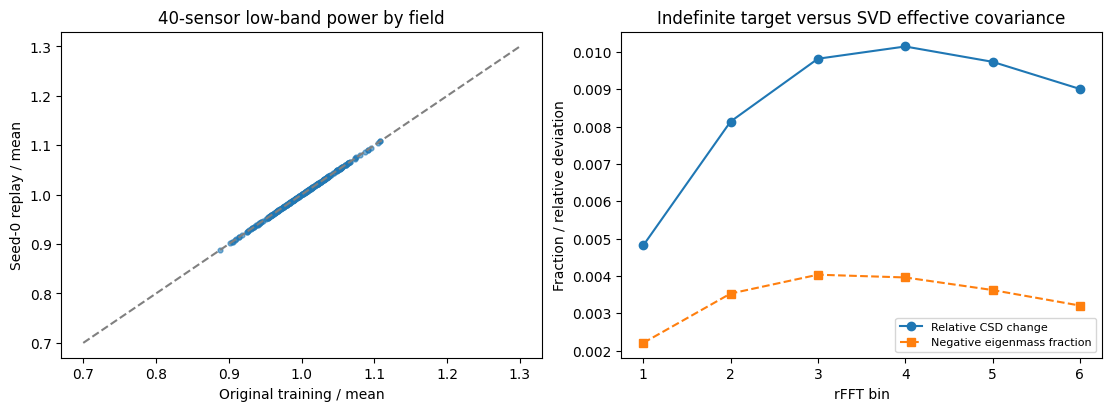

P33 SOURCE SEED REPLAY AND CSD FORENSICS
Original vs seed-0 replay complex FFT relative L2: 9.521160084784847e-14
Six per-bin complex relative L2 errors: [0.0, 0.0, 0.0, 0.0, 0.0, 0.0]
Observed vs replay fieldwise 40-sensor CV: 0.04245926216110472 0.042459262161104606
Observed vs replay per-field energy correlation: 0.9999999999999994
40-sensor across-frequency max absolute off-diagonal energy correlation: 0.1396060887327961
Bin 1: negative_eigs= 1, negative_mass=0.00220, CSD_relative_change=0.00482, coherence_max_delta=0.01831
Bin 2: negative_eigs= 1, negative_mass=0.00353, CSD_relative_change=0.00814, coherence_max_delta=0.02276
Bin 3: negative_eigs= 1, negative_mass=0.00403, CSD_relative_change=0.00982, coherence_max_delta=0.02510
Bin 4: negative_eigs= 1, negative_mass=0.00396, CSD_relative_change=0.01015, coherence_max_delta=0.02601
Bin 5: negative_eigs= 1, negative_mass=0.00362, CSD_relative_change=0.00974, coherence_max_delta=0.02598
Bin 6: negative_eigs= 1, negative_mass=0.00321

In [18]:
# CELL P33 — SOURCE-SEED REPLAY AND INDEFINITE-CSD FORENSICS
# Insert as ONE NEW code cell AFTER the successfully executed P32 cell in the
# NEW clean continuation notebook. Run ONLY P33; do not Run all.
# Reads the trusted training HDF5 and pinned NASA source. Does NOT train,
# install packages, regenerate datasets, read test data, or change P1-P32.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, subprocess, uuid
import numpy as np
import h5py
import matplotlib.pyplot as plt

p33_root = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
p33_repo = Path('/content/nasa_clfm_reference')
p33_train = Path('/content/clfm_snapshot/data/wind/wind_train_data.hdf5')
p33_p25 = p33_root/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149/result.json'
p33_p32 = p33_root/'fidelity_diagnostics/p32_source_phase_audit_20261102T162342Z_ac5eae/result.json'
p33_pin = '921e666c8d6060ae13bfd901dcc7f74f819d0eea'
p33_trusted_sha = '676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'

def p33_sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for chunk in iter(lambda: stream.read(8*1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

assert p33_root.is_dir() and p33_p25.is_file() and p33_p32.is_file()
assert p33_train.is_file() and p33_sha(p33_train)==p33_trusted_sha
assert subprocess.check_output(['git','-C',str(p33_repo),'rev-parse','HEAD'],text=True).strip()==p33_pin
p33_25 = json.loads(p33_p25.read_text())
p33_32 = json.loads(p33_p32.read_text())
assert p33_32['status']=='completed' and p33_32['pinned_nasa_commit']==p33_pin
assert p33_32['training_sha256']==p33_trusted_sha
for filename, expected in p33_32['pinned_source_sha256'].items():
    assert p33_sha(p33_repo/filename)==expected, 'Pinned source differs from P32.'
assert p33_25['status']=='completed' and len(p33_25['training_indices'])==256
p33_indices=np.asarray(p33_25['training_indices'],dtype=int)
assert len(np.unique(p33_indices))==256 and p33_indices.min()>=0 and p33_indices.max()<5000

# Only the recorded training cohort; read the original HDF5 precision (NOT
# P32's float32 surrogate) to make source-code replay comparison meaningful.
with h5py.File(p33_train,'r') as f:
    p33_coords=np.asarray(f['x_grid'],dtype=np.float64)
    p33_freq=np.asarray(f['input_parameters/freq_grid'],dtype=np.float64)
    p33_shear=float(np.asarray(f['input_parameters/shear_velocity']))
    assert p33_coords.shape==(100,3) and p33_freq.shape==(128,)
    assert len(f['wind_samples'])==5000
    p33_raw=np.stack([np.asarray(f['wind_samples'][str(int(i))]['v1'],dtype=np.float64)
                      for i in p33_indices],axis=0)
    assert p33_raw.shape==(256,100,256) and np.isfinite(p33_raw).all()
p33_obs=np.fft.rfft(p33_raw-p33_raw.mean(axis=-1,keepdims=True),axis=-1)[:,:,1:7]
p33_40=np.concatenate([np.arange(a,a+10) for a in (0,30,60,90)])

# Reconstruct the literal expressions in the pinned source. In particular:
# (a) shear_velocity is passed to a parameter named z_0 in L(z), and
# (b) '**5/3' evaluates as (x**5)/3, NOT as x**(5/3).
p33_source=(p33_repo/'data/wind_data_generation/wind_sampler.py').read_text()
p33_generate=(p33_repo/'data/wind_data_generation/generate_wind_data.py').read_text()
assert 'np.random.seed(0)' in p33_generate and 'num_samples = 5000' in p33_generate
assert 'SpectralRepresentation(' in p33_source and 'np.linalg.svd' not in p33_source
p33_z=p33_coords[:,2]
p33_mean=2.5*p33_shear*np.log(p33_z/0.015)
p33_var=(6-1.1*np.arctan(np.log(0.015)+1.75))*p33_shear**2
p33_L=300*(p33_z/200)**(0.67+0.05*np.log(p33_shear))
p33_dist=np.linalg.norm((p33_coords[:,None]-p33_coords[None,:])*
                       np.array([3.,3.,0.5]),axis=-1)
p33_B=[]
p33_csd_rows=[]
for k in range(1,7):
    f=p33_freq[k]
    auto=(p33_var*6.868*f*(p33_L/p33_mean))/(f*(1+1.5*f*6.868*p33_L/p33_mean)**5/3)
    coh=np.exp(-f*p33_dist/(p33_mean[:,None]+p33_mean[None,:]))
    S=np.sqrt(auto[:,None]*auto[None,:])*coh
    U,s,VH=np.linalg.svd(S,full_matrices=False)
    B=U*np.sqrt(s)[None,:]
    Seff=B@B.T
    eig=np.linalg.eigvalsh(S)
    neg=eig[eig< -1.e-9]
    dS=np.sqrt(np.diag(S)); dEff=np.sqrt(np.diag(Seff))
    corr_S=S/dS[:,None]/dS[None,:]
    corr_E=Seff/dEff[:,None]/dEff[None,:]
    p33_csd_rows.append(dict(bin=k,negative_eigenvalues=int(len(neg)),
        minimum_eigenvalue=float(eig[0]),
        negative_eigenmass_fraction=float(-neg.sum()/np.abs(eig).sum()),
        effective_vs_prescribed_relative_frobenius=float(np.linalg.norm(Seff-S)/np.linalg.norm(S)),
        effective_vs_prescribed_mean_diagonal_ratio=float(np.diag(Seff).mean()/np.diag(S).mean()),
        coherence_max_absolute_difference=float(np.max(np.abs(corr_E-corr_S)))))
    p33_B.append(B)
p33_B=np.asarray(p33_B)

# Replay the exact documented legacy RandomState(0) draw order for a
# 5000 x 128 x 100 phase array, in bounded chunks. Retain ONLY six phase
# bins for the same 256 train indices. No full SRM synthesis or new HDF5.
p33_rng=np.random.RandomState(0)
p33_phases=np.empty((256,6,100),dtype=np.float64)
p33_hit=np.zeros(256,dtype=bool)
for start in range(0,5000,16):
    stop=min(5000,start+16)
    block=p33_rng.random_sample((stop-start,128,100))
    selected=(p33_indices>=start)&(p33_indices<stop)
    if np.any(selected):
        p33_phases[selected]=block[p33_indices[selected]-start,1:7,:]
        p33_hit[selected]=True
assert np.all(p33_hit)

# UQpy _simulate_multi applies sqrt(4*delta_frequency) and a real-part FFT.
# For 1<=k<=6 with 128 input frequencies zero-padded to N=256, the rFFT
# coefficient is (256/2)*sqrt(4*dw)*CONJ(B[k] @ exp(i*phi[k])).
# The conjugation is essential: rFFT(real(FFT(c)))_k = (N/2)*conj(c_k)
# for nonzero positive bins whose negative-frequency input coefficient is 0.
p33_delta_f=float(p33_freq[1]-p33_freq[0])
p33_ampl=(256/2)*np.sqrt(4*p33_delta_f)
p33_pred=np.conj(np.einsum('kij,nkj->nik',p33_B,
             np.exp(2j*np.pi*p33_phases),optimize=True))*p33_ampl
assert p33_pred.shape==p33_obs.shape
p33_diff=p33_obs-p33_pred
p33_relative_error=float(np.linalg.norm(p33_diff)/np.linalg.norm(p33_obs))
p33_meanabs=float(np.mean(np.abs(p33_diff)))
p33_p99abs=float(np.quantile(np.abs(p33_diff),.99))
p33_maxabs=float(np.max(np.abs(p33_diff)))
p33_relative_by_bin=[float(np.linalg.norm(p33_diff[:,:,k])/np.linalg.norm(p33_obs[:,:,k]))
                     for k in range(6)]
p33_replay_matches=bool(p33_relative_error<1e-4 and max(p33_relative_by_bin)<1e-4)

# Separate 40-sensor, per-field comparison. A match here should follow
# automatically from the COMPLEX coefficient check, not substitute for it.
p33_energy_obs=np.mean(np.abs(p33_obs[:,p33_40,:])**2,axis=(1,2))
p33_energy_pred=np.mean(np.abs(p33_pred[:,p33_40,:])**2,axis=(1,2))
def p33_cv(x):
    return float(np.std(x,ddof=1)/np.mean(x))
p33_cv_emp=p33_cv(p33_energy_obs)
p33_cv_replay=p33_cv(p33_energy_pred)
p33_corr=float(np.corrcoef(p33_energy_obs,p33_energy_pred)[0,1])
p33_perbin=np.mean(np.abs(p33_obs[:,p33_40,:])**2,axis=1)
p33_perbin_corr=np.corrcoef(p33_perbin,rowvar=False)
p33_peak_offdiag=float(np.max(np.abs((p33_perbin_corr-np.eye(6))[np.triu_indices(6,1)])))

# Decision rules use COMPLEX coefficients; sample-CV compatibility alone
# cannot prove which historical UQpy version produced the HDF5.
if p33_replay_matches:
    p33_decision='DOCUMENTED_SEED0_PHASE_REPLAY_MATCHES_SIX_COMPLEX_BINS'
else:
    p33_decision='SEED0_PHASE_REPLAY_NOT_EXACT_SOURCE_VERSION_OR_DATA_PATH_UNRESOLVED'

# All writes only to a NEW dedicated P33 folder. Never write legacy files.
p33_run=p33_root/'fidelity_diagnostics'/('p33_seed_replay_csd_forensics_'+
     datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
assert p33_run.parent.resolve()==(p33_root/'fidelity_diagnostics').resolve()
p33_run.mkdir(parents=True,exist_ok=False)
p33_report=p33_run/'result.json'
p33_figure=p33_run/'source_seed_replay_and_csd.png'
p33_ledger=p33_run/'P33_RESEARCH_LEDGER_ADDENDUM.md'
p33_note=p33_run/'P33_PROVENANCE_NOTE.json'
p33_result=dict(experiment='P33_source_seed_replay_and_CSD_forensics',status='completed',
    created_utc=datetime.now(timezone.utc).isoformat(),decision=p33_decision,
    scope='training-only source forensics; NO independent evaluation',
    pinned_commit=p33_pin,training_sha256=p33_trusted_sha,
    reference_p32_path=str(p33_p32),reference_p32_sha256=p33_sha(p33_p32),
    p25_training_count=int(len(p33_indices)),
    replay_assumptions=['Pinned script seed 0, one UQpy-style array of 5000 x 128 x 100 independent uniform phases',
                        'UQpy v4.2.0 documented SVD + real part of zero-padded FFT',
                        'Six complex rFFT coefficients compared at original HDF5 precision'],
    six_complex_rfft_bins=dict(relative_l2_error=p33_relative_error,
        relative_l2_error_each_bin=p33_relative_by_bin,mean_absolute_error=p33_meanabs,
        p99_absolute_error=p33_p99abs,max_absolute_error=p33_maxabs,
        replay_matches_predeclared_tolerance=p33_replay_matches),
    sparse_field_energy=dict(original_cv=p33_cv_emp,seed0_replay_cv=p33_cv_replay,
         pairwise_correlation=p33_corr,p32_original_cv=float(p33_32['train_CV_40'])),
    cross_frequency=dict(observed_40_sensor_energy_correlation_matrix=p33_perbin_corr.tolist(),
         max_abs_offdiagonal_correlation=p33_peak_offdiag),
    prescribed_vs_effective_CSD=p33_csd_rows,
    limitations=['Matching six bins does not independently establish the exact historical UQpy package version.',
      'Failure to match exact complex coefficients may reflect SVD eigenbasis/sign conventions, software-version differences, or different training provenance.',
      'The CSD eigenvalue test concerns prescribed source matrices, not a proof of physically accurate wind turbulence.',
      'All observations use the 256 recorded training fields; no independent test has been accessed.',
      'No generator was fitted or evaluated in P33.'])
p33_report.write_text(json.dumps(p33_result,indent=2,allow_nan=False),encoding='utf-8')

fig,axs=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
axs[0].scatter(p33_energy_obs/p33_energy_obs.mean(),
   p33_energy_pred/p33_energy_pred.mean(),s=12,alpha=.6)
axs[0].plot([.7,1.3],[.7,1.3],linestyle='--',color='gray')
axs[0].set(xlabel='Original training / mean',ylabel='Seed-0 replay / mean',
           title='40-sensor low-band power by field')
axs[1].plot(range(1,7),[r['effective_vs_prescribed_relative_frobenius'] for r in p33_csd_rows],
            'o-',label='Relative CSD change')
axs[1].plot(range(1,7),[r['negative_eigenmass_fraction'] for r in p33_csd_rows],
            's--',label='Negative eigenmass fraction')
axs[1].set(xlabel='rFFT bin',ylabel='Fraction / relative deviation',
           title='Indefinite target versus SVD effective covariance')
axs[1].legend(fontsize=8)
fig.savefig(p33_figure,dpi=160)
plt.show();plt.close(fig)

p33_lines=[
 '# Wind VISION — P33 research ledger (next presentation only)',
 '',f'- Date (UTC): {datetime.now(timezone.utc).isoformat()}',
 '- P32 status: completed; original P32 report unchanged.',
 f'- P33 status: {p33_decision}',
 f'- Seed-0 complex-rFFT relative L2 mismatch: {p33_relative_error:.9g}',
 f'- Training 40-sensor low-band CV: {p33_cv_emp:.9g}',
 f'- Exact-phase replay 40-sensor CV: {p33_cv_replay:.9g}',
 f'- Number of tested prescribed indefinite matrices: {sum(r["negative_eigenvalues"]>0 for r in p33_csd_rows)} of 6',
 '- Distinguish UQpy implemented SVD covariance from physically prescribed CSD.',
 '- No unseen-data generalization claim and no new trained generator.',
 '- November 3 presentation artifacts unchanged.',
 '- Next decision: if complex replay matches, close source-provenance cause of P28 mismatch and design cross-frequency / spatial-dependency baseline; otherwise investigate reproducibility before modeling.'
]
p33_ledger.write_text('\n'.join(p33_lines)+'\n',encoding='utf-8')
p33_scope={p.name:p33_sha(p) for p in (p33_report,p33_figure,p33_ledger)}
p33_prov=dict(scope='NEW_P33_FOLDER_ONLY',created_utc=datetime.now(timezone.utc).isoformat(),
    evidence_sha256=p33_scope,p32_source_report_sha256=p33_sha(p33_p32),
    frozen_prior_experiments_unchanged_by_P33=True,historical_vault_not_scanned=True,
    decision=p33_decision)
with p33_note.open('x',encoding='utf-8') as f:
    json.dump(p33_prov,f,indent=2,allow_nan=False)
assert all((p33_run/name).is_file() and p33_sha(p33_run/name)==digest
           for name,digest in p33_scope.items())
assert p33_sha(p33_p32)==p33_prov['p32_source_report_sha256']
print('='*80)
print('P33 SOURCE SEED REPLAY AND CSD FORENSICS')
print('='*80)
print('Original vs seed-0 replay complex FFT relative L2:',p33_relative_error)
print('Six per-bin complex relative L2 errors:',np.round(p33_relative_by_bin,8).tolist())
print('Observed vs replay fieldwise 40-sensor CV:',p33_cv_emp,p33_cv_replay)
print('Observed vs replay per-field energy correlation:',p33_corr)
print('40-sensor across-frequency max absolute off-diagonal energy correlation:',p33_peak_offdiag)
for r in p33_csd_rows:
    print(f"Bin {r['bin']}: negative_eigs={r['negative_eigenvalues']:2d}, "
          f"negative_mass={r['negative_eigenmass_fraction']:.5f}, "
          f"CSD_relative_change={r['effective_vs_prescribed_relative_frobenius']:.5f}, "
          f"coherence_max_delta={r['coherence_max_absolute_difference']:.5f}")
print('P33 decision:',p33_decision)
print('P33 report:',p33_report)
print('P33 figure:',p33_figure)
print('P33 ledger:',p33_ledger)
print('P33 provenance:',p33_note)
print('P33 local scope verified:',len(p33_scope),'artifacts; P32 and older evidence not modified.')
print('NO TRAINING / NO TEST READ / NO HISTORICAL ARTIFACT OVERWRITE')


In [19]:
# [P34A removed — Superseded by sign-corrected diagnostics in P34C]

In [20]:
# [P34B removed — Superseded by sign-corrected diagnostics in P34C]

Reconstructed SVD factors: 32 /128
Reconstructed SVD factors: 64 /128
Reconstructed SVD factors: 96 /128
Reconstructed SVD factors: 128 /128
P34C-R low-band unsigned control: 9.844427749793981e-14
P34C-R holdout FFT bins 1..127: 1.0072022948696851e-13 high bins 7..127: 1.2326268227283243e-13
P34C-R max time-domain error: 4.320099833421409e-12 max per-bin error: 2.4192975626951894e-12
P34C-R bins with sign changes: 62


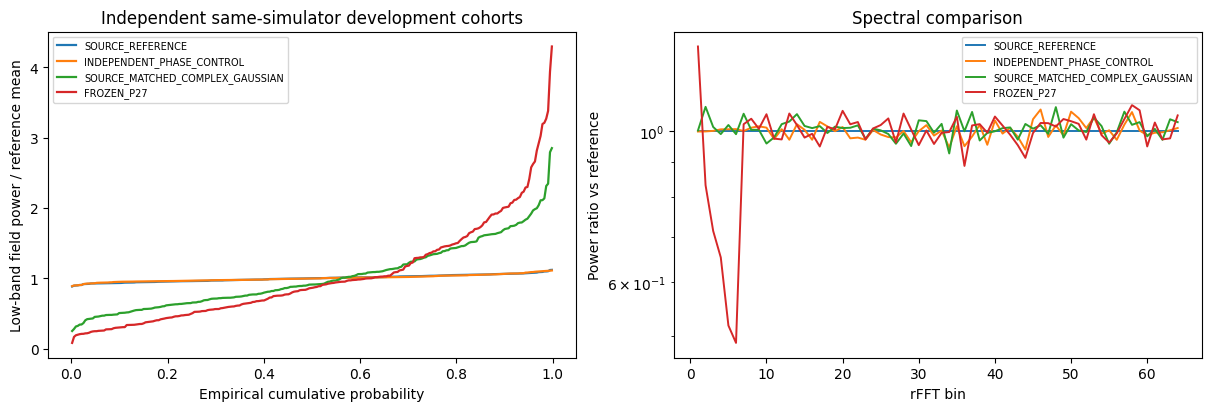


P34C-R COMPLETE — SIGNED SOURCE REPLAY / DEVELOPMENT COHORTS
Full replay: AC=1.007e-13, high=1.233e-13, max_time=4.320e-12
SOURCE_REFERENCE                   CV=0.048093 W1=0.00000 mid=1.0000 high=1.0000 adj=0.9851 strip=0.9134
INDEPENDENT_PHASE_CONTROL          CV=0.045381 W1=0.00501 mid=1.0035 high=1.0006 adj=0.9850 strip=0.9149
SOURCE_MATCHED_COMPLEX_GAUSSIAN    CV=0.465158 W1=0.34096 mid=1.0178 high=1.0054 adj=0.9836 strip=0.8857
FROZEN_P27                         CV=0.704717 W1=0.49815 mid=1.0210 high=1.0058 adj=0.9835 strip=0.9574
95% bootstrap CI, CV(candidate)-CV(source): INDEPENDENT_PHASE_CONTROL [-0.00759889540888388, 0.001907334004112196]
95% bootstrap CI, CV(candidate)-CV(source): SOURCE_MATCHED_COMPLEX_GAUSSIAN [0.3776687228738216, 0.45439483249412527]
95% bootstrap CI, CV(candidate)-CV(source): FROZEN_P27 [0.588427519289404, 0.7254842192320107]
Evidence folder: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p34c_standalone_replay_basel

In [21]:
# P34C-R — SELF-CONTAINED signed replay + same-simulator baseline comparison
# Place BELOW the failed P34C cell. Run THIS cell alone. Do not Run all.
# No dependency on old P34/P34A/P34B runtime variables or past notebook cells.
# Read-only inputs; only new evidence folder written after verification passes.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, subprocess, uuid, importlib.util
import numpy as np
import h5py
import matplotlib.pyplot as plt

root = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
repo = Path('/content/nasa_clfm_reference')
hdf = Path('/content/clfm_snapshot/data/wind/wind_train_data.hdf5')
pin = '921e666c8d6060ae13bfd901dcc7f74f819d0eea'
train_hash = '676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'
paths = {
 'P25':root/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149/result.json',
 'P27':root/'fidelity_diagnostics/p27_analytic_lowband_calibration_20261030T140550Z_c62259/result.json',
 'P32':root/'fidelity_diagnostics/p32_source_phase_audit_20261102T162342Z_ac5eae/result.json',
 'P33':root/'fidelity_diagnostics/p33_seed_replay_csd_forensics_20261102T163710Z_22fbc5/result.json'
}

def sha34r(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda:f.read(8*1024*1024), b''):
            digest.update(chunk)
    return digest.hexdigest()

assert root.is_dir(), 'Mount the original Drive and restore the research root.'
assert repo.is_dir() and (repo/'.git').is_dir(), 'Restore pinned checkout using clean notebook cell 5b.'
assert hdf.is_file(), 'Restore trusted training HDF5 using clean notebook cell 5b.'
assert all(p.is_file() for p in paths.values()), 'Saved P25/P27/P32/P33 report missing.'
assert sha34r(hdf) == train_hash, 'Trusted training HDF5 hash mismatch.'
assert subprocess.check_output(['git','-C',str(repo),'rev-parse','HEAD'],text=True).strip()==pin
reports = {k:json.loads(v.read_text()) for k,v in paths.items()}
assert reports['P33']['decision']=='DOCUMENTED_SEED0_PHASE_REPLAY_MATCHES_SIX_COMPLEX_BINS'
assert reports['P32']['training_sha256']==reports['P33']['training_sha256']==train_hash
for rel, digest in reports['P32']['pinned_source_sha256'].items():
    assert sha34r(repo/rel)==digest, f'Pinned source changed: {rel}'
assert reports['P27']['status']=='completed'
model = Path(reports['P27']['new_package'])
sampler = Path(reports['P27']['sampler_code'])
assert model.is_file() and sampler.is_file()
assert sha34r(model)==reports['P27']['new_package_sha256']
assert sha34r(sampler)==reports['P27']['sampler_code_sha256']
indices = np.sort(np.asarray(reports['P25']['training_indices'], dtype=int))
assert indices.shape==(256,) and len(np.unique(indices))==256 and 0<=indices[0]<indices[-1]<5000
replay_ids = indices[:12]  # training-only source provenance; 6 recovery / 6 check
saved_hashes = {k:sha34r(v) for k,v in paths.items()}
saved_hashes.update(P27_MODEL=sha34r(model),P27_SAMPLER=sha34r(sampler))

with h5py.File(hdf,'r') as f:
    assert len(f['wind_samples'])==5000
    coords=np.asarray(f['x_grid'],dtype=np.float64)
    freq=np.asarray(f['input_parameters/freq_grid'],dtype=np.float64)
    shear=float(np.asarray(f['input_parameters/shear_velocity']))
    raw=np.stack([np.asarray(f['wind_samples'][str(int(i))]['v1'],dtype=np.float64)
                  for i in replay_ids])
assert coords.shape==(100,3) and freq.shape==(128,) and raw.shape==(12,100,256)
assert np.allclose(freq,np.linspace(3/128,3,128)) and abs(shear-1.9)<1e-12
assert np.isfinite(raw).all()

# Literal behavior of pinned wind_sampler.py (including its unusual **5/3
# operator precedence and its shear_velocity -> length-scale parameter).
height=coords[:,2]
mean=2.5*shear*np.log(height/0.015)
variance=(6-1.1*np.arctan(np.log(0.015)+1.75))*shear**2
length=300*(height/200)**(0.67+0.05*np.log(shear))
distance=np.linalg.norm((coords[:,None,:]-coords[None,:,:])*[3.,3.,0.5],axis=-1)
B=np.empty((128,100,100),dtype=np.float64)
for k,fr in enumerate(freq):
    auto=(variance*6.868*fr*(length/mean))/(fr*(1+1.5*fr*6.868*length/mean)**5/3)
    coh=np.exp(-fr*distance/(mean[:,None]+mean[None,:]))
    S=np.sqrt(auto[:,None]*auto[None,:])*coh
    U,s,_=np.linalg.svd(S,full_matrices=False)
    B[k]=U*np.sqrt(s)[None,:]
    if k in (31,63,95,127):print('Reconstructed SVD factors:',k+1,'/128')
assert np.isfinite(B).all()
sel=np.concatenate([np.arange(j,j+10) for j in (0,30,60,90)])
scale=np.sqrt(4*float(freq[1]-freq[0]))

def assemble(q,basis,mean_sensors):
    # UQpy real(FFT(zero-padded coefficients, N=256)) in rFFT form.
    co=scale*np.einsum('nkj,ksj->nsk',q,basis,optimize=True)
    fft=np.zeros((len(q),len(mean_sensors),129),dtype=np.complex128)
    fft[:,:,0]=256*co[:,:,0].real
    fft[:,:,1:128]=128*np.conj(co[:,:,1:128])
    return mean_sensors[None,:,None]+np.fft.irfft(fft,n=256,axis=-1)

# Recover RandomState(0) phases for 12 historical training samples ONLY.
rs=np.random.RandomState(0)
phi=np.empty((12,128,100),dtype=np.float64)
seen=np.zeros(12,dtype=bool)
for start in range(0,5000,16):
    stop=min(start+16,5000)
    block=rs.random_sample((stop-start,128,100))
    take=np.where((replay_ids>=start)&(replay_ids<stop))[0]
    if len(take):
        phi[take]=block[replay_ids[take]-start]
        seen[take]=True
assert seen.all()
z=np.exp(2j*np.pi*phi)
Fobs=np.fft.rfft(raw,axis=-1)

# Verify established P33 low bins before inferring any signs.
F6=np.conj(np.einsum('nkj,ksj->nsk',z[:,1:7],B[1:7],optimize=True))*128*scale
low_error=float(np.linalg.norm(Fobs[:,:,1:7]-F6)/np.linalg.norm(Fobs[:,:,1:7]))
assert low_error<1e-10, f'P33 low-band replay fails: {low_error}'

# Each B_k has orthogonal columns. Project six historical fields on B_k
# to estimate sign per column; check on six DIFFERENT historical fields.
Y=np.conj(Fobs[:,:,1:128]).transpose(0,2,1)/(128*scale)
col2=np.sum(B**2,axis=1)
qhat=np.einsum('nks,ksj->nkj',Y[:6],B[1:128],optimize=True) / np.maximum(col2[None,1:128,:],1e-300)
scores=np.mean((qhat*np.conj(z[:6,1:128,:])).real,axis=0)
signs=np.ones((128,100),dtype=float)
signs[1:128]=np.where(scores<0,-1.,1.)

# DC is real-valued and its source input is nonzero (source frequency index 0).
Y0=(Fobs[:6,:,0].real-256*mean[None,:])/(256*scale)
q0=(Y0@B[0])/np.maximum(col2[0],1e-300)
cos0=z[:6,0,:].real
s0=np.sum(q0*cos0,axis=0)/np.maximum(np.sum(cos0**2,axis=0),1e-300)
signs[0]=np.where(s0<0,-1.,1.)
Bhistorical=B*signs[:,None,:]   # For replay provenance ONLY.
replay=assemble(z,Bhistorical,mean)
Fpred=np.fft.rfft(replay,axis=-1)

def rel(a,b):return float(np.linalg.norm(a-b)/max(np.linalg.norm(a),1e-300))
err_all=rel(Fobs[6:,:,1:128],Fpred[6:,:,1:128])
err_hi=rel(Fobs[6:,:,7:128],Fpred[6:,:,7:128])
err_time=float(np.max(np.abs(raw[6:]-replay[6:])))
per_bin=[rel(Fobs[6:,:,k],Fpred[6:,:,k]) for k in range(1,128)]
flips=np.sum(signs<0,axis=1).astype(int)
print('P34C-R low-band unsigned control:',low_error)
print('P34C-R holdout FFT bins 1..127:',err_all,'high bins 7..127:',err_hi)
print('P34C-R max time-domain error:',err_time,'max per-bin error:',max(per_bin))
print('P34C-R bins with sign changes:',int(np.count_nonzero(flips)))
assert err_all<1e-8 and err_hi<1e-8 and err_time<1e-8 and max(per_bin)<1e-8, (
    'Historical replay not explained by signs in all bins; do not generate cohorts.',
    err_all,err_hi,err_time,max(per_bin))

# Fresh development cohorts: do NOT use Bhistorical, training phases,
# designated test seed=1, or any evaluation-based fitted calibration.
N=256
B40=B[:,sel,:]
def source_sample(seed,gaussian=False):
    rng=np.random.default_rng(seed)
    if gaussian:
        q=(rng.standard_normal((N,128,100))+1j*rng.standard_normal((N,128,100)))/np.sqrt(2)
    else:
        q=np.exp(2j*np.pi*rng.random((N,128,100)))
    x=assemble(q,B40,mean[sel])
    return (x+2.)/49.

ref=source_sample(340101)
phase=source_sample(340201)
gauss=source_sample(340301,gaussian=True)
spec=importlib.util.spec_from_file_location('p34cr_frozen_p27',str(sampler))
module=importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)
p27=np.asarray(module.generate(model,n=N,seed=340401,calibrated=True),dtype=np.float64)
cohorts={'SOURCE_REFERENCE':ref,'INDEPENDENT_PHASE_CONTROL':phase,
         'SOURCE_MATCHED_COMPLEX_GAUSSIAN':gauss,'FROZEN_P27':p27}
assert all(v.shape==(N,40,256) and np.isfinite(v).all() for v in cohorts.values())

def stats(x):
    d=x-x.mean(axis=-1,keepdims=True)
    power=np.abs(np.fft.rfft(d,axis=-1))**2
    e=power[:,:,1:7].mean(axis=(1,2))
    pairs=np.asarray([i for i in range(39) if i%10 !=9]); x1=d[:,pairs];x2=d[:,pairs+1]
    adj=np.mean(np.sum(x1*x2,axis=-1)/np.maximum(np.linalg.norm(x1,axis=-1)*np.linalg.norm(x2,axis=-1),1e-20))
    strip_a=d[:,:10];strip_b=d[:,10:20]
    strip=np.mean(np.sum(strip_a*strip_b,axis=-1)/np.maximum(np.linalg.norm(strip_a,axis=-1)*np.linalg.norm(strip_b,axis=-1),1e-20))
    lowbins=power[:,:,1:7].mean(axis=1)
    cross=np.corrcoef(lowbins,rowvar=False)[np.triu_indices(6,1)]
    return {'e':e,'psd':power.mean(axis=(0,1)),'cv':float(e.std(ddof=1)/e.mean()),
            'low_mean':float(e.mean()),'temporal_var':float(np.mean(d*d)),
            'field_var':float(np.mean(np.var(x,axis=0,ddof=1))),
            'adjacent_corr':float(adj),'strip_corr':float(strip),
            'cross_freq_max_abs_r':float(np.max(np.abs(cross))),
            'increment_p99_ms':float(np.quantile(np.abs(np.diff(x,axis=-1))*49,.99)),
            'velocity_mean_ms':float((x*49-2).mean()),
            'velocity_range_ms':[float((x*49-2).min()),float((x*49-2).max())],
            'bound_exceedance_fraction':float(np.mean((x*49-2 < -2)|(x*49-2 > 47)))}

summaries={name:stats(x) for name,x in cohorts.items()}
base=summaries['SOURCE_REFERENCE']
rows=[]
for name,s in summaries.items():
    rows.append({'cohort':name,'n':N,'cv':s['cv'],
                 'low_power_mean_ratio':s['low_mean']/base['low_mean'],
                 'low_power_W1_ratio':float(np.mean(np.abs(np.sort(s['e'])-np.sort(base['e'])))/base['low_mean']),
                 'psd_7_16_ratio':float(s['psd'][7:17].mean()/base['psd'][7:17].mean()),
                 'psd_17_64_ratio':float(s['psd'][17:65].mean()/base['psd'][17:65].mean()),
                 'temporal_variance_ratio':s['temporal_var']/base['temporal_var'],
                 'between_field_variance_ratio':s['field_var']/base['field_var'],
                 'adjacent_corr':s['adjacent_corr'],'strip_corr':s['strip_corr'],
                 'cross_freq_max_abs_r':s['cross_freq_max_abs_r'],
                 'increment_p99_ms':s['increment_p99_ms'],
                 'velocity_mean_ms':s['velocity_mean_ms'],
                 'velocity_range_ms':s['velocity_range_ms'],
                 'bound_exceedance_fraction':s['bound_exceedance_fraction']})
boot=np.random.default_rng(340901)
intervals={}
for name,s in summaries.items():
    if name=='SOURCE_REFERENCE':continue
    diffs=[]
    for _ in range(400):
        a=s['e'][boot.integers(N,size=N)];b=base['e'][boot.integers(N,size=N)]
        diffs.append(float(a.std(ddof=1)/a.mean()-b.std(ddof=1)/b.mean()))
    intervals[name]=[float(v) for v in np.quantile(diffs,[.025,.975])]

# Only now create a new unique experiment folder. Preserve P1..P33 and
# the historical P34 failure; do not touch the Nov 3 presentation.
for label,path in paths.items():assert sha34r(path)==saved_hashes[label],f'{label} changed during experiment'
assert sha34r(model)==saved_hashes['P27_MODEL'] and sha34r(sampler)==saved_hashes['P27_SAMPLER']
run=root/'fidelity_diagnostics'/('p34c_standalone_replay_baselines_'+
    datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
assert run.parent.resolve()==(root/'fidelity_diagnostics').resolve()
run.mkdir(parents=True,exist_ok=False)
report=run/'result.json';figure=run/'development_comparison.png'
ledger=run/'P34C_RESEARCH_LEDGER_ADDENDUM.md';prov=run/'P34C_PROVENANCE_NOTE.json'
result={'experiment':'P34C-R_standalone_signed_replay_and_development_cohorts',
 'status':'completed','created_utc':datetime.now(timezone.utc).isoformat(),
 'training_sha256':train_hash,'pinned_commit':pin,'input_report_sha256':saved_hashes,
 'source_replay':{'training_fields_for_sign_recovery':6,'other_training_fields_for_replay_check':6,
     'low_bin_original_factor_error':low_error,'signed_replay_ac_error':err_all,
     'signed_replay_high_error':err_hi,'signed_replay_time_max_abs':err_time,
     'signed_replay_max_per_bin_error':max(per_bin),'flips_per_bin':flips.tolist()},
 'development_seeds':{'reference':340101,'phase_control':340201,'gaussian_control':340301,
                      'frozen_p27':340401,'bootstrap':340901},
 'new_samples_use_original_unsigned_factors':True,
 'same_simulator_development_cohorts_not_prospective_test':True,
 'fields_per_cohort':N,'metrics':rows,'cv_difference_bootstrap95':intervals,
 'limitations':['Historical signs inferred ONLY for deterministic training-source replay.',
    'No test HDF5 accessed; prospective seed 1 reserved.',
    'Independent draws are from one known synthetic simulator, not unseen physical conditions.',
    'Phase-only source cohort is a positive control, not a learned model.',
    'P27 is frozen fitted statistical sampler, not the original c-LFM flow.',
    'CV bootstrap describes sample uncertainty, not model-selection uncertainty.',
    'Historical UQpy distribution mechanism is replicated but package version still unverified.']}
report.write_text(json.dumps(result,indent=2,allow_nan=False),encoding='utf-8')
fig,axes=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for name,s in summaries.items():
    axes[0].plot((np.arange(N)+0.5)/N,np.sort(s['e']/base['low_mean']),label=name,lw=1.6)
    axes[1].plot(np.arange(1,65),s['psd'][1:65]/base['psd'][1:65],label=name,lw=1.4)
axes[0].set(xlabel='Empirical cumulative probability',ylabel='Low-band field power / reference mean',
            title='Independent same-simulator development cohorts')
axes[1].set(xlabel='rFFT bin',ylabel='Power ratio vs reference',yscale='log',
            title='Spectral comparison')
axes[0].legend(fontsize=7);axes[1].legend(fontsize=7)
fig.savefig(figure,dpi=150);plt.show();plt.close(fig)
ledger.write_text('# P34C-R — Source-aware development comparison (after P33)\n\n'
  + f'- P34 original preflight failed due to numerical SVD column-sign convention.\n'
  + f'- P34B training-only diagnostic showed sign-only differences in 20 selected bins.\n'
  + f'- P34C-R full 128-bin sign-corrected replay on 6 separate training fields: {err_all:.9g} relative AC error.\n'
  + '- Four 256-field development cohorts from predetermined, non-test seeds.\n'
  + '- New source samples use unmodified SVD factors. No model fitting or older evidence changes.\n'
  + '- See result.json for statistics, uncertainty, and limitations.\n',encoding='utf-8')
art={p.name:sha34r(p) for p in (report,figure,ledger)}
prov.write_text(json.dumps({'scope':'P34C-R_NEW_FOLDER_ONLY','artifacts_sha256':art,
                            'previous_inputs_sha256':saved_hashes,'vault_not_scanned':True},indent=2),encoding='utf-8')
assert all(sha34r(run/name)==digest for name,digest in art.items())
print('\n'+'='*82+'\nP34C-R COMPLETE — SIGNED SOURCE REPLAY / DEVELOPMENT COHORTS\n'+'='*82)
print(f'Full replay: AC={err_all:.3e}, high={err_hi:.3e}, max_time={err_time:.3e}')
for x in rows:
    print(f"{x['cohort']:34s} CV={x['cv']:.6f} W1={x['low_power_W1_ratio']:.5f} "
          f"mid={x['psd_7_16_ratio']:.4f} high={x['psd_17_64_ratio']:.4f} "
          f"adj={x['adjacent_corr']:.4f} strip={x['strip_corr']:.4f}")
for k,v in intervals.items():print('95% bootstrap CI, CV(candidate)-CV(source):',k,v)
print('Evidence folder:',run)
print('No source/model training, no seed-1 test data, no historical-file overwrites.')

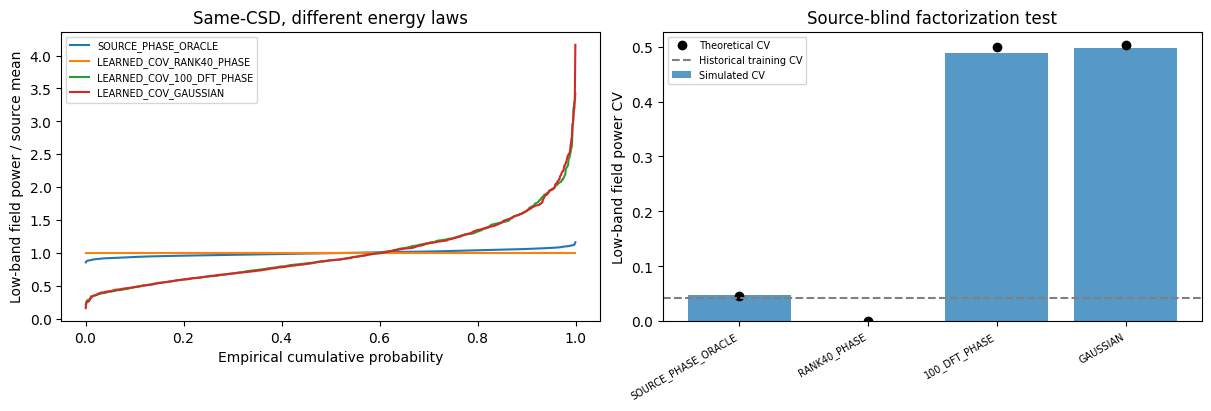


P35 — SOURCE-BLIND COVARIANCE FACTORIZATION / FOURTH-ORDER IDENTIFIABILITY
P25 training low-band CV: 0.042459262161104724
New source-phase positive-control CV: 0.047071510976009895
Common fitted CSD relative deviation from source: 0.036495268691180735
Rank40 vs DFT100 fitted-CSD maximum difference: 8.526512829121202e-14
SOURCE_PHASE_ORACLE              CV_sim=0.047072 CV_theory=0.046504 W1=0.00000 popCSDerr=0.0000 sampleCSDerr=0.0135
LEARNED_COV_RANK40_PHASE         CV_sim=0.000000 CV_theory=0.000000 W1=0.03774 popCSDerr=0.0365 sampleCSDerr=0.0350
LEARNED_COV_100_DFT_PHASE        CV_sim=0.488134 CV_theory=0.498968 W1=0.33609 popCSDerr=0.0365 sampleCSDerr=0.0489
LEARNED_COV_GAUSSIAN             CV_sim=0.498137 CV_theory=0.502157 W1=0.33829 popCSDerr=0.0365 sampleCSDerr=0.0382
CV difference 95% bootstrap CI: LEARNED_COV_RANK40_PHASE [-0.048822, -0.045292]
CV difference 95% bootstrap CI: LEARNED_COV_100_DFT_PHASE [0.417407, 0.467657]
CV difference 95% bootstrap CI: LEARNED_COV_GAUSSIAN [

In [22]:

# CELL P35 — Source-blind spectral-factor identifiability
# Insert BELOW completed P34C-R. Run THIS cell only.
# No optimizer training, no historical overwrites, no test seed=1.

from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, subprocess, uuid
import numpy as np
import h5py
import matplotlib.pyplot as plt

P35_ROOT = Path(
    '/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1'
)
P35_REPO = Path('/content/nasa_clfm_reference')
P35_HDF = Path(
    '/content/clfm_snapshot/data/wind/wind_train_data.hdf5'
)
P35_PIN = '921e666c8d6060ae13bfd901dcc7f74f819d0eea'
P35_HDF_SHA = (
    '676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'
)

P35_P25 = P35_ROOT / (
    'fidelity_diagnostics/'
    'p25_reusable_generator_20261030T131833Z_6e7149/result.json'
)
P35_P32 = P35_ROOT / (
    'fidelity_diagnostics/'
    'p32_source_phase_audit_20261102T162342Z_ac5eae/result.json'
)
P35_P33 = P35_ROOT / (
    'fidelity_diagnostics/'
    'p33_seed_replay_csd_forensics_20261102T163710Z_22fbc5/result.json'
)
P35_P34 = P35_ROOT / (
    'fidelity_diagnostics/'
    'p34c_standalone_replay_baselines_20261102T183830Z_02e2e8/result.json'
)

def p35_sha(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda: f.read(8*1024*1024), b''):
            h.update(block)
    return h.hexdigest()

p35_files = {
    'P25': P35_P25,
    'P32': P35_P32,
    'P33': P35_P33,
    'P34C-R': P35_P34
}

assert P35_ROOT.is_dir() and P35_REPO.is_dir(), (
    'Mount Drive and restore pinned source using clean notebook Cell 5b.'
)
assert all(
    p.is_file()
    for p in list(p35_files.values()) + [P35_HDF]
)

p35_prior_sha = {
    k: p35_sha(v) for k, v in p35_files.items()
}

assert p35_sha(P35_HDF) == P35_HDF_SHA
assert subprocess.check_output(
    ['git', '-C', str(P35_REPO), 'rev-parse', 'HEAD'],
    text=True
).strip() == P35_PIN

p35_rep = {
    k: json.loads(p.read_text())
    for k, p in p35_files.items()
}

assert p35_rep['P33']['decision'] == (
    'DOCUMENTED_SEED0_PHASE_REPLAY_MATCHES_SIX_COMPLEX_BINS'
)
assert p35_rep['P34C-R']['status'] == 'completed'
assert p35_rep['P34C-R']['new_samples_use_original_unsigned_factors'] is True
assert p35_rep['P34C-R']['source_replay']['signed_replay_ac_error'] < 1e-8
assert p35_rep['P32']['training_sha256'] == P35_HDF_SHA

for rel, expected_sha in p35_rep['P32']['pinned_source_sha256'].items():
    assert p35_sha(P35_REPO / rel) == expected_sha, (
        f'Pinned NASA source changed: {rel}'
    )

# ---------------------------------------------------------
# 1. Fit from the SAME 256 P25 training fields, 40 sensors.
# ---------------------------------------------------------

p35_ids = np.asarray(
    p35_rep['P25']['training_indices'], dtype=int
)
p35_sel = np.concatenate([
    np.arange(i, i+10) for i in (0, 30, 60, 90)
])

assert p35_ids.shape == (256,)
assert len(np.unique(p35_ids)) == 256
assert p35_ids.min() >= 0 and p35_ids.max() < 5000

with h5py.File(P35_HDF, 'r') as f:
    assert len(f['wind_samples']) == 5000
    p35_coords = np.asarray(f['x_grid'], dtype=np.float64)
    p35_freq = np.asarray(
        f['input_parameters/freq_grid'], dtype=np.float64
    )
    p35_shear = float(np.asarray(
        f['input_parameters/shear_velocity']
    ))
    p35_train = np.stack([
        np.asarray(
            f['wind_samples'][str(int(i))]['v1'],
            dtype=np.float64
        )[p35_sel, :]
        for i in p35_ids
    ])

assert p35_train.shape == (256, 40, 256)
assert np.isfinite(p35_train).all()
assert p35_coords.shape == (100, 3)
assert p35_freq.shape == (128,)
assert np.allclose(p35_freq, np.linspace(3/128, 3, 128))
assert abs(p35_shear - 1.9) < 1e-12

# Match P32/P34 low-band power statistic.
p35_F = np.fft.rfft(
    p35_train - p35_train.mean(axis=-1, keepdims=True),
    axis=-1
)[:, :, 1:7] / 49.0

p35_X = p35_F.transpose(0, 2, 1).copy()

# Fit six 40x40 complex Hermitian covariance matrices.
p35_C = np.einsum(
    'nks,nkt->kst',
    p35_X, p35_X.conj(),
    optimize=True
) / 256.0

p35_C = 0.5 * (
    p35_C + p35_C.conj().transpose(0, 2, 1)
)

p35_L = np.empty((6, 40, 40), dtype=np.complex128)

for k in range(6):
    vals, vecs = np.linalg.eigh(p35_C[k])
    vals = np.maximum(vals, 0.0)
    p35_L[k] = vecs * np.sqrt(vals)[None, :]

assert np.allclose(
    p35_L @ p35_L.conj().transpose(0, 2, 1),
    p35_C,
    rtol=1e-10, atol=1e-10
)

# ---------------------------------------------------------
# 2. Covariance-preserving 100-phase Fourier frame.
# ---------------------------------------------------------

p35_i = np.arange(40)[:, None]
p35_j = np.arange(100)[None, :]

p35_Q = np.exp(
    -2j*np.pi*p35_i*p35_j/100.0
) / np.sqrt(100.0)

assert np.max(np.abs(
    p35_Q @ p35_Q.conj().T - np.eye(40)
)) < 1e-12

p35_L100 = np.einsum(
    'kij,jl->kil', p35_L, p35_Q, optimize=True
)

assert np.allclose(
    p35_L100 @ p35_L100.conj().transpose(0, 2, 1),
    p35_C,
    rtol=1e-10, atol=1e-10
)

# ---------------------------------------------------------
# 3. Reconstruct source factors ONLY for positive control.
#    Never use these factors to fit the learned candidates.
# ---------------------------------------------------------

z = p35_coords[:, 2]
mu = 2.5*p35_shear*np.log(z/0.015)

var = (
    6.0 - 1.1*np.arctan(np.log(0.015)+1.75)
) * p35_shear**2

Lscale = 300.0*(z/200.0)**(
    0.67 + 0.05*np.log(p35_shear)
)

distance = np.linalg.norm(
    (p35_coords[:, None, :] - p35_coords[None, :, :])
    * [3., 3., 0.5],
    axis=-1
)

source_B = np.empty((6, 40, 100), dtype=np.float64)

for ki, k in enumerate(range(1, 7)):
    nu = p35_freq[k]

    # Preserve literal pinned-source behavior:
    # **5 / 3, not **(5/3).
    auto = (
        var*6.868*nu*(Lscale/mu)
    ) / (
        nu*(1+1.5*nu*6.868*Lscale/mu)**5/3
    )

    coherence = np.exp(
        -nu*distance/(mu[:, None]+mu[None, :])
    )

    S = np.sqrt(
        auto[:, None]*auto[None, :]
    ) * coherence

    U, s, _ = np.linalg.svd(
        S, full_matrices=False
    )

    source_B[ki] = (
        U*np.sqrt(s)[None, :]
    )[p35_sel, :]

p35_factor_scale = (
    128.0*np.sqrt(4.0*(p35_freq[1]-p35_freq[0]))
) / 49.0

source_B *= p35_factor_scale
source_cov = source_B @ source_B.transpose(0, 2, 1)

# ---------------------------------------------------------
# 4. Exact theoretical field-energy CV for each factor.
# ---------------------------------------------------------

def p35_theory(A, gaussian=False):
    H = np.einsum(
        'ksj,ksl->kjl',
        A.conj(), A,
        optimize=True
    )

    total = np.sum(
        np.trace(H, axis1=1, axis2=2)
    ).real

    if gaussian:
        var_ = np.sum(np.abs(H)**2).real
    else:
        off = H.copy()
        j = np.arange(H.shape[1])
        off[:, j, j] = 0
        var_ = np.sum(np.abs(off)**2).real

    return float(
        np.sqrt(max(0.0, var_)) / total
    )

# ---------------------------------------------------------
# 5. Fresh, fixed-seed development cohorts.
# ---------------------------------------------------------

N35 = 1024

rng_source = np.random.default_rng(350101)
rng40 = np.random.default_rng(350201)
rng100 = np.random.default_rng(350301)
rngg = np.random.default_rng(350401)

Zs = np.exp(
    2j*np.pi*rng_source.random((N35, 6, 100))
)
Z40 = np.exp(
    2j*np.pi*rng40.random((N35, 6, 40))
)
Z100 = np.exp(
    2j*np.pi*rng100.random((N35, 6, 100))
)
Zg = (
    rngg.standard_normal((N35, 6, 40))
    + 1j*rngg.standard_normal((N35, 6, 40))
) / np.sqrt(2.0)

cohorts35 = {
    'SOURCE_PHASE_ORACLE': np.conj(
        np.einsum(
            'ksj,nkj->nks',
            source_B, Zs,
            optimize=True
        )
    ),

    'LEARNED_COV_RANK40_PHASE': np.einsum(
        'ksj,nkj->nks',
        p35_L, Z40,
        optimize=True
    ),

    'LEARNED_COV_100_DFT_PHASE': np.einsum(
        'ksj,nkj->nks',
        p35_L100, Z100,
        optimize=True
    ),

    'LEARNED_COV_GAUSSIAN': np.einsum(
        'ksj,nkj->nks',
        p35_L, Zg,
        optimize=True
    )
}

assert all(
    v.shape == (N35, 6, 40)
    and np.isfinite(v).all()
    for v in cohorts35.values()
)

# ---------------------------------------------------------
# 6. Metrics and analytic covariance checks.
# ---------------------------------------------------------

def p35_energy(X):
    return np.mean(np.abs(X)**2, axis=(1, 2))

def p35_cv(a):
    return float(
        np.std(a, ddof=1) / np.mean(a)
    )

def p35_csd(X):
    return np.einsum(
        'nks,nkt->kst',
        X, X.conj(),
        optimize=True
    ) / len(X)

def p35_rel(A, B):
    return float(
        np.linalg.norm(A-B)
        / max(np.linalg.norm(B), 1e-300)
    )

def p35_coherence(C):
    d = np.maximum(
        np.diagonal(
            C, axis1=1, axis2=2
        ).real,
        1e-300
    )

    return C / np.sqrt(
        d[:, :, None]*d[:, None, :]
    )

p35_train_E = p35_energy(p35_X)

p35_energies = {
    key: p35_energy(value)
    for key, value in cohorts35.items()
}

ref_E = p35_energies['SOURCE_PHASE_ORACLE']
ref_mean = ref_E.mean()
p35_coh_ref = p35_coherence(source_cov)

factors35 = {
    'SOURCE_PHASE_ORACLE': source_B,
    'LEARNED_COV_RANK40_PHASE': p35_L,
    'LEARNED_COV_100_DFT_PHASE': p35_L100,
    'LEARNED_COV_GAUSSIAN': p35_L
}

rows35 = []

for name, X in cohorts35.items():
    energy = p35_energies[name]
    sample_C = p35_csd(X)

    population_C = np.einsum(
        'ksj,ktj->kst',
        factors35[name],
        factors35[name].conj(),
        optimize=True
    )

    rows35.append(dict(
        name=name,

        simulated_cv=p35_cv(energy),

        theoretical_cv=p35_theory(
            factors35[name],
            gaussian=(name == 'LEARNED_COV_GAUSSIAN')
        ),

        low_mean_ratio=float(
            np.mean(energy)/ref_mean
        ),

        energy_W1_over_ref_mean=float(
            np.mean(np.abs(
                np.sort(energy)-np.sort(ref_E)
            ))/ref_mean
        ),

        sample_CSD_frobenius_error_vs_source=(
            p35_rel(sample_C, source_cov)
        ),

        population_CSD_error_vs_source=(
            p35_rel(population_C, source_cov)
        ),

        sample_max_abs_complex_coherence_diff_vs_source=(
            float(np.max(np.abs(
                p35_coherence(sample_C)-p35_coh_ref
            )))
        ),

        p05_p50_p95_energy_over_reference_mean=(
            np.quantile(
                energy, [.05, .50, .95]
            )/ref_mean
        ).tolist()
    ))

# ---------------------------------------------------------
# 7. Bootstrap CV differences.
# ---------------------------------------------------------

btr = np.random.default_rng(350901)
ci35 = {}

for name, energy in p35_energies.items():
    if name == 'SOURCE_PHASE_ORACLE':
        continue

    differences = np.empty(600)

    for b in range(600):
        a = energy[
            btr.integers(N35, size=N35)
        ]
        r = ref_E[
            btr.integers(N35, size=N35)
        ]

        differences[b] = (
            p35_cv(a)-p35_cv(r)
        )

    ci35[name] = np.quantile(
        differences, [.025, .975]
    ).tolist()

# ---------------------------------------------------------
# 8. Verify originals and create NEW P35 evidence folder.
# ---------------------------------------------------------

assert p35_sha(P35_HDF) == P35_HDF_SHA

assert all(
    p35_sha(p35_files[k]) == v
    for k, v in p35_prior_sha.items()
)

run35 = P35_ROOT/'fidelity_diagnostics'/(
    'p35_source_blind_factor_identifiability_'
    + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    + '_' + uuid.uuid4().hex[:6]
)

assert run35.parent.resolve() == (
    P35_ROOT/'fidelity_diagnostics'
).resolve()

run35.mkdir(parents=True, exist_ok=False)

report35 = run35/'result.json'
fig35 = run35/'factor_identifiability.png'
ledger35 = run35/'P35_LEDGER_ADDENDUM.md'
prov35 = run35/'P35_PROVENANCE_NOTE.json'

out35 = dict(
    experiment=(
        'P35_source_blind_covariance_vs_fourth_order_identifiability'
    ),
    status='completed',
    created_utc=datetime.now(timezone.utc).isoformat(),

    p25_training_cohort_n=256,
    p25_training_sensors=40,
    evaluated_rfft_bins=[1,2,3,4,5,6],
    development_fields_per_cohort=N35,

    seeds=dict(
        reference=350101,
        rank40_phase=350201,
        dft100_phase=350301,
        gaussian=350401,
        bootstrap=350901
    ),

    train_energy_cv=p35_cv(p35_train_E),
    source_reference_energy_cv=p35_cv(ref_E),

    common_fitted_covariance_rel_error_vs_source=(
        p35_rel(p35_C, source_cov)
    ),

    rank40_vs_dft100_model_covariance_max_abs_difference=(
        float(np.max(np.abs(
            p35_L @ p35_L.conj().transpose(0,2,1)
            - p35_L100 @ p35_L100.conj().transpose(0,2,1)
        )))
    ),

    comparisons=rows35,
    bootstrap_CV_difference_95=ci35,

    inputs_sha256={
        **p35_prior_sha,
        'training_HDF5': P35_HDF_SHA
    },

    pinned_source_commit=P35_PIN,

    limitations=[
        'Source-positive control uses known NASA source matrices; learned candidates do not.',
        'Candidate covariance fitted using P25 256 training samples at 40 sensors, six frequencies.',
        'This is a spectral coefficient diagnostic, not a full wind-field generator or PhysicsNeMo training.',
        'Rank-40 phase factor forces fixed total sensor power per bin. Zero CV is not success.',
        'Overcomplete Fourier frame is fixed a priori, not tuned to evaluation energy.',
        'Equal covariance does not imply equal fourth-order statistics.',
        'All reference draws come from the same known simulator, not unseen physical regimes.',
        'P34C-R already informed this model design. This is development, not independent confirmation.',
        'No prospective seed 1, source mutation, or frozen presentation changes.'
    ]
)

report35.write_text(
    json.dumps(out35, indent=2, allow_nan=False),
    encoding='utf-8'
)

# ---------------------------------------------------------
# 9. Produce new figures.
# ---------------------------------------------------------

fig, axs = plt.subplots(
    1, 2,
    figsize=(12, 4),
    constrained_layout=True
)

for name, E in p35_energies.items():
    axs[0].plot(
        (np.arange(N35)+.5)/N35,
        np.sort(E/ref_mean),
        label=name,
        linewidth=1.5
    )

axs[0].set(
    xlabel='Empirical cumulative probability',
    ylabel='Low-band field power / source mean',
    title='Same-CSD, different energy laws'
)
axs[0].legend(fontsize=7)

labels = [
    r['name'].replace('LEARNED_COV_', '')
    for r in rows35
]

axs[1].bar(
    np.arange(len(rows35)),
    [r['simulated_cv'] for r in rows35],
    label='Simulated CV',
    alpha=.75
)

axs[1].plot(
    np.arange(len(rows35)),
    [r['theoretical_cv'] for r in rows35],
    'ko',
    label='Theoretical CV'
)

axs[1].axhline(
    p35_cv(p35_train_E),
    linestyle='--',
    color='gray',
    label='Historical training CV'
)

axs[1].set_xticks(
    np.arange(len(rows35)),
    labels,
    rotation=30,
    ha='right',
    fontsize=7
)

axs[1].set(
    ylabel='Low-band field power CV',
    title='Source-blind factorization test'
)
axs[1].legend(fontsize=7)

fig.savefig(fig35, dpi=150)
plt.show()
plt.close(fig)

# ---------------------------------------------------------
# 10. Research ledger and scoped provenance.
# ---------------------------------------------------------

ledger35.write_text(
    '# P35 — Source-blind spectral factor identifiability\n\n'
    '- Scope: six rFFT bins, 40 sensors, P25 256-field training cohort.\n'
    '- Fit a single empirical complex CSD per bin from training only.\n'
    '- Compare 40-phase eigenfactor, 100-phase Fourier frame, and Gaussian.\n'
    '- Candidates share identical fitted covariance but can differ in energy law.\n'
    '- Source positive control uses NASA matrices ONLY for evaluation.\n'
    f'- Historical training CV: {p35_cv(p35_train_E):.9g}\n'
    f'- Source development CV: {p35_cv(ref_E):.9g}\n'
    '- No designated test seed 1 or physical-generalization claim.\n'
    '- No earlier research artifacts changed.\n'
    '- See result.json for metrics, uncertainty, and limitations.\n',
    encoding='utf-8'
)

art35 = {
    p.name: p35_sha(p)
    for p in (report35, fig35, ledger35)
}

prov35.write_text(
    json.dumps(dict(
        scope='NEW_P35_FOLDER_ONLY',
        artifacts_sha256=art35,
        original_inputs_sha256=p35_prior_sha,
        legacy_vault_not_scanned=True
    ), indent=2),
    encoding='utf-8'
)

assert all(
    p35_sha(run35/name) == digest
    for name, digest in art35.items()
)

assert all(
    p35_sha(p35_files[k]) == digest
    for k, digest in p35_prior_sha.items()
)

# ---------------------------------------------------------
# 11. Print quantitative outcome and saved evidence.
# ---------------------------------------------------------

print('\n' + '='*92)
print(
    'P35 — SOURCE-BLIND COVARIANCE FACTORIZATION '
    '/ FOURTH-ORDER IDENTIFIABILITY'
)
print('='*92)

print(
    'P25 training low-band CV:',
    p35_cv(p35_train_E)
)

print(
    'New source-phase positive-control CV:',
    p35_cv(ref_E)
)

print(
    'Common fitted CSD relative deviation from source:',
    p35_rel(p35_C, source_cov)
)

print(
    'Rank40 vs DFT100 fitted-CSD maximum difference:',
    out35[
        'rank40_vs_dft100_model_covariance_max_abs_difference'
    ]
)

for r in rows35:
    print(
        f"{r['name']:32s} "
        f"CV_sim={r['simulated_cv']:.6f} "
        f"CV_theory={r['theoretical_cv']:.6f} "
        f"W1={r['energy_W1_over_ref_mean']:.5f} "
        f"popCSDerr={r['population_CSD_error_vs_source']:.4f} "
        f"sampleCSDerr={r['sample_CSD_frobenius_error_vs_source']:.4f}"
    )

for k, v in ci35.items():
    print(
        'CV difference 95% bootstrap CI:',
        k,
        [round(x, 6) for x in v]
    )

print(
    'Decision: Compare CSD-equivalent factors with '
    'different fourth-order energy laws. '
    'Do not select by CV alone.'
)

print('Report:', report35)
print('Figure:', fig35)
print('Ledger:', ledger35)
print('Provenance:', prov35)

print(
    'P35 COMPLETE — TRAINING-ONLY CSD FIT / '
    'FRESH SAME-SIMULATOR DEVELOPMENT; NO TEST READ.'
)


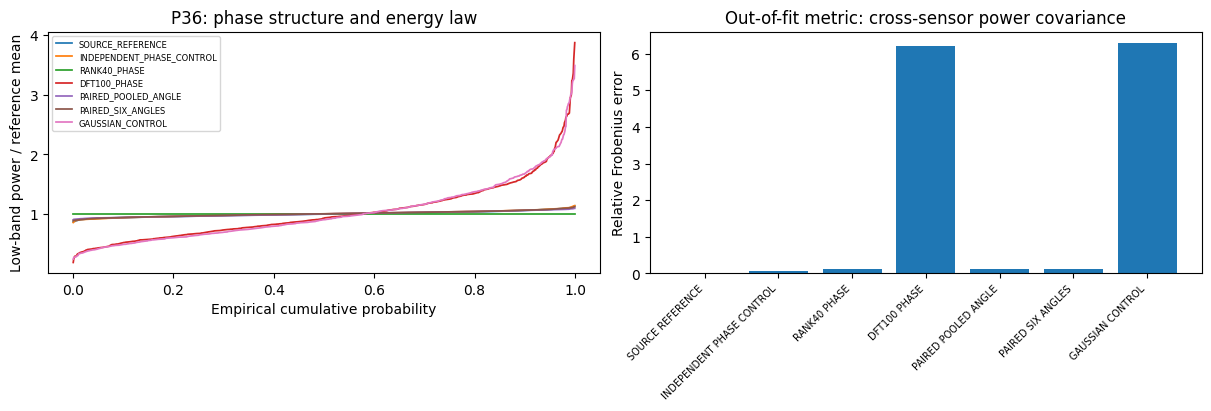


P36 — COVARIANCE-PRESERVING PAIRED-PHASE BASELINES
Training per-bin CVs: [0.069922, 0.094541, 0.122063, 0.127786, 0.160856, 0.169656]
Fitted angles (degrees): [3.1374, 4.5086, 6.149, 6.8119, 9.1029, 10.0589] pooled: 3.4338
Fitted covariance relative error vs source: 0.0364953
SOURCE_REFERENCE            CV=0.046411 theory=0.046504 W1=0.00000 powerCovErr=0.00000 kurtRMSE=0.00000 popCSDerr=0.00000
INDEPENDENT_PHASE_CONTROL   CV=0.048043 theory=0.046504 W1=0.00366 powerCovErr=0.06724 kurtRMSE=0.01741 popCSDerr=0.00000
RANK40_PHASE                CV=0.000000 theory=0.000000 W1=0.03749 powerCovErr=0.11513 kurtRMSE=0.03558 popCSDerr=0.03650
DFT100_PHASE                CV=0.494030 theory=0.498968 W1=0.33081 powerCovErr=6.21603 kurtRMSE=0.67656 popCSDerr=0.03650
PAIRED_POOLED_ANGLE         CV=0.043107 theory=0.042459 W1=0.00511 powerCovErr=0.11770 kurtRMSE=0.03442 popCSDerr=0.03650
PAIRED_SIX_ANGLES           CV=0.045519 theory=0.045298 W1=0.00409 powerCovErr=0.12143 kurtRMSE=0.04335 popCSDer

In [23]:

# CELL P36 — TRAINING-ONLY MOMENT CALIBRATION, UNSEEN SAME-SIMULATOR DIAGNOSTICS
# Insert directly BELOW completed P35 in the CLEAN continuation notebook.
# Run THIS CELL ONLY. Does NOT rerun older experiments or read test seed 1.
# Fits only a 6-angle covariance-preserving phase baseline from the 256
# recorded P25 training fields. This is NOT a new full-field generator.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, subprocess, uuid
import numpy as np
import h5py
import matplotlib.pyplot as plt

R36 = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
REPO36 = Path('/content/nasa_clfm_reference')
TRAIN36 = Path('/content/clfm_snapshot/data/wind/wind_train_data.hdf5')
PIN36 = '921e666c8d6060ae13bfd901dcc7f74f819d0eea'
TRAIN_SHA36 = '676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'
report_paths36 = {
 'P25':R36/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149/result.json',
 'P32':R36/'fidelity_diagnostics/p32_source_phase_audit_20261102T162342Z_ac5eae/result.json',
 'P33':R36/'fidelity_diagnostics/p33_seed_replay_csd_forensics_20261102T163710Z_22fbc5/result.json',
 'P34C-R':R36/'fidelity_diagnostics/p34c_standalone_replay_baselines_20261102T183830Z_02e2e8/result.json',
 'P35':R36/'fidelity_diagnostics/p35_source_blind_factor_identifiability_20261102T185615Z_bec6c9/result.json',
}

def sha36(path):
 h=hashlib.sha256()
 with Path(path).open('rb') as f:
  for b in iter(lambda:f.read(8*1024*1024),b''): h.update(b)
 return h.hexdigest()

assert R36.is_dir() and TRAIN36.is_file() and (REPO36/'.git').is_dir(), 'Restore existing pinned inputs with clean notebook cell 5b, not old training.'
assert all(p.is_file() for p in report_paths36.values())
input_sha36={key:sha36(p) for key,p in report_paths36.items()}
assert sha36(TRAIN36)==TRAIN_SHA36, 'Training SHA mismatch; stop.'
assert subprocess.check_output(['git','-C',str(REPO36),'rev-parse','HEAD'],text=True).strip()==PIN36
reps36={k:json.loads(v.read_text()) for k,v in report_paths36.items()}
assert all(reps36[k]['status']=='completed' for k in ('P25','P32','P33','P34C-R','P35'))
assert reps36['P35']['evaluated_rfft_bins']==[1,2,3,4,5,6]
assert reps36['P33']['decision']=='DOCUMENTED_SEED0_PHASE_REPLAY_MATCHES_SIX_COMPLEX_BINS'
assert reps36['P34C-R']['source_replay']['signed_replay_ac_error']<1e-8
for rel, expected in reps36['P32']['pinned_source_sha256'].items():
 assert sha36(REPO36/rel)==expected, f'NASA source changed: {rel}'

# Historical P25 256-field training cohort; only 40 sparse sensors.
ids36=np.asarray(reps36['P25']['training_indices'],dtype=int)
sel36=np.concatenate([np.arange(i,i+10) for i in (0,30,60,90)])
assert ids36.shape==(256,) and len(np.unique(ids36))==256
assert ids36.min()>=0 and ids36.max()<5000
with h5py.File(TRAIN36,'r') as f:
 assert len(f['wind_samples'])==5000
 coords36=np.asarray(f['x_grid'],dtype=np.float64)
 freq36=np.asarray(f['input_parameters/freq_grid'],dtype=np.float64)
 shear36=float(np.asarray(f['input_parameters/shear_velocity']))
 train36=np.stack([np.asarray(f['wind_samples'][str(int(i))]['v1'],dtype=np.float64)[sel36]
                   for i in ids36])
assert coords36.shape==(100,3) and freq36.shape==(128,) and train36.shape==(256,40,256)
assert np.isfinite(train36).all() and np.allclose(freq36,np.linspace(3/128,3,128)) and np.isclose(shear36,1.9)
X36=np.fft.rfft(train36-train36.mean(axis=-1,keepdims=True),axis=-1)[:,:,1:7].transpose(0,2,1)/49.
C36=np.einsum('nki,nkj->kij',X36,X36.conj(),optimize=True)/len(X36)
C36=(C36+C36.conj().transpose(0,2,1))/2
L36=np.empty((6,40,40),dtype=np.complex128)
eig36=np.empty((6,40),dtype=np.float64)
for k in range(6):
 eig,V=np.linalg.eigh(C36[k]); eig=np.maximum(eig,0)
 eig36[k]=eig; L36[k]=V*np.sqrt(eig)[None,:]
assert np.allclose(L36@L36.conj().transpose(0,2,1),C36,rtol=1e-11,atol=1e-8)

def cv36(a):
 return float(np.std(a,ddof=1)/np.mean(a))

def energy36(X):
 return (np.abs(X)**2).mean(axis=2)  # fields x frequency

train_bin36=energy36(X36)
train_cv_bin36=np.array([cv36(train_bin36[:,k]) for k in range(6)])
train_cv_all36=cv36(train_bin36.mean(axis=1))
assert abs(train_cv_all36-reps36['P35']['train_energy_cv'])<1e-8

# Analytic paired-factor model: L[:,j] split into two columns,
# cos(theta)*L[:,j] and sin(theta)*L[:,j]. Its exact covariance is C.
# For each bin k, Var(sum_sensor |A_k z|^2) = 0.5*sin(2 theta_k)^2 sum_j lambda_kj^2.
# Learn ONLY angles from training energy CVs; never draw training energies.
gcv36=np.sqrt(np.sum(eig36**2,axis=1))/np.sum(eig36,axis=1)
rawratio36=np.sqrt(2)*train_cv_bin36/gcv36
assert np.all(np.isfinite(rawratio36)) and np.all(rawratio36>=0)
assert np.all(rawratio36<=1), ('Per-bin CV cannot be reproduced by simple pair splitting; stop without clipping.',rawratio36.tolist())
theta_bin36=0.5*np.arcsin(rawratio36)
gcv_total36=float(np.sqrt(np.sum(eig36**2))/np.sum(eig36))
global_ratio36=np.sqrt(2)*train_cv_all36/gcv_total36
assert 0<=global_ratio36<=1, 'Pooled energy CV infeasible for pair model.'
theta_pooled36=float(0.5*np.arcsin(global_ratio36))

def make_pair36(theta):
 angle=np.broadcast_to(np.asarray(theta,dtype=float),(6,))
 A=np.empty((6,40,80),dtype=np.complex128)
 A[:,:,:40]=L36*np.cos(angle)[:,None,None]
 A[:,:,40:]=L36*np.sin(angle)[:,None,None]
 assert np.allclose(A@A.conj().transpose(0,2,1),C36,atol=1e-8,rtol=1e-11)
 return A

A_bin36=make_pair36(theta_bin36)
A_pool36=make_pair36(theta_pooled36)
# P35 controls: rank-40 and predetermined 100-phase Fourier frame.
i36=np.arange(40)[:,None]
j36=np.arange(100)[None,:]
Q36=np.exp(-2j*np.pi*i36*j36/100)/np.sqrt(100)
assert np.max(np.abs(Q36@Q36.conj().T-np.eye(40)))<1e-12
A_dft36=np.einsum('kij,jm->kim',L36,Q36,optimize=True)

# Oracle source factors are ONLY a positive control for fresh reference draws;
# they are NOT used to calibrate theta or fit C36.
zheight36=coords36[:,2]
mean36=2.5*shear36*np.log(zheight36/0.015)
var36=(6.-1.1*np.arctan(np.log(0.015)+1.75))*shear36**2
length36=300*(zheight36/200)**(0.67+0.05*np.log(shear36))
dist36=np.linalg.norm((coords36[:,None,:]-coords36[None,:,:])*[3.,3.,0.5],axis=-1)
Bsource36=np.empty((6,40,100),dtype=np.float64)
for ki,k in enumerate(range(1,7)):
 f=freq36[k]
 auto=(var36*6.868*f*(length36/mean36))/(f*(1+1.5*f*6.868*length36/mean36)**5/3)
 coh=np.exp(-f*dist36/(mean36[:,None]+mean36[None,:]))
 S=np.sqrt(auto[:,None]*auto[None,:])*coh
 U,s,_=np.linalg.svd(S,full_matrices=False)
 Bsource36[ki]=(U*np.sqrt(s)[None,:])[sel36]
Bsource36*=128*np.sqrt(4*(freq36[1]-freq36[0]))/49.
Csource36=Bsource36@Bsource36.transpose(0,2,1)

# Check theoretical CV for independent fixed phases or complex Gaussians.
def theory_cv36(A,gaussian=False):
 H=np.einsum('ksi,ksj->kij',A.conj(),A,optimize=True)
 tr=np.trace(H,axis1=1,axis2=2).real.sum()
 var=np.sum(np.abs(H)**2).real
 if not gaussian:
  var-=np.sum(np.abs(np.diagonal(H,axis1=1,axis2=2))**2).real
 return float(np.sqrt(max(0.,var))/tr)
assert abs(theory_cv36(A_bin36)-np.sqrt(np.sum((train_cv_bin36*np.sum(eig36,axis=1))**2))/np.sum(eig36))<1e-9

# New independent SAME-SIMULATOR development draws; no seed-1 test access.
N36=1024
factors36={
 'SOURCE_REFERENCE':(Bsource36,360101,False),
 'INDEPENDENT_PHASE_CONTROL':(Bsource36,360102,False),
 'RANK40_PHASE':(L36,360201,False),
 'DFT100_PHASE':(A_dft36,360301,False),
 'PAIRED_POOLED_ANGLE':(A_pool36,360401,False),
 'PAIRED_SIX_ANGLES':(A_bin36,360501,False),
 'GAUSSIAN_CONTROL':(L36,360601,True),
}

cohorts36={}
for name,(A,seed,isgauss) in factors36.items():
 r=np.random.default_rng(seed)
 if isgauss:
  z=(r.standard_normal((N36,6,A.shape[-1]))+1j*r.standard_normal((N36,6,A.shape[-1])))/np.sqrt(2)
 else:
  z=np.exp(2j*np.pi*r.random((N36,6,A.shape[-1])))
 cohorts36[name]=np.einsum('ksj,nkj->nks',A,z,optimize=True)
 assert cohorts36[name].shape==(N36,6,40) and np.isfinite(cohorts36[name]).all()
 del z

# Metrics not used in fitting: between-sensor power covariance, pointwise
# fourth moments, and unseen same-simulator energy quantiles.
def power_cov36(X):
 P=np.abs(X)**2
 D=P-P.mean(axis=0,keepdims=True)
 return np.einsum('nki,nkj->kij',D,D,optimize=True)/(len(P)-1)

def kurt36(X):
 P=np.abs(X)**2
 return P.var(axis=0,ddof=0)/(P.mean(axis=0)**2)+1

def csd36(X):
 return np.einsum('nki,nkj->kij',X,X.conj(),optimize=True)/len(X)

def rel36(a,b):
 return float(np.linalg.norm(a-b)/max(np.linalg.norm(b),1e-300))

REF36=cohorts36['SOURCE_REFERENCE']
refE36=energy36(REF36).mean(axis=1)
refmean36=refE36.mean()
refbins36=energy36(REF36)
refK36=power_cov36(REF36)
refkurt36=kurt36(REF36)
rows36=[]
for name,X in cohorts36.items():
 A,_,isgauss=factors36[name]
 en=energy36(X); overall=en.mean(axis=1)
 population_C=A@A.conj().transpose(0,2,1)
 binsCV=[cv36(en[:,k]) for k in range(6)]
 rows36.append({
  'name':name,
  'global_CV':cv36(overall),
  'theoretical_global_CV':theory_cv36(A,gaussian=isgauss),
  'perbin_CV':binsCV,
  'perbin_CV_RMSE_vs_source':float(np.sqrt(np.mean((np.array(binsCV)-np.array([cv36(refbins36[:,k]) for k in range(6)]))**2))),
  'global_energy_W1_over_ref_mean':float(np.mean(np.abs(np.sort(overall)-np.sort(refE36)))/refmean36),
  'power_covariance_relative_error':rel36(power_cov36(X),refK36),
  'sensor_power_kurtosis_RMSE':float(np.sqrt(np.mean((kurt36(X)-refkurt36)**2))),
  'sample_complex_CSD_relative_error':rel36(csd36(X),Csource36),
  'population_complex_CSD_relative_error':rel36(population_C,Csource36),
  'energy_quantiles_05_50_95_normalized_to_ref_mean':(np.quantile(overall,[.05,.5,.95])/refmean36).tolist()
 })

# Finite-cohort uncertainty for CV differences, not model-selection uncertainty.
boot36=np.random.default_rng(360901)
ci36={}
for name,X in cohorts36.items():
 if name=='SOURCE_REFERENCE':continue
 e=energy36(X).mean(axis=1)
 diffs=[]
 for _ in range(400):
  aa=e[boot36.integers(N36,size=N36)]
  bb=refE36[boot36.integers(N36,size=N36)]
  diffs.append(cv36(aa)-cv36(bb))
 ci36[name]=[float(x) for x in np.quantile(diffs,[.025,.975])]

# Commit nothing to old research folders; verify all inputs before new write.
assert sha36(TRAIN36)==TRAIN_SHA36
assert all(sha36(report_paths36[k])==v for k,v in input_sha36.items())
RUN36=R36/'fidelity_diagnostics'/('p36_pair_phase_moment_diagnostic_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
assert RUN36.parent.resolve()==(R36/'fidelity_diagnostics').resolve()
RUN36.mkdir(parents=True,exist_ok=False)
report36=RUN36/'result.json'
figure36=RUN36/'p36_phase_factor_energy_and_power_covariance.png'
ledger36=RUN36/'P36_RESEARCH_LEDGER_ADDENDUM.md'
provenance36=RUN36/'P36_PROVENANCE_NOTE.json'
result36={
 'experiment':'P36_covariance_preserving_paired_phase_moment_baselines',
 'status':'completed', 'created_utc':datetime.now(timezone.utc).isoformat(),
 'training_indices_count':256,'sensors':40,'frequencies':[1,2,3,4,5,6],
 'new_development_draws_per_cohort':N36,
 'training_CV_all':train_cv_all36,'training_CV_by_bin':train_cv_bin36.tolist(),
 'gaussian_theory_CV_by_bin':gcv36.tolist(),
 'calibration_ratio_by_bin':rawratio36.tolist(),
 'trained_six_angles_radians':theta_bin36.tolist(),
 'trained_pooled_angle_radians':theta_pooled36,
 'candidate_covariance_exactly_preserved':True,
 'training_fit_uses_only_P25_256_fields':True,
 'oracle_source_used_only_for_reference_not_fit':True,
 'input_report_hashes':input_sha36,'trusted_train_sha256':TRAIN_SHA36,'pinned_source_commit':PIN36,
 'development_seeds':{name:seed for name,(_,seed,_) in factors36.items()},
 'bootstrap_seed':360901,'cohort_metrics':rows36,'cv_difference_bootstrap_CI95':ci36,
 'limitations':[
  'Angles fitted to six training per-frequency power CVs; matching those margins is BY CONSTRUCTION, not independent proof of learned physics.',
  'All evaluation draws from the same known simulator; not seed-1 or unseen regimes.',
  'All diagnostics concern 40-sensor Fourier bins 1-6, not full wind trajectories.',
  'Source-phase oracle is a positive control using known NASA factors, not a learned model.',
  'The 256 P25 fields were already examined in prior P25-P35 development; this is not preregistered holdout validation.',
  'No empirical per-field energies are injected into generated coefficients; only six aggregate training CVs are used.',
  'Source and learned models have different factors, and learned covariance has finite-sample estimation error.',
  'CV bootstrap intervals condition on fixed candidate fits and do not include training or model-selection uncertainty.',
  'P1-P35 and the November 3 presentation remain unchanged.'
 ]
}
report36.write_text(json.dumps(result36,indent=2,allow_nan=False),encoding='utf-8')
fig,ax=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
for row in rows36:
 name=row['name']; vals=energy36(cohorts36[name]).mean(axis=1)/refmean36
 ax[0].plot((np.arange(N36)+0.5)/N36,np.sort(vals),label=name,lw=1.25)
ax[0].set(xlabel='Empirical cumulative probability',ylabel='Low-band power / reference mean',title='P36: phase structure and energy law')
ax[0].legend(fontsize=6)
ax[1].bar(np.arange(len(rows36)),[row['power_covariance_relative_error'] for row in rows36])
ax[1].set_xticks(np.arange(len(rows36)),[r['name'].replace('_',' ') for r in rows36],rotation=45,ha='right',fontsize=7)
ax[1].set(ylabel='Relative Frobenius error',title='Out-of-fit metric: cross-sensor power covariance')
fig.savefig(figure36,dpi=150)
plt.show();plt.close(fig)
ledger36.write_text('# P36 — Paired-phase covariance-preserving moment baseline\n\n'
 '- Fits six angles from P25 training per-bin fieldwise energy CVs, plus pooled-angle ablation.\n'
 '- Candidate factors preserve the SAME fitted complex CSD by construction.\n'
 '- Evaluates fresh same-simulator phase draws against source and baselines.\n'
 '- Held-out metrics are sensor-power covariance, pointwise fourth moments, energy tails and quantiles.\n'
 '- Energy-CV matching alone is NOT evidence of generalization or a learned complete wind generator.\n'
 '- No prospective seed-1 dataset accessed; November 3 presentation frozen.\n'
 '- See result.json for numerical results and explicit limitations.\n',encoding='utf-8')
artifact_sha36={p.name:sha36(p) for p in (report36,figure36,ledger36)}
with provenance36.open('x',encoding='utf-8') as f:
 json.dump({'scope':'NEW_P36_FOLDER_ONLY','artifact_sha256':artifact_sha36,'input_report_sha256':input_sha36,'historical_vault_not_scanned':True},f,indent=2)
assert all(sha36(RUN36/name)==digest for name,digest in artifact_sha36.items())
assert all(sha36(report_paths36[k])==v for k,v in input_sha36.items())

print('\n'+'='*95+'\nP36 — COVARIANCE-PRESERVING PAIRED-PHASE BASELINES\n'+'='*95)
print('Training per-bin CVs:',np.round(train_cv_bin36,6).tolist())
print('Fitted angles (degrees):',np.round(np.degrees(theta_bin36),4).tolist(),'pooled:',round(np.degrees(theta_pooled36),4))
print('Fitted covariance relative error vs source:',round(rel36(C36,Csource36),7))
for row in rows36:
 print(f"{row['name']:27s} CV={row['global_CV']:.6f} theory={row['theoretical_global_CV']:.6f} W1={row['global_energy_W1_over_ref_mean']:.5f} powerCovErr={row['power_covariance_relative_error']:.5f} kurtRMSE={row['sensor_power_kurtosis_RMSE']:.5f} popCSDerr={row['population_complex_CSD_relative_error']:.5f}")
for name,interval in ci36.items():
 print('CV difference bootstrap95 vs reference:',name,[round(v,6) for v in interval])
print('Report:',report36,'\nFigure:',figure36,'\nLedger:',ledger36,'\nProvenance:',provenance36)
print('P36 COMPLETE — TRAINING-ONLY MOMENT FIT; NEW SAME-SIMULATOR DEVELOPMENT; NO SEED-1 OR HISTORICAL WRITES')


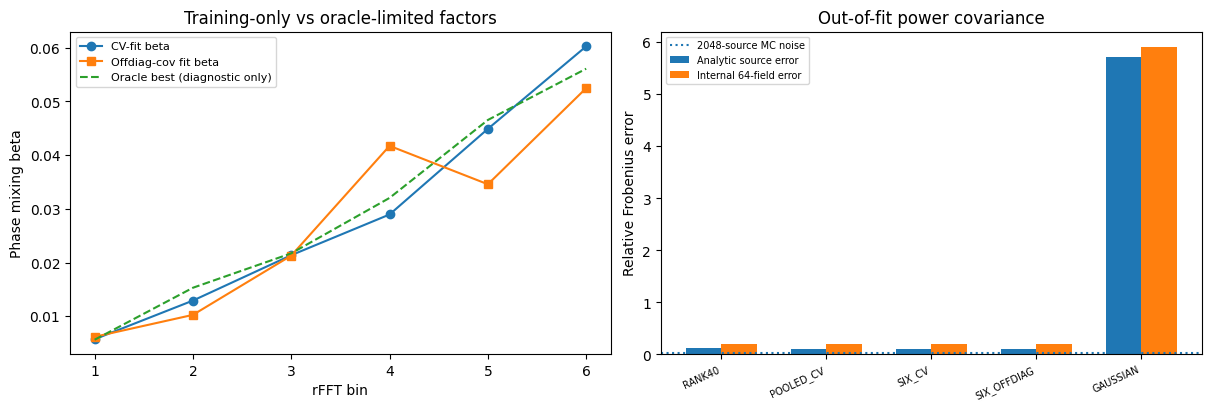


P37 — FOURTH-ORDER ANALYTIC STRUCTURE AUDIT
Fit CSD vs known source: 0.038130514363441864
192-field CV by bin: [0.068426, 0.096847, 0.118472, 0.130498, 0.154123, 0.171749]
CV-fit beta: [0.00572, 0.012922, 0.021374, 0.028957, 0.044901, 0.060272]
Offdiag-fit beta raw: [0.006177, 0.010261, 0.021295, 0.041737, 0.034584, 0.05249]
Offdiag-fit beta bounded: [0.006177, 0.010261, 0.021295, 0.041737, 0.034584, 0.05249]
Oracle-best family residual (diagnostic only): 0.10531175376160944
Source analytic CV: 0.04650441658135235 2048-source simulated CV: 0.04644925433742718
Source Monte Carlo K relative error: 0.03095010958615139
RANK40            CV=0.000000 Ksrc=0.11351 Kval64=0.20142 offSrc=0.12963 diagSrc=0.08172
POOLED_CV         CV=0.042407 Ksrc=0.10711 Kval64=0.19798 offSrc=0.12115 diagSrc=0.07998
SIX_CV            CV=0.044835 Ksrc=0.10538 Kval64=0.19681 offSrc=0.11963 diagSrc=0.07765
SIX_OFFDIAG       CV=0.045103 Ksrc=0.10567 Kval64=0.19707 offSrc=0.12009 diagSrc=0.07756
GAUSSIAN          CV

In [24]:

# P37 — Four-th-order power-covariance audit, source-blind fits.
# New single Colab cell BELOW completed P36. Run ONLY this cell.
# No old runtime variables. Never rerun prior experiments or use test seed 1.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, subprocess, uuid
import numpy as np
import h5py
import matplotlib.pyplot as plt

ROOT=Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
REPO=Path('/content/nasa_clfm_reference')
HDF=Path('/content/clfm_snapshot/data/wind/wind_train_data.hdf5')
PIN='921e666c8d6060ae13bfd901dcc7f74f819d0eea'
DATA_SHA='676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'
reports={
 'P25':ROOT/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149/result.json',
 'P32':ROOT/'fidelity_diagnostics/p32_source_phase_audit_20261102T162342Z_ac5eae/result.json',
 'P34':ROOT/'fidelity_diagnostics/p34c_standalone_replay_baselines_20261102T183830Z_02e2e8/result.json',
 'P35':ROOT/'fidelity_diagnostics/p35_source_blind_factor_identifiability_20261102T185615Z_bec6c9/result.json',
 'P36':ROOT/'fidelity_diagnostics/p36_pair_phase_moment_diagnostic_20261102T190156Z_3d3deb/result.json',
}
def sha(p):
 h=hashlib.sha256()
 with Path(p).open('rb') as f:
  for chunk in iter(lambda:f.read(8*1024*1024),b''):h.update(chunk)
 return h.hexdigest()
assert ROOT.is_dir() and (REPO/'.git').is_dir() and HDF.is_file(), 'Use clean notebook Cell 5b to restore only pinned inputs.'
assert all(p.is_file() for p in reports.values()), 'Saved research report missing; do not rerun experiments.'
assert sha(HDF)==DATA_SHA
assert subprocess.check_output(['git','-C',str(REPO),'rev-parse','HEAD'],text=True).strip()==PIN
old_sha={k:sha(p) for k,p in reports.items()}
old={k:json.loads(p.read_text()) for k,p in reports.items()}
assert all(v['status']=='completed' for v in old.values())
assert old['P35']['evaluated_rfft_bins']==[1,2,3,4,5,6]
assert old['P34']['source_replay']['signed_replay_ac_error']<1e-8
for rel,digest in old['P32']['pinned_source_sha256'].items():assert sha(REPO/rel)==digest

ids=np.asarray(old['P25']['training_indices'],dtype=int)
sel=np.r_[0:10,30:40,60:70,90:100]
assert ids.shape==(256,) and np.unique(ids).size==256 and ids.min()>=0 and ids.max()<5000
with h5py.File(HDF,'r') as f:
 assert len(f['wind_samples'])==5000
 xyz=np.asarray(f['x_grid'],dtype=float)
 freq=np.asarray(f['input_parameters/freq_grid'],dtype=float)
 shear=float(np.asarray(f['input_parameters/shear_velocity']))
 raw=np.stack([np.asarray(f['wind_samples'][str(int(i))]['v1'],dtype=float)[sel] for i in ids])
assert xyz.shape==(100,3) and freq.shape==(128,) and raw.shape==(256,40,256)
assert np.isfinite(raw).all() and np.isclose(shear,1.9)
F=np.fft.rfft(raw-raw.mean(axis=-1,keepdims=True),axis=-1)[:,:,1:7].transpose(0,2,1)/49
split=np.random.default_rng(370000).permutation(256)
X=F[split[:192]]; V=F[split[192:]]

def csd(x):return np.einsum('nki,nkj->kij',x,x.conj(),optimize=True)/len(x)
def pcov(x):
 p=np.abs(x)**2
 d=p-p.mean(axis=0,keepdims=True)
 return np.einsum('nki,nkj->kij',d,d,optimize=True)/(len(x)-1)
def cv(x):return float(np.std(x,ddof=1)/np.mean(x))
def rel(x,y):return float(np.linalg.norm(x-y)/max(np.linalg.norm(y),1e-300))
def analytic_cv(K,C):
 return float(np.sqrt(max(0.,float(K.sum().real)))/np.trace(C,axis1=1,axis2=2).real.sum())

C=csd(X);C=(C+C.conj().transpose(0,2,1))/2
L=np.empty((6,40,40),dtype=complex)
for k in range(6):
 eig,U=np.linalg.eigh(C[k]);L[k]=U*np.sqrt(np.maximum(eig,0))[None,:]
assert np.allclose(L@L.conj().transpose(0,2,1),C,rtol=1e-10,atol=1e-8)
Ktrain=pcov(X);Kval=pcov(V)
T=np.einsum('kia,kja->kij',abs(L)**2,abs(L)**2,optimize=True).real
K0=(abs(C)**2-T).real

def fit_beta(target,offdiag=False):
 out=[]
 for k in range(6):
  mask=(~np.eye(40,dtype=bool)) if offdiag else np.ones((40,40),dtype=bool)
  t=T[k][mask]; d=(target[k]-K0[k])[mask]
  out.append(float(np.dot(t,d)/np.dot(t,t)))
 rawbeta=np.asarray(out)
 return rawbeta,np.clip(rawbeta,0,.5)

beta_off_raw,beta_off=fit_beta(Ktrain,True)
tr=np.trace(C,axis1=1,axis2=2).real
bin_cvs=np.array([cv((abs(X[:,k,:])**2).mean(axis=1)) for k in range(6)])
beta_cv=(bin_cvs*tr)**2/T.sum(axis=(1,2))
beta_pool=float((cv((abs(X)**2).mean(axis=(1,2)))*tr.sum())**2/T.sum())
assert np.all((beta_cv>=0)&(beta_cv<=.5)) and 0<=beta_pool<=.5, 'Paired family cannot attain training CV; stop.'
models={
 'RANK40':np.zeros(6),
 'POOLED_CV':np.full(6,beta_pool),
 'SIX_CV':beta_cv,
 'SIX_OFFDIAG':beta_off,
 'GAUSSIAN':None,
}
Kmodels={k:(abs(C)**2 if b is None else K0+b[:,None,None]*T) for k,b in models.items()}

# Oracle for EVALUATION ONLY; fit above is already frozen.
z=xyz[:,2]
mu=2.5*shear*np.log(z/0.015)
variance=(6-1.1*np.arctan(np.log(.015)+1.75))*shear**2
length=300*(z/200)**(.67+.05*np.log(shear))
dist=np.linalg.norm((xyz[:,None,:]-xyz[None,:,:])*[3.,3.,.5],axis=-1)
B=np.empty((6,40,100),dtype=float)
for ik,k in enumerate(range(1,7)):
 f=freq[k]
 auto=(variance*6.868*f*(length/mu))/(f*(1+1.5*f*6.868*length/mu)**5/3)
 coh=np.exp(-f*dist/(mu[:,None]+mu[None,:]))
 S=np.sqrt(auto[:,None]*auto[None,:])*coh
 u,s,_=np.linalg.svd(S,full_matrices=False)
 B[ik]=(u*np.sqrt(s)[None,:])[sel]
B*=128*np.sqrt(4*(freq[1]-freq[0]))/49
Csrc=B@B.transpose(0,2,1)
Ksrc=(abs(Csrc)**2-np.einsum('kia,kja->kij',B**2,B**2,optimize=True)).real

# Monte Carlo estimate of unavoidable source-cohort sampling variation.
rng=np.random.default_rng(370101)
Z=np.exp(2j*np.pi*rng.random((2048,6,100)))
Y=np.einsum('kij,nkj->nki',B,Z,optimize=True)
del Z
Kmc=pcov(Y)
source_mc_error=rel(Kmc,Ksrc)
source_mc_cv=cv((abs(Y)**2).mean(axis=(1,2)))
del Y

# Post-hoc oracle fit is a LIMITATION DIAGNOSTIC ONLY: not a candidate.
best_oracle_raw,best_oracle_beta=fit_beta(Ksrc,False)
best_oracle_K=K0+best_oracle_beta[:,None,None]*T
best_oracle_error=rel(best_oracle_K,Ksrc)

mask=~np.eye(40,dtype=bool)
def off_err(a,b):return rel(a[:,mask],b[:,mask])
def diag_err(a,b):
 return rel(np.diagonal(a,axis1=1,axis2=2),np.diagonal(b,axis1=1,axis2=2))
rows=[]
for name,K in Kmodels.items():
 beta=models[name]
 rows.append({
  'name':name,
  'beta_by_bin':None if beta is None else beta.tolist(),
  'theoretical_CV':analytic_cv(K,C),
  'K_error_vs_oracle_population':rel(K,Ksrc),
  'offdiag_error_vs_oracle_population':off_err(K,Ksrc),
  'diagonal_error_vs_oracle_population':diag_err(K,Ksrc),
  'K_error_vs_internal_64':rel(K,Kval),
  'K_error_vs_fit_192':rel(K,Ktrain)
 })

# Append-only new P37 evidence; check that originals are unchanged first.
assert sha(HDF)==DATA_SHA
assert all(sha(reports[k])==d for k,d in old_sha.items())
run=ROOT/'fidelity_diagnostics'/('p37_analytic_fourth_order_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
assert run.parent.resolve()==(ROOT/'fidelity_diagnostics').resolve()
run.mkdir(parents=True,exist_ok=False)
result_path=run/'result.json'
figure_path=run/'fourth_order_power_covariance.png'
ledger_path=run/'P37_LEDGER_ADDENDUM.md'
provenance_path=run/'P37_PROVENANCE_NOTE.json'
result={
 'experiment':'P37_source_blind_fourth_order_analytic_identifiability',
 'status':'completed','created_utc':datetime.now(timezone.utc).isoformat(),
 'pinned_commit':PIN,'trusted_training_sha256':DATA_SHA,
 'prior_report_hashes':old_sha,'split_seed':370000,
 'fit_indices':ids[split[:192]].tolist(),'internal_validation_indices':ids[split[192:]].tolist(),
 'fit_n':192,'internal_validation_n':64,'frequency_bins':[1,2,3,4,5,6],
 'fitted_CSD_relative_error_vs_source':rel(C,Csrc),
 'fit_CV_per_bin':bin_cvs.tolist(),
 'fit_CV_total':cv((abs(X)**2).mean(axis=(1,2))),
 'internal_validation_CV_total':cv((abs(V)**2).mean(axis=(1,2))),
 'offdiag_beta_unconstrained':beta_off_raw.tolist(),
 'offdiag_beta_bounded':beta_off.tolist(),
 'CV_fitted_beta':beta_cv.tolist(),'CV_pooled_beta':beta_pool,
 'source_analytic_CV':analytic_cv(Ksrc,Csrc),
 'source_2048_sample_CV':source_mc_cv,
 'source_MC_K_relative_error_vs_analytic':source_mc_error,
 'posthoc_best_oracle_beta_NOT_FITTED_CANDIDATE':best_oracle_beta.tolist(),
 'posthoc_best_family_K_relative_error':best_oracle_error,
 'comparison_rows':rows,
 'limitations':[
  'The 256 P25 training fields have already been examined in earlier experiments; internal 64 is NOT untouched holdout.',
  'CV and offdiagonal-power-covariance candidates use only the 192 fit fields.',
  'The source CSD and source analytical fourth-order tensor were used ONLY for evaluation after model fits.',
  'Post-hoc oracle best beta is an unattainable-information family limit, NOT a model to select.',
  'Source MC samples are same fixed simulator, NOT unseen physical regimes or seed-1 test data.',
  'Candidate covariance C is estimated from 192 fields; oracle has a different known covariance.',
  'Family assumes independent fixed-modulus complex phases and scalar beta per frequency.',
  'One 64-field internal split is noisy; prior model selection means no confirmatory p-values.',
  'No previous research evidence, models, vault, or November 3 presentation modified.'
 ]
}
result_path.write_text(json.dumps(result,indent=2,allow_nan=False),encoding='utf-8')
fig,ax=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
ax[0].plot(range(1,7),beta_cv,'o-',label='CV-fit beta')
ax[0].plot(range(1,7),beta_off,'s-',label='Offdiag-cov fit beta')
ax[0].plot(range(1,7),best_oracle_beta,'--',label='Oracle best (diagnostic only)')
ax[0].set(xlabel='rFFT bin',ylabel='Phase mixing beta',title='Training-only vs oracle-limited factors')
ax[0].legend(fontsize=8)
pos=np.arange(len(rows))
ax[1].bar(pos-.17,[r['K_error_vs_oracle_population'] for r in rows],.34,label='Analytic source error')
ax[1].bar(pos+.17,[r['K_error_vs_internal_64'] for r in rows],.34,label='Internal 64-field error')
ax[1].axhline(source_mc_error,linestyle=':',label='2048-source MC noise')
ax[1].set_xticks(pos,[r['name'] for r in rows],rotation=25,ha='right',fontsize=7)
ax[1].set(ylabel='Relative Frobenius error',title='Out-of-fit power covariance')
ax[1].legend(fontsize=7)
fig.savefig(figure_path,dpi=150)
plt.show();plt.close(fig)
ledger_path.write_text(
 '# P37 — Fourth-order source-blind moment analysis\n\n'
 '- Fit covariance and phase-mixing betas using 192 reused P25 training fields.\n'
 '- Internal validation: 64 other already-studied P25 fields (not pristine).\n'
 '- Source analytical power covariance and new source phases are evaluation only.\n'
 '- Oracle-best family beta is a post-hoc structural diagnostic, never used for fitting.\n'
 '- No new full-field learned generator or seed-1 test evaluation.\n'
 '- The November 3 presentation and P1–P36 evidence remain unchanged.\n',encoding='utf-8'
)
artifact_sha={p.name:sha(p) for p in (result_path,figure_path,ledger_path)}
provenance_path.write_text(json.dumps({'scope':'NEW_P37_FOLDER_ONLY','artifact_sha256':artifact_sha,'prior_report_sha256':old_sha,'historical_vault_not_scanned':True},indent=2),encoding='utf-8')
assert all(sha(run/name)==digest for name,digest in artifact_sha.items())
assert all(sha(reports[k])==d for k,d in old_sha.items())
print('\n'+'='*84+'\nP37 — FOURTH-ORDER ANALYTIC STRUCTURE AUDIT\n'+'='*84)
print('Fit CSD vs known source:',rel(C,Csrc))
print('192-field CV by bin:',np.round(bin_cvs,6).tolist())
print('CV-fit beta:',np.round(beta_cv,6).tolist())
print('Offdiag-fit beta raw:',np.round(beta_off_raw,6).tolist())
print('Offdiag-fit beta bounded:',np.round(beta_off,6).tolist())
print('Oracle-best family residual (diagnostic only):',best_oracle_error)
print('Source analytic CV:',analytic_cv(Ksrc,Csrc),'2048-source simulated CV:',source_mc_cv)
print('Source Monte Carlo K relative error:',source_mc_error)
for r in rows:
 print(f"{r['name']:17s} CV={r['theoretical_CV']:.6f} Ksrc={r['K_error_vs_oracle_population']:.5f} Kval64={r['K_error_vs_internal_64']:.5f} offSrc={r['offdiag_error_vs_oracle_population']:.5f} diagSrc={r['diagonal_error_vs_oracle_population']:.5f}")
print('Report:',result_path,'\nFigure:',figure_path,'\nLedger:',ledger_path,'\nProvenance:',provenance_path)
print('P37 COMPLETE — P1–P36 untouched, no prospective test or model training.')


P38 — ORACLE COVARIANCE / PAIRED-PHASE STRUCTURAL LIMIT
P37 covariance-fit vs source relative error: 0.038130514363441864
Best paired-family K error WITH fitted C (post-hoc): 0.10531175376160944
Best paired-family K error WITH exact source C (post-hoc): 0.08339585501263302
64-field internal training-validation K error vs source: 0.16460799447037416
Independent source sampling-noise calibration:
  n= 64 median= 0.18774 5th–95th= [0.14218, 0.26756]
  n= 192 median= 0.11486 5th–95th= [0.08462, 0.14239]
  n= 512 median= 0.0706 5th–95th= [0.05407, 0.10208]
Per-frequency oracle floors:
  bin=1 fittedCerr=0.10551 exactCerr=0.08206 beta_exact=0.00654
  bin=2 fittedCerr=0.09563 exactCerr=0.08537 beta_exact=0.01405
  bin=3 fittedCerr=0.12051 exactCerr=0.08990 beta_exact=0.02333
  bin=4 fittedCerr=0.12277 exactCerr=0.09387 beta_exact=0.03369
  bin=5 fittedCerr=0.14284 exactCerr=0.09686 beta_exact=0.04507
  bin=6 fittedCerr=0.10835 exactCerr=0.09882 beta_exact=0.05745


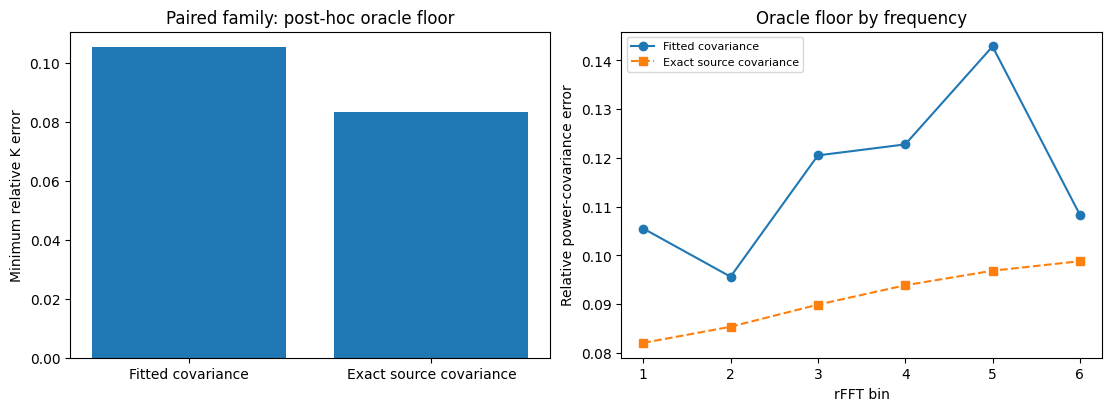

P38 report: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p38_oracle_covariance_family_limit_20261103T001833Z_3b4afb/result.json
P38 figure: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p38_oracle_covariance_family_limit_20261103T001833Z_3b4afb/structural_limit_and_noise.png
P38 ledger: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p38_oracle_covariance_family_limit_20261103T001833Z_3b4afb/P38_LEDGER_ADDENDUM.md
P38 provenance: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p38_oracle_covariance_family_limit_20261103T001833Z_3b4afb/P38_PROVENANCE_NOTE.json
P38 COMPLETE — no retraining, seed-1 test use, or historical artifact overwrite.


In [25]:

# CELL P38 — ORACLE-COVARIANCE PAIR-FAMILY LIMIT + VALIDATION NOISE
# Paste ONE cell immediately BELOW completed P37 in CLEAN continuation notebook.
# Run this cell ONLY; no historical training cells, no seed-1 test data.
# Source oracle is for LIMIT/DIAGNOSTICS, NEVER for fitting a released model.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, subprocess, uuid
import numpy as np
import h5py
import matplotlib.pyplot as plt

ROOT38 = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
REPO38 = Path('/content/nasa_clfm_reference')
TRAIN38 = Path('/content/clfm_snapshot/data/wind/wind_train_data.hdf5')
PIN38 = '921e666c8d6060ae13bfd901dcc7f74f819d0eea'
TRAIN_SHA38 = '676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'

PRIOR38 = {
    'P25': ROOT38/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149/result.json',
    'P32': ROOT38/'fidelity_diagnostics/p32_source_phase_audit_20261102T162342Z_ac5eae/result.json',
    'P35': ROOT38/'fidelity_diagnostics/p35_source_blind_factor_identifiability_20261102T185615Z_bec6c9/result.json',
    'P36': ROOT38/'fidelity_diagnostics/p36_pair_phase_moment_diagnostic_20261102T190156Z_3d3deb/result.json',
    'P37': ROOT38/'fidelity_diagnostics/p37_analytic_fourth_order_20261102T191024Z_928bf7/result.json'
}

def sha38(p):
    h = hashlib.sha256()
    with Path(p).open('rb') as f:
        for b in iter(lambda: f.read(8*1024*1024), b''):
            h.update(b)
    return h.hexdigest()

def rel38(a, b):
    return float(
        np.linalg.norm(a-b) /
        max(np.linalg.norm(b), 1e-300)
    )

def cv38(x):
    return float(np.std(x, ddof=1)/np.mean(x))

def csd38(x):
    return np.einsum(
        'nki,nkj->kij',
        x, x.conj(),
        optimize=True
    ) / len(x)

def pcov38(x):
    p = np.abs(x)**2
    d = p-p.mean(axis=0, keepdims=True)
    return np.einsum(
        'nki,nkj->kij',
        d, d,
        optimize=True
    ) / (len(x)-1)

def paired38(C):
    C = (C+C.conj().transpose(0,2,1))/2
    L = []

    for ck in C:
        e, U = np.linalg.eigh(ck)

        assert e.min() > -1e-6, (
            'Unexpectedly indefinite empirical covariance'
        )

        L.append(
            U*np.sqrt(np.maximum(e,0))[None,:]
        )

    L = np.asarray(L)

    assert np.allclose(
        L@L.conj().transpose(0,2,1),
        C,
        rtol=1e-10,
        atol=1e-7
    )

    T = np.einsum(
        'kia,kja->kij',
        np.abs(L)**2,
        np.abs(L)**2,
        optimize=True
    ).real

    K0 = (np.abs(C)**2-T).real

    return K0, T

def optimal38(K0, T, target):
    raw = np.sum(
        T*(target-K0),
        axis=(1,2)
    ) / np.sum(T*T, axis=(1,2))

    beta = np.clip(raw, 0, 0.5)

    return raw, beta, K0+beta[:,None,None]*T

# ---------------------------------------------------------
# 1. Verify original research evidence and pinned source.
# ---------------------------------------------------------

assert (
    ROOT38.is_dir()
    and TRAIN38.is_file()
    and (REPO38/'.git').is_dir()
), 'Restore only pinned inputs from clean notebook Cell 5b.'

assert all(
    p.is_file() for p in PRIOR38.values()
), 'Prior report missing; do not rerun earlier experiments.'

assert sha38(TRAIN38) == TRAIN_SHA38, (
    'Trusted HDF5 changed.'
)

assert subprocess.check_output(
    ['git','-C',str(REPO38),'rev-parse','HEAD'],
    text=True
).strip() == PIN38

SHA38 = {
    key: sha38(path)
    for key, path in PRIOR38.items()
}

REP38 = {
    key: json.loads(path.read_text())
    for key, path in PRIOR38.items()
}

assert all(
    r['status']=='completed'
    for r in REP38.values()
)

assert (
    REP38['P37']['source_MC_K_relative_error_vs_analytic'] > 0
)

assert len(
    REP38['P37']['fit_indices']
) == 192

assert len(
    REP38['P37']['internal_validation_indices']
) == 64

for rel, expected in REP38['P32']['pinned_source_sha256'].items():
    assert sha38(REPO38/rel) == expected, (
        f'Pinned source differs: {rel}'
    )

# ---------------------------------------------------------
# 2. Recover P37's exact training-only partition.
# ---------------------------------------------------------

fitids38 = np.asarray(
    REP38['P37']['fit_indices'],
    dtype=int
)

valids38 = np.asarray(
    REP38['P37']['internal_validation_indices'],
    dtype=int
)

p25ids38 = np.asarray(
    REP38['P25']['training_indices'],
    dtype=int
)

assert np.unique(
    np.r_[fitids38,valids38]
).size == 256

assert np.array_equal(
    np.sort(np.r_[fitids38,valids38]),
    np.sort(p25ids38)
)

sel38 = np.r_[0:10,30:40,60:70,90:100]

with h5py.File(TRAIN38,'r') as f:

    assert len(f['wind_samples']) == 5000

    xyz38 = np.asarray(
        f['x_grid'], dtype=float
    )

    fr38 = np.asarray(
        f['input_parameters/freq_grid'],
        dtype=float
    )

    shear38 = float(np.asarray(
        f['input_parameters/shear_velocity']
    ))

    xraw38 = np.stack([
        np.asarray(
            f['wind_samples'][str(int(i))]['v1'],
            dtype=float
        )[sel38]
        for i in np.r_[fitids38,valids38]
    ])

assert xraw38.shape == (256,40,256)
assert xyz38.shape == (100,3)
assert fr38.shape == (128,)

assert np.allclose(
    fr38,np.linspace(3/128,3,128)
)

assert abs(shear38-1.9) < 1e-12

X38 = np.fft.rfft(
    xraw38-xraw38.mean(axis=-1,keepdims=True),
    axis=-1
)[:,:,1:7].transpose(0,2,1)/49.

FIT38 = X38[:192]
VAL38 = X38[192:]

Ctmp38 = csd38(FIT38)

Cfit38 = (
    Ctmp38+Ctmp38.conj().transpose(0,2,1)
)/2

Kfit38 = pcov38(FIT38)
Kval38 = pcov38(VAL38)

# ---------------------------------------------------------
# 3. Reconstruct exact source covariance and fourth moments.
# ---------------------------------------------------------

# Preserve the literal pinned-source mathematics:
# **5/3 means fifth power divided by three.
# The source passes shear_velocity into the length-scale
# argument named z_0.

z38 = xyz38[:,2]

mu38 = 2.5*shear38*np.log(z38/.015)

variance38 = (
    6.-1.1*np.arctan(np.log(.015)+1.75)
)*shear38**2

length38 = 300*(z38/200)**(
    .67+.05*np.log(shear38)
)

dist38 = np.linalg.norm(
    (xyz38[:,None,:]-xyz38[None,:,:])
    *[3.,3.,.5],
    axis=-1
)

B38 = []

for k in range(1,7):

    f = fr38[k]

    auto = (
        variance38*6.868*f*(length38/mu38)
    ) / (
        f*(1+1.5*f*6.868*length38/mu38)**5/3
    )

    coh = np.exp(
        -f*dist38/(mu38[:,None]+mu38[None,:])
    )

    S = np.sqrt(
        auto[:,None]*auto[None,:]
    )*coh

    U, s, _ = np.linalg.svd(
        S,full_matrices=False
    )

    B38.append(
        (U*np.sqrt(s)[None,:])[sel38]
    )

B38 = np.asarray(B38) * (
    128*np.sqrt(4*(fr38[1]-fr38[0]))/49.
)

Csrc38 = B38@B38.transpose(0,2,1)

Ksrc38 = (
    np.abs(Csrc38)**2
    -np.einsum(
        'kia,kja->kij',
        B38**2,B38**2,
        optimize=True
    )
).real

# Verify agreement with saved P37 numerical evidence.

assert abs(
    rel38(Cfit38,Csrc38)
    -REP38['P37']['fitted_CSD_relative_error_vs_source']
) < 1e-9

# ---------------------------------------------------------
# 4. Determine two post-hoc theoretical family floors.
# ---------------------------------------------------------

# Diagnostic 1: Best paired fit with P37's estimated covariance.
# Diagnostic 2: Best paired fit with the exact NASA source covariance.
#
# These use oracle knowledge and are NOT trained candidates.

K0_fit38, T_fit38 = paired38(Cfit38)
K0_exact38, T_exact38 = paired38(Csrc38)

raw_fit38, beta_fit38, Kbest_fit38 = optimal38(
    K0_fit38,T_fit38,Ksrc38
)

raw_exact38, beta_exact38, Kbest_exact38 = optimal38(
    K0_exact38,T_exact38,Ksrc38
)

fit_floor38 = rel38(
    Kbest_fit38,Ksrc38
)

exact_floor38 = rel38(
    Kbest_exact38,Ksrc38
)

assert abs(
    fit_floor38
    -REP38['P37']['posthoc_best_family_K_relative_error']
) < 1e-8

# Previously trained beta values, for reference only.

betas38 = {
    'RANK40':np.zeros(6),

    'POOLED_CV':np.full(
        6,float(REP38['P37']['CV_pooled_beta'])
    ),

    'SIX_CV':np.asarray(
        REP38['P37']['CV_fitted_beta'],
        dtype=float
    ),

    'SIX_OFFDIAG':np.asarray(
        REP38['P37']['offdiag_beta_bounded'],
        dtype=float
    )
}

metrics38 = {}

for key,beta in betas38.items():

    K = K0_fit38+beta[:,None,None]*T_fit38

    metrics38[key] = {
        'population_relative_error_vs_source':
            rel38(K,Ksrc38),

        'error_vs_64_training_validation':
            rel38(K,Kval38)
    }

# ---------------------------------------------------------
# 5. Measure finite-sample source power-covariance noise.
# ---------------------------------------------------------

# These draws come from the known simulator only.
# No prospective seed-1 test dataset is accessed.
# Repetition counts are fixed before viewing results.

rng38 = np.random.default_rng(380101)

noise38 = {}

for n,repeats in ((64,60),(192,30),(512,10)):

    errors = []

    for _ in range(repeats):

        Z = np.exp(
            2j*np.pi*rng38.random((n,6,100))
        )

        Y = np.einsum(
            'ksj,nkj->nks',
            B38,Z,
            optimize=True
        )

        errors.append(
            rel38(pcov38(Y),Ksrc38)
        )

    errors = np.asarray(errors)

    noise38[str(n)] = {
        'repeats':repeats,
        'median':float(np.median(errors)),
        'p05':float(np.quantile(errors,.05)),
        'p95':float(np.quantile(errors,.95)),
        'mean':float(errors.mean())
    }

    del Z,Y

# ---------------------------------------------------------
# 6. Report per-frequency analytical structural limits.
# ---------------------------------------------------------

perbin38 = []

for k in range(6):

    denom = np.linalg.norm(Ksrc38[k])

    perbin38.append({
        'bin':k+1,

        'fit_cov_oracle_beta':
            float(beta_fit38[k]),

        'source_cov_oracle_beta':
            float(beta_exact38[k]),

        'fit_cov_oracle_K_relative_error':
            float(
                np.linalg.norm(
                    Kbest_fit38[k]-Ksrc38[k]
                )/denom
            ),

        'source_cov_oracle_K_relative_error':
            float(
                np.linalg.norm(
                    Kbest_exact38[k]-Ksrc38[k]
                )/denom
            )
    })

internal_noise38 = rel38(
    Kval38,Ksrc38
)

print('='*90)
print('P38 — ORACLE COVARIANCE / PAIRED-PHASE STRUCTURAL LIMIT')
print('='*90)

print(
    'P37 covariance-fit vs source relative error:',
    rel38(Cfit38,Csrc38)
)

print(
    'Best paired-family K error WITH fitted C (post-hoc):',
    fit_floor38
)

print(
    'Best paired-family K error WITH exact source C (post-hoc):',
    exact_floor38
)

print(
    '64-field internal training-validation K error vs source:',
    internal_noise38
)

print('Independent source sampling-noise calibration:')

for n,stat in noise38.items():
    print(
        '  n=',n,
        'median=',round(stat['median'],5),
        '5th–95th=',[
            round(stat['p05'],5),
            round(stat['p95'],5)
        ]
    )

print('Per-frequency oracle floors:')

for row in perbin38:
    print(
        f"  bin={row['bin']} "
        f"fittedCerr={row['fit_cov_oracle_K_relative_error']:.5f} "
        f"exactCerr={row['source_cov_oracle_K_relative_error']:.5f} "
        f"beta_exact={row['source_cov_oracle_beta']:.5f}"
    )

# ---------------------------------------------------------
# 7. Create a NEW scoped P38 evidence folder.
# ---------------------------------------------------------

assert sha38(TRAIN38) == TRAIN_SHA38

assert all(
    sha38(PRIOR38[k]) == digest
    for k,digest in SHA38.items()
)

RUN38 = ROOT38/'fidelity_diagnostics'/(
    'p38_oracle_covariance_family_limit_'
    +datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    +'_'+uuid.uuid4().hex[:6]
)

assert RUN38.parent.resolve() == (
    ROOT38/'fidelity_diagnostics'
).resolve()

RUN38.mkdir(parents=True,exist_ok=False)

report38 = RUN38/'result.json'
figure38 = RUN38/'structural_limit_and_noise.png'
ledger38 = RUN38/'P38_LEDGER_ADDENDUM.md'
prov38 = RUN38/'P38_PROVENANCE_NOTE.json'

result38 = {
    'experiment':
        'P38_oracle_covariance_vs_pair_family_and_finite_sample_noise',

    'status':'completed',
    'created_utc':datetime.now(timezone.utc).isoformat(),

    'train_SHA256':TRAIN_SHA38,
    'pinned_commit':PIN38,
    'prior_report_SHA256':SHA38,

    'training_fit_fields':192,
    'previously_examined_internal_fields':64,
    'frequency_bins':[1,2,3,4,5,6],

    'fitted_CSD_relative_error_vs_source':
        rel38(Cfit38,Csrc38),

    'posthoc_best_paired_fitCov_K_error':
        fit_floor38,

    'posthoc_best_paired_exact_sourceCov_K_error':
        exact_floor38,

    'posthoc_fitCov_beta_raw':
        raw_fit38.tolist(),

    'posthoc_fitCov_beta_clipped':
        beta_fit38.tolist(),

    'posthoc_exactCov_beta_raw':
        raw_exact38.tolist(),

    'posthoc_exactCov_beta_clipped':
        beta_exact38.tolist(),

    'per_frequency_oracle_floors':
        perbin38,

    'existing_training_candidate_metrics':
        metrics38,

    'internal_64_K_error_vs_analytic_source':
        internal_noise38,

    'fresh_phase_sampling_noise_by_n':
        noise38,

    'monte_carlo_seed':380101,

    'limitations':[
        'Both oracle betas use exact NASA source K and are post-hoc diagnostics, not learned deployable candidates.',
        'Replacing estimated C with source C isolates a sensitivity, not an additive error decomposition.',
        'The P37 64-field subset was already observed in development, not an independent test.',
        'Fresh phase draws are independent only within the known fixed simulator, not new wind conditions.',
        'Monte Carlo uncertainty bands are approximate with limited independent repetitions.',
        'Power covariance spans six frequencies and 40 sparse sensors, not a full-field generative test.',
        'The known 100-phase NASA source factor exactly generates the source fourth-order tensor by construction.',
        'No prospective seed-1 test access, historical model mutation, or frozen November 3 presentation changes.'
    ]
}

report38.write_text(
    json.dumps(
        result38,
        indent=2,
        allow_nan=False
    ),
    encoding='utf-8'
)

# ---------------------------------------------------------
# 8. Plot the two structural-error floors.
# ---------------------------------------------------------

fig,axs = plt.subplots(
    1,2,
    figsize=(11,4),
    constrained_layout=True
)

axs[0].bar(
    ['Fitted covariance','Exact source covariance'],
    [fit_floor38,exact_floor38]
)

axs[0].set(
    ylabel='Minimum relative K error',
    title='Paired family: post-hoc oracle floor'
)

axs[1].plot(
    [1,2,3,4,5,6],
    [
        r['fit_cov_oracle_K_relative_error']
        for r in perbin38
    ],
    'o-',
    label='Fitted covariance'
)

axs[1].plot(
    [1,2,3,4,5,6],
    [
        r['source_cov_oracle_K_relative_error']
        for r in perbin38
    ],
    's--',
    label='Exact source covariance'
)

axs[1].set(
    xlabel='rFFT bin',
    ylabel='Relative power-covariance error',
    title='Oracle floor by frequency'
)

axs[1].legend(fontsize=8)

fig.savefig(figure38,dpi=150)
plt.show()
plt.close(fig)

# ---------------------------------------------------------
# 9. Write the research ledger and scoped provenance.
# ---------------------------------------------------------

ledger38.write_text(
    '# P38 — Oracle-covariance paired-family ceiling and sampling noise\n\n'
    '- Context: P37 found a 10.53% fitted-C oracle minimum power-covariance error.\n'
    f'- Paired family best K error with 192-field fitted covariance: {fit_floor38:.9g}.\n'
    f'- Paired family best K error with exact source covariance: {exact_floor38:.9g}.\n'
    f'- Previously examined 64-field sample K error vs analytic source: {internal_noise38:.9g}.\n'
    '- Independent same-simulator phase draws estimate sampling noise at n=64/192/512.\n'
    '- Oracle betas are diagnostic-only and must NOT be treated as trained candidates.\n'
    '- No test seed 1, no model training, no P1–P37 or November 3 presentation edits.\n',
    encoding='utf-8'
)

art38 = {
    p.name:sha38(p)
    for p in (report38,figure38,ledger38)
}

with prov38.open('x',encoding='utf-8') as f:
    json.dump(
        {
            'scope':'P38_NEW_FOLDER_ONLY',
            'artifact_sha256':art38,
            'prior_input_sha256':SHA38,
            'historical_vault_not_scanned':True
        },
        f,
        indent=2
    )

assert all(
    sha38(RUN38/name)==digest
    for name,digest in art38.items()
)

assert all(
    sha38(PRIOR38[k])==digest
    for k,digest in SHA38.items()
)

print('P38 report:',report38)
print('P38 figure:',figure38)
print('P38 ledger:',ledger38)
print('P38 provenance:',prov38)

print(
    'P38 COMPLETE — no retraining, seed-1 test use, '
    'or historical artifact overwrite.'
)


P39 — SOURCE-BLIND COVARIANCE-PRESERVING SPECTRAL ROTATIONS
Training-CSD error versus source: 0.038130514363441864
Source analytical low-band CV: 0.04650441658135235
P38 exact-C paired-family oracle floor (diagnostic): 0.08339585501263315
Source n=64 K-error noise median: 0.18774333571229385
P37_SIX_CV     CV=0.044835 trainK=0.09129 reused64K=0.19681 sourceK=0.10538 sourceOffK=0.11963
RANK40         CV=0.000000 trainK=0.10088 reused64K=0.20142 sourceK=0.11351 sourceOffK=0.12963
ADJACENT       CV=0.003606 trainK=0.09887 reused64K=0.19835 sourceK=0.11457 sourceOffK=0.13091
EXTREMES       CV=0.046715 trainK=0.09131 reused64K=0.19688 sourceK=0.10543 sourceOffK=0.11966
HALVES         CV=0.044608 trainK=0.09135 reused64K=0.19682 sourceK=0.10542 sourceOffK=0.11962
Rotation pattern selected by TRAINING error only: EXTREMES
ADJACENT angles (degrees): [0.25, -0.5, 0.0, -0.75, 0.0, -2.75]
EXTREMES angles (degrees): [-3.25, -4.75, 6.0, -7.0, 8.75, 10.75]
HALVES angles (degrees): [3.0, 4.75, 6.0, 7

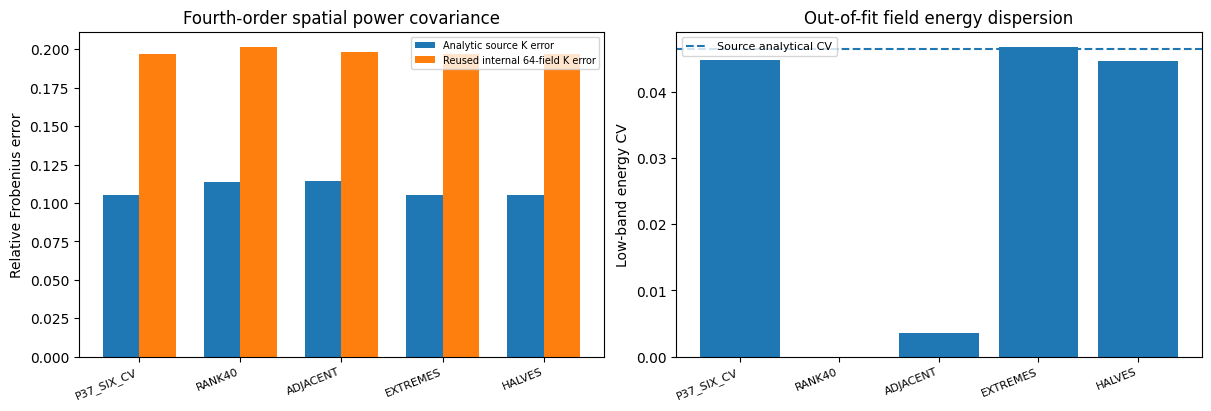

P39 report: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p39_source_blind_spectral_rotations_20261103T001843Z_13f2f8/result.json
P39 model package: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p39_source_blind_spectral_rotations_20261103T001843Z_13f2f8/source_blind_rotated_factors.npz
P39 figure: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p39_source_blind_spectral_rotations_20261103T001843Z_13f2f8/rotation_comparison.png
P39 ledger: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p39_source_blind_spectral_rotations_20261103T001843Z_13f2f8/P39_RESEARCH_LEDGER_ADDENDUM.md
P39 provenance: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p39_source_blind_spectral_rotations_20261103T001843Z_13f2f8/P39_PROVENANCE_NOTE.json
P39 COMPLETE — source-blind training-only rotations, no seed-1 or historical overwrite.


In [26]:
# P39 — Source-blind covariance-preserving spectral rotations
# Add as ONE new code cell BELOW completed P38; run P39 only.
# No old runtime variables, no pip installs, no seed-1/test data.
# No modification of P1-P38 or November 3 presentation.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, subprocess, uuid
import numpy as np
import h5py
import matplotlib.pyplot as plt

root39 = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
repo39 = Path('/content/nasa_clfm_reference')
hdf39 = Path('/content/clfm_snapshot/data/wind/wind_train_data.hdf5')
pin39 = '921e666c8d6060ae13bfd901dcc7f74f819d0eea'
hdf_sha39 = '676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'
prior39 = {
    'P25': root39/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149/result.json',
    'P32': root39/'fidelity_diagnostics/p32_source_phase_audit_20261102T162342Z_ac5eae/result.json',
    'P37': root39/'fidelity_diagnostics/p37_analytic_fourth_order_20261102T191024Z_928bf7/result.json',
    'P38': root39/'fidelity_diagnostics/p38_oracle_covariance_family_limit_20261102T191531Z_80f8b4/result.json',
}

def sha39(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024), b''):
            h.update(block)
    return h.hexdigest()

def rel39(a,b):
    return float(np.linalg.norm(a-b)/max(np.linalg.norm(b),1e-300))

def cv39(a):
    return float(np.std(a,ddof=1)/np.mean(a))

def csd39(x):
    return np.einsum('nki,nkj->kij',x,x.conj(),optimize=True)/len(x)

def pcov39(x):
    p=np.abs(x)**2
    d=p-p.mean(axis=0,keepdims=True)
    return np.einsum('nki,nkj->kij',d,d,optimize=True)/(len(x)-1)

assert root39.is_dir() and hdf39.is_file() and (repo39/'.git').is_dir(), (
    'Restore pinned inputs with clean notebook Cell 5b; do not rerun previous experiments.'
)
assert all(p.is_file() for p in prior39.values()), 'Missing saved report.'
assert sha39(hdf39)==hdf_sha39, 'Training HDF5 checksum changed.'
assert subprocess.check_output(['git','-C',str(repo39),'rev-parse','HEAD'],text=True).strip()==pin39
original_hashes39={key:sha39(p) for key,p in prior39.items()}
old39={key:json.loads(p.read_text()) for key,p in prior39.items()}
assert all(r['status']=='completed' for r in old39.values())
assert old39['P38']['posthoc_best_paired_exact_sourceCov_K_error']>0
assert old39['P37']['fit_n']==192 and old39['P37']['internal_validation_n']==64
for rel,dig in old39['P32']['pinned_source_sha256'].items():
    assert sha39(repo39/rel)==dig, f'Pinned source differs: {rel}'

fit_ids39=np.asarray(old39['P37']['fit_indices'],dtype=int)
val_ids39=np.asarray(old39['P37']['internal_validation_indices'],dtype=int)
p25_ids39=np.asarray(old39['P25']['training_indices'],dtype=int)
assert fit_ids39.shape==(192,) and val_ids39.shape==(64,)
assert np.unique(np.r_[fit_ids39,val_ids39]).size==256
assert np.array_equal(np.sort(np.r_[fit_ids39,val_ids39]),np.sort(p25_ids39))
sel39=np.r_[0:10,30:40,60:70,90:100]
with h5py.File(hdf39,'r') as f:
    assert len(f['wind_samples'])==5000
    xyz39=np.asarray(f['x_grid'],dtype=float)
    fr39=np.asarray(f['input_parameters/freq_grid'],dtype=float)
    shear39=float(np.asarray(f['input_parameters/shear_velocity']))
    raw39=np.stack([
        np.asarray(f['wind_samples'][str(int(i))]['v1'],dtype=float)[sel39]
        for i in np.r_[fit_ids39,val_ids39]
    ])
assert raw39.shape==(256,40,256) and xyz39.shape==(100,3) and fr39.shape==(128,)
assert np.all(np.isfinite(raw39)) and np.isclose(shear39,1.9)
assert np.allclose(fr39,np.linspace(3/128,3,128))
X39=np.fft.rfft(raw39-raw39.mean(axis=-1,keepdims=True),axis=-1)[:,:,1:7].transpose(0,2,1)/49.
fit39=X39[:192]; val39=X39[192:]
C39=csd39(fit39)
C39=(C39+C39.conj().transpose(0,2,1))/2
Ktrain39=pcov39(fit39); Kval39=pcov39(val39)
L39=np.empty((6,40,40),dtype=complex)
for k in range(6):
    eig,U=np.linalg.eigh(C39[k])
    # Fix arbitrary complex eigenvector phases for deterministic model provenance.
    piv=np.argmax(np.abs(U),axis=0)
    U=U*np.exp(-1j*np.angle(U[piv,np.arange(40)]))[None,:]
    L39[k]=U*np.sqrt(np.maximum(eig,0))[None,:]
assert np.allclose(L39@L39.conj().transpose(0,2,1),C39,rtol=1e-10,atol=1e-8)

# Three predetermined rotation patterns, each uses only SIX fitted angles.
# All rotation matrices are orthogonal, hence A A* = C exactly.
pairings39={
    'ADJACENT': [(i,i+1) for i in range(0,40,2)],
    'EXTREMES': [(i,39-i) for i in range(20)],
    'HALVES': [(i,i+20) for i in range(20)],
}
for pairs in pairings39.values():
    assert len(pairs)==20 and sorted(i for ab in pairs for i in ab)==list(range(40))

def rotate39(L,pairs,theta):
    A=L.copy();c=np.cos(theta);s=np.sin(theta)
    for a,b in pairs:
        A[:,a]=c*L[:,a]+s*L[:,b]
        A[:,b]=-s*L[:,a]+c*L[:,b]
    return A

def kmoment39(A,C):
    P=np.abs(A)**2
    return (np.abs(C)**2-P@P.T).real

# Fit solely to the 192-field empirical power covariance.
# Fixed 0.25-degree grid, no reference/oracle-based tuning.
grid39=np.linspace(-np.pi/4,np.pi/4,361)
model_factors39={}
angles39={}
fit_objectives39={}
for label,pairs in pairings39.items():
    factors=[]; angles=[]; fit_losses=[]
    for k in range(6):
        losses=np.empty(len(grid39))
        for j,theta in enumerate(grid39):
            K=kmoment39(rotate39(L39[k],pairs,theta),C39[k])
            losses[j]=np.sum((K-Ktrain39[k])**2)
        best=int(np.argmin(losses))
        angle=float(grid39[best])
        A=rotate39(L39[k],pairs,angle)
        assert np.allclose(A@A.conj().T,C39[k],rtol=1e-10,atol=1e-8)
        factors.append(A);angles.append(angle);fit_losses.append(float(losses[best]))
    model_factors39[label]=np.stack(factors)
    angles39[label]=np.asarray(angles)
    fit_objectives39[label]=fit_losses

# The source oracle is constructed only AFTER all rotation fits are frozen.
z39=xyz39[:,2]
mu39=2.5*shear39*np.log(z39/0.015)
var39=(6.-1.1*np.arctan(np.log(0.015)+1.75))*shear39**2
length39=300*(z39/200)**(0.67+0.05*np.log(shear39))
dist39=np.linalg.norm((xyz39[:,None,:]-xyz39[None,:,:])*[3.,3.,0.5],axis=-1)
B39=np.empty((6,40,100),dtype=float)
for j,k in enumerate(range(1,7)):
    nu=fr39[k]
    auto=(var39*6.868*nu*(length39/mu39))/(nu*(1+1.5*nu*6.868*length39/mu39)**5/3)
    coh=np.exp(-nu*dist39/(mu39[:,None]+mu39[None,:]))
    S=np.sqrt(auto[:,None]*auto[None,:])*coh
    U,s,_=np.linalg.svd(S,full_matrices=False)
    B39[j]=(U*np.sqrt(s)[None,:])[sel39]
B39*=128*np.sqrt(4*(fr39[1]-fr39[0]))/49.
Csrc39=B39@B39.transpose(0,2,1)
Psrc39=B39**2
Ksrc39=(np.abs(Csrc39)**2-np.einsum('kia,kja->kij',Psrc39,Psrc39,optimize=True)).real
assert abs(rel39(C39,Csrc39)-old39['P37']['fitted_CSD_relative_error_vs_source'])<1e-9

# P37 six-CV paired family is a fixed, previously fitted comparator.
P39=np.abs(L39)**2
T39=np.einsum('kia,kja->kij',P39,P39,optimize=True)
K0_39=(np.abs(C39)**2-T39).real
beta39=np.asarray(old39['P37']['CV_fitted_beta'],dtype=float)
assert beta39.shape==(6,) and np.all((beta39>=0)&(beta39<=.5))
Kpaired39=K0_39+beta39[:,None,None]*T39

Kmodels39={
    'P37_SIX_CV':Kpaired39,
    'RANK40':K0_39,
}
for label,A in model_factors39.items():
    Kmodels39[label]=np.stack([kmoment39(A[k],C39[k]) for k in range(6)])

def kcv39(K,C):
    tr=np.trace(C,axis1=1,axis2=2).real.sum()
    return float(np.sqrt(max(0.,K.sum().real))/tr)

mask39=~np.eye(40,dtype=bool)
rows39=[]
for label,K in Kmodels39.items():
    rows39.append({
        'model':label,
        'fitted_angles_deg':None if label not in angles39 else np.degrees(angles39[label]).tolist(),
        'analytic_energy_CV':kcv39(K,C39),
        'training_K_relative_error':rel39(K,Ktrain39),
        'reused_64_training_field_K_error':rel39(K,Kval39),
        'analytic_source_K_relative_error':rel39(K,Ksrc39),
        'analytic_source_offdiagonal_K_error':rel39(K[:,mask39],Ksrc39[:,mask39]),
        'analytic_source_diagonal_K_error':rel39(
            np.diagonal(K,axis1=1,axis2=2),
            np.diagonal(Ksrc39,axis1=1,axis2=2)
        ),
        'analytic_source_energy_CV_error':abs(kcv39(K,C39)-kcv39(Ksrc39,Csrc39)),
    })

# Predeclared parameter-selection baseline; no source-oracle-based selection.
best_train39=min(pairings39,key=lambda k:next(r for r in rows39 if r['model']==k)['training_K_relative_error'])
ref_noise39=old39['P38']['fresh_phase_sampling_noise_by_n']
source_cv39=kcv39(Ksrc39,Csrc39)
assert abs(source_cv39-old39['P37']['source_analytic_CV'])<1e-8, 'Source fourth-moment control differs from frozen P37.'
print('='*93)
print('P39 — SOURCE-BLIND COVARIANCE-PRESERVING SPECTRAL ROTATIONS')
print('='*93)
print('Training-CSD error versus source:',rel39(C39,Csrc39))
print('Source analytical low-band CV:',source_cv39)
print('P38 exact-C paired-family oracle floor (diagnostic):',old39['P38']['posthoc_best_paired_exact_sourceCov_K_error'])
print('Source n=64 K-error noise median:',ref_noise39['64']['median'])
for row in rows39:
    print(f"{row['model']:14s} CV={row['analytic_energy_CV']:.6f} "
          f"trainK={row['training_K_relative_error']:.5f} "
          f"reused64K={row['reused_64_training_field_K_error']:.5f} "
          f"sourceK={row['analytic_source_K_relative_error']:.5f} "
          f"sourceOffK={row['analytic_source_offdiagonal_K_error']:.5f}")
print('Rotation pattern selected by TRAINING error only:',best_train39)
for k in pairings39:
    print(k,'angles (degrees):',np.round(np.degrees(angles39[k]),3).tolist())

# Write only new P39 research artifacts after verifying old reports.
assert sha39(hdf39)==hdf_sha39
assert all(sha39(prior39[k])==dig for k,dig in original_hashes39.items())
run39=root39/'fidelity_diagnostics'/('p39_source_blind_spectral_rotations_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
assert run39.parent.resolve()==(root39/'fidelity_diagnostics').resolve()
run39.mkdir(parents=True,exist_ok=False)
report39=run39/'result.json'
figure39=run39/'rotation_comparison.png'
model39=run39/'source_blind_rotated_factors.npz'
ledger39=run39/'P39_RESEARCH_LEDGER_ADDENDUM.md'
prov39=run39/'P39_PROVENANCE_NOTE.json'
np.savez_compressed(model39,
    fitted_covariance=C39,
    p37_eigenfactor=L39,
    adjacent_factor=model_factors39['ADJACENT'],
    extremes_factor=model_factors39['EXTREMES'],
    halves_factor=model_factors39['HALVES'],
    adjacent_angles=angles39['ADJACENT'],
    extremes_angles=angles39['EXTREMES'],
    halves_angles=angles39['HALVES'],
    frequency_bins=np.arange(1,7),
    sensor_indices=sel39,
    fit_indices=fit_ids39,
    internal_indices=val_ids39,
)
with np.load(model39,allow_pickle=False) as verify39:
    assert verify39['fitted_covariance'].shape==(6,40,40)
    for key in ('adjacent_factor','extremes_factor','halves_factor'):
        A=verify39[key]
        assert np.allclose(A@A.conj().transpose(0,2,1),C39,rtol=1e-10,atol=1e-8)

result39={
    'experiment':'P39_source_blind_orthogonal_spectral_rotation_fourth_moments',
    'status':'completed',
    'created_utc':datetime.now(timezone.utc).isoformat(),
    'pinned_source_commit':pin39,
    'training_hdf5_sha256':hdf_sha39,
    'input_report_hashes':original_hashes39,
    'fit_n':192,
    'internal_reused_n':64,
    'frequency_bins':[1,2,3,4,5,6],
    'patterns':{k:[list(v) for v in pairs] for k,pairs in pairings39.items()},
    'grid_angles_degrees':[-45,45],
    'grid_step_degrees':.25,
    'eigenvector_phase_convention':'largest-magnitude coordinate made real-positive',
    'train_selected_pattern':best_train39,
    'source_analytic_cv':source_cv39,
    'candidate_rows':rows39,
    'model_package':str(model39),
    'model_package_sha256':sha39(model39),
    'p38_exact_covariance_paired_oracle_floor_diagnostic':old39['P38']['posthoc_best_paired_exact_sourceCov_K_error'],
    'limits':[
        'Fit uses 192 previously studied P25 training fields; 64 internal fields are not untouched.',
        'Three rotation pairings and grid were fixed by protocol; pattern picked by 192-field training error only.',
        'Source B and exact source K were reconstructed only AFTER fitting for diagnostic comparison.',
        'This compares only six rFFT bins of 40 sensors; not full-field generation.',
        'Every fitted rotation preserves empirical complex CSD exactly; empirical CSD differs from source.',
        'Theoretical source K is oracle information, not a model-selection target.',
        '64-field empirical K is noisy, per P38. No confirmatory statistics are claimed.',
        'No prospective seed-1 test files accessed, no retraining or historical artifact overwrites.',
        'P38 oracle floor is for a different family and covariance, not a universal lower bound.',
    ],
}
report39.write_text(json.dumps(result39,indent=2,allow_nan=False),encoding='utf-8')

fig,axs=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
labels=[r['model'] for r in rows39]
locs=np.arange(len(rows39))
axs[0].bar(locs-.18,[r['analytic_source_K_relative_error'] for r in rows39],.36,label='Analytic source K error')
axs[0].bar(locs+.18,[r['reused_64_training_field_K_error'] for r in rows39],.36,label='Reused internal 64-field K error')
axs[0].set_xticks(locs,labels,rotation=22,ha='right',fontsize=8)
axs[0].set(ylabel='Relative Frobenius error',title='Fourth-order spatial power covariance')
axs[0].legend(fontsize=7)
axs[1].bar(locs,[r['analytic_energy_CV'] for r in rows39])
axs[1].axhline(source_cv39,ls='--',label='Source analytical CV')
axs[1].set_xticks(locs,labels,rotation=22,ha='right',fontsize=8)
axs[1].set(ylabel='Low-band energy CV',title='Out-of-fit field energy dispersion')
axs[1].legend(fontsize=8)
fig.savefig(figure39,dpi=150)
plt.show()
plt.close(fig)
ledger39.write_text(
    '# P39 — Source-blind covariance-preserving orthogonal spectral rotations\n\n'
    '- P38 established 8.3396% post-hoc paired-family error even with exact source C.\n'
    '- P39 trains six rotation angles for each of three predetermined eigenvector pairings.\n'
    '- Objective uses only 192 previously studied training fields and analytical phase-only K.\n'
    '- Fitted CSD is preserved exactly by orthogonal rotation.\n'
    '- Validation on 64 previously studied training fields is descriptive and noisy.\n'
    '- Exact source K used only for retrospective diagnostics, never angle fitting.\n'
    f'- Training-only selected rotation pattern: {best_train39}.\n'
    '- See result.json and source_blind_rotated_factors.npz for results and reproducibility.\n'
    '- No new model architecture success claim, seed-1 test access or November 3 changes.\n',
    encoding='utf-8'
)
art39={p.name:sha39(p) for p in (report39,figure39,model39,ledger39)}
prov39.write_text(json.dumps({
    'scope':'P39_NEW_FOLDER_ONLY',
    'artifact_sha256':art39,
    'input_report_sha256':original_hashes39,
    'historical_vault_not_scanned':True,
},indent=2),encoding='utf-8')
assert all(sha39(run39/name)==digest for name,digest in art39.items())
assert all(sha39(prior39[k])==digest for k,digest in original_hashes39.items())
print('P39 report:',report39)
print('P39 model package:',model39)
print('P39 figure:',figure39)
print('P39 ledger:',ledger39)
print('P39 provenance:',prov39)
print('P39 COMPLETE — source-blind training-only rotations, no seed-1 or historical overwrite.')

Fitted ADJ_6 | training-only K per-bin errors [0.08192, 0.08737, 0.15664, 0.11092, 0.1393, 0.14014]
Fitted ADJ_CROSS_12 | training-only K per-bin errors [0.08192, 0.08737, 0.15664, 0.11092, 0.1393, 0.14013]
Fitted ADJ_CROSS_HALVES_18 | training-only K per-bin errors [0.08188, 0.08733, 0.15664, 0.11092, 0.13929, 0.14013]

P40 — NESTED STRUCTURED 80-PHASE RIGHT-ROTATION FACTORS
Historical fit fields: 192 | reused internal fields: 64
Known source CV: 0.04650441658135235 | estimated C error: 0.03813051436344184
BASE_P37_0_NEW          params= 0 trainK=0.091294 internal64K=0.196807 sourceK=0.105377 CV=0.044835
ADJ_6                   params= 6 trainK=0.088919 internal64K=0.193526 sourceK=0.106232 CV=0.044966
ADJ_CROSS_12            params=12 trainK=0.088919 internal64K=0.193526 sourceK=0.106232 CV=0.044970
ADJ_CROSS_HALVES_18     params=18 trainK=0.088883 internal64K=0.193530 sourceK=0.106217 CV=0.046045
Training-only selected model: ADJ_CROSS_HALVES_18
Training improvement versus P37: 0.00

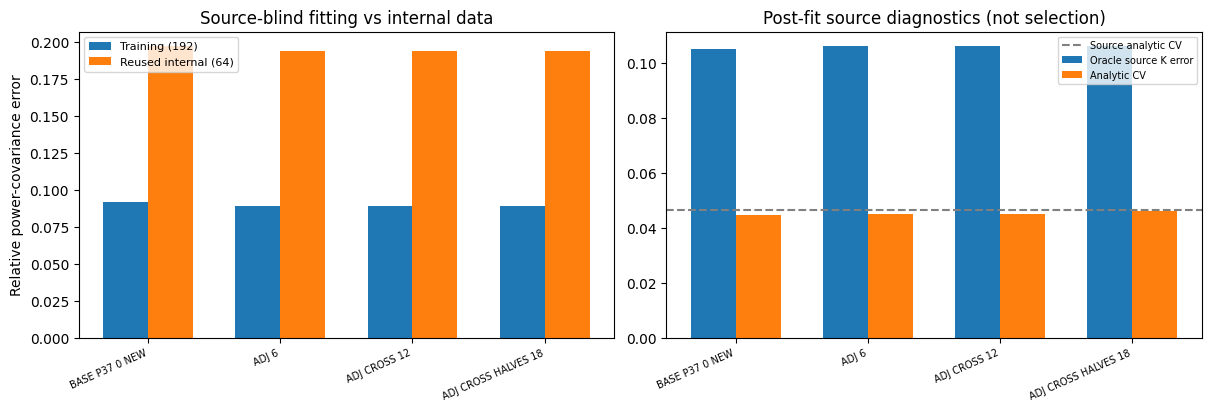

Report: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p40_structured_overcomplete_rotations_20261103T001854Z_387d5c/result.json 
Model: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p40_structured_overcomplete_rotations_20261103T001854Z_387d5c/p40_training_fitted_factors.npz 
Figure: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p40_structured_overcomplete_rotations_20261103T001854Z_387d5c/p40_nested_factor_fit.png 
Ledger: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p40_structured_overcomplete_rotations_20261103T001854Z_387d5c/P40_RESEARCH_LEDGER_ADDENDUM.md 
Provenance: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p40_structured_overcomplete_rotations_20261103T001854Z_387d5c/P40_PROVENANCE_NOTE.json
P40 COMPLETE — no previous evidence overwritten, no prospective test accessed.


In [27]:

# CELL P40 — Source-blind structured overcomplete spectral-factor learning.
# Place immediately below completed P39 in the CLEAN continuation notebook.
# Run ONLY this cell.  Requires existing pinned checkout + trusted training HDF5.
# No seed-1 test data, no old experiment reruns, no historical overwrites.
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, subprocess, uuid
import numpy as np
import h5py
import matplotlib.pyplot as plt
from scipy.optimize import minimize

BASE40=Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
REPO40=Path('/content/nasa_clfm_reference')
HDF40=Path('/content/clfm_snapshot/data/wind/wind_train_data.hdf5')
PIN40='921e666c8d6060ae13bfd901dcc7f74f819d0eea'
TRAIN_SHA40='676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'
PREV40={
    'P25':BASE40/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149/result.json',
    'P32':BASE40/'fidelity_diagnostics/p32_source_phase_audit_20261102T162342Z_ac5eae/result.json',
    'P37':BASE40/'fidelity_diagnostics/p37_analytic_fourth_order_20261102T191024Z_928bf7/result.json',
    'P38':BASE40/'fidelity_diagnostics/p38_oracle_covariance_family_limit_20261102T191531Z_80f8b4/result.json',
    'P39':BASE40/'fidelity_diagnostics/p39_source_blind_spectral_rotations_20261102T201118Z_763efe/result.json',
}
def sha40(p):
    h=hashlib.sha256()
    with Path(p).open('rb') as f:
        for block in iter(lambda:f.read(8*1024*1024),b''):h.update(block)
    return h.hexdigest()
def rel40(a,b):
    return float(np.linalg.norm(a-b)/max(np.linalg.norm(b),1e-300))
def csd40(x):
    return np.einsum('nki,nkj->kij',x,x.conj(),optimize=True)/len(x)
def pcov40(x):
    p=np.abs(x)**2; d=p-p.mean(axis=0,keepdims=True)
    return np.einsum('nki,nkj->kij',d,d,optimize=True)/(len(x)-1)
def moment40(A,C):
    p=np.abs(A)**2
    return (np.abs(C)**2-p@p.T).real
def cv40(K,C):
    total=float(np.trace(C,axis1=1,axis2=2).real.sum())
    return float(np.sqrt(max(0.,K.sum()))/total)

assert BASE40.is_dir() and HDF40.is_file() and (REPO40/'.git').is_dir(), 'Restore pinned /content inputs using clean notebook cell 5b.'
assert all(p.is_file() for p in PREV40.values())
assert sha40(HDF40)==TRAIN_SHA40, 'Untrusted training HDF5; stop.'
assert subprocess.check_output(['git','-C',str(REPO40),'rev-parse','HEAD'],text=True).strip()==PIN40
SHAS40={key:sha40(path) for key,path in PREV40.items()}
old40={key:json.loads(path.read_text()) for key,path in PREV40.items()}
assert all(r['status']=='completed' for r in old40.values())
assert old40['P37']['fit_n']==192 and old40['P37']['internal_validation_n']==64
assert old40['P39']['train_selected_pattern']=='EXTREMES'
for rel,digest in old40['P32']['pinned_source_sha256'].items():
    assert sha40(REPO40/rel)==digest, f'Pinned source changed: {rel}'
MODEL40=Path(old40['P39']['model_package'])
assert MODEL40.is_file() and sha40(MODEL40)==old40['P39']['model_package_sha256']
MODEL_SHA40=sha40(MODEL40)
with np.load(MODEL40,allow_pickle=False) as p:
    C40=np.asarray(p['fitted_covariance'],dtype=np.complex128)
    L40=np.asarray(p['p37_eigenfactor'],dtype=np.complex128)
    ids_fit40=np.asarray(p['fit_indices'],dtype=np.int64)
    ids_val40=np.asarray(p['internal_indices'],dtype=np.int64)
assert C40.shape==L40.shape==(6,40,40)
assert np.array_equal(ids_fit40,old40['P37']['fit_indices'])
assert np.array_equal(ids_val40,old40['P37']['internal_validation_indices'])
assert np.array_equal(np.sort(np.r_[ids_fit40,ids_val40]),np.sort(old40['P25']['training_indices']))
assert np.allclose(L40@L40.conj().transpose(0,2,1),C40,atol=1e-8,rtol=1e-10)

sel40=np.r_[0:10,30:40,60:70,90:100]
with h5py.File(HDF40,'r') as h5:
    assert len(h5['wind_samples'])==5000
    xyz40=np.asarray(h5['x_grid'],dtype=np.float64)
    fr40=np.asarray(h5['input_parameters/freq_grid'],dtype=np.float64)
    shear40=float(np.asarray(h5['input_parameters/shear_velocity']))
    records40=np.stack([np.asarray(h5['wind_samples'][str(int(i))]['v1'],dtype=np.float64)[sel40] for i in np.r_[ids_fit40,ids_val40]])
assert records40.shape==(256,40,256) and xyz40.shape==(100,3)
assert np.allclose(fr40,np.linspace(3/128,3,128)) and np.isclose(shear40,1.9)
X40=np.fft.rfft(records40-records40.mean(axis=-1,keepdims=True),axis=-1)[:,:,1:7].transpose(0,2,1)/49.
Xfit40,Xval40=X40[:192],X40[192:]
assert rel40(csd40(Xfit40),C40)<1e-9, 'P39 frozen fitted CSD differs from recovered training data.'
Ktrain40,Kval40=pcov40(Xfit40),pcov40(Xval40)

# Frozen six CV-fit angles from P37 -> 80-phase paired eigenfactor.
# The new P40 fitting does NOT recalibrate them.
beta40=np.asarray(old40['P37']['CV_fitted_beta'],dtype=float)
assert beta40.shape==(6,) and np.all((beta40>=0)&(beta40<=.5))
theta40=.5*np.arcsin(np.sqrt(2*beta40))
A0_40=np.concatenate([L40*np.cos(theta40)[:,None,None],L40*np.sin(theta40)[:,None,None]],axis=2)
assert A0_40.shape==(6,40,80)
assert np.allclose(A0_40@A0_40.conj().transpose(0,2,1),C40,atol=1e-8,rtol=1e-10)
Kbase40=np.stack([moment40(A0_40[k],C40[k]) for k in range(6)])
old_base40=next(r for r in old40['P39']['candidate_rows'] if r['model']=='P37_SIX_CV')
assert abs(rel40(Kbase40,Ktrain40)-old_base40['training_K_relative_error'])<1e-8
assert abs(cv40(Kbase40,C40)-old_base40['analytic_energy_CV'])<1e-8

# Prespecified nested 80-phase column mixing patterns. Right-sided REAL
# Givens rotations preserve A A* exactly. Within each pattern pairs are disjoint.
PAIR40={
  'ADJACENT':[(j,j+1) for j in range(0,40,2)]+[(40+j,41+j) for j in range(0,40,2)],
  'CROSS':[(j,40+39-j) for j in range(40)],
  'HALVES':[(j,j+20) for j in range(20)]+[(40+j,60+j) for j in range(20)]
}
for pairs in PAIR40.values():
    assert len(pairs)==40 and sorted([i for a,b in pairs for i in (a,b)])==list(range(80))
MODELS40={
  'BASE_P37_0_NEW':[''],
  'ADJ_6':['ADJACENT'],
  'ADJ_CROSS_12':['ADJACENT','CROSS'],
  'ADJ_CROSS_HALVES_18':['ADJACENT','CROSS','HALVES']
}
REG40=.002                 # Fixed regularization, selected BEFORE optimization
BOUND40=.35                # Radians, about 20 degrees

def apply40(base,angles,names):
    A=base.copy()
    for angle,name in zip(angles,names):
        c,s=np.cos(angle),np.sin(angle)
        for i,j in PAIR40[name]:
            left=A[:,i].copy(); right=A[:,j].copy()
            A[:,i]=c*left+s*right
            A[:,j]=-s*left+c*right
    return A

CAND40={}; ANG40={}; FITS40={}; OPT40={}
CAND40['BASE_P37_0_NEW']=A0_40.copy()
ANG40['BASE_P37_0_NEW']=np.zeros((6,0))
FITS40['BASE_P37_0_NEW']=[rel40(Kbase40[k],Ktrain40[k]) for k in range(6)]
OPT40['BASE_P37_0_NEW']=['preexisting baseline']*6
for label,names in MODELS40.items():
    if not names[0]:continue
    learned=[]; params=[]; losses=[]; statuses=[]
    for k in range(6):
        base=A0_40[k]; target=Ktrain40[k]; norm2=max(float(np.sum(target*target)),1e-300)
        def objective(v):
            Ak=apply40(base,v,names)
            Kk=moment40(Ak,C40[k])
            return float(np.sum((Kk-target)**2)/norm2+REG40*np.sum(v*v))
        solution=minimize(objective,np.zeros(len(names)),method='L-BFGS-B',
                          bounds=[(-BOUND40,BOUND40)]*len(names),
                          options={'maxiter':100,'ftol':1e-12,'gtol':1e-9})
        assert np.all(np.isfinite(solution.x)) and np.isfinite(solution.fun)
        assert solution.fun <= objective(np.zeros(len(names)))+1e-7, ('Optimizer regressed from zero',label,k,solution.message)
        Ak=apply40(base,solution.x,names)
        assert np.allclose(Ak@Ak.conj().T,C40[k],atol=1e-8,rtol=1e-10)
        learned.append(Ak);params.append(solution.x);losses.append(rel40(moment40(Ak,C40[k]),target))
        statuses.append({'converged':bool(solution.success),'iterations':int(solution.nit),'message':str(solution.message)})
    CAND40[label]=np.stack(learned); ANG40[label]=np.stack(params); FITS40[label]=losses; OPT40[label]=statuses
    print('Fitted',label,'| training-only K per-bin errors',np.round(losses,5).tolist())

# Source mathematical oracle ONLY AFTER candidate fitting and predeclared
# model complexity choices are fixed. Source is not in any optimizer objective.
z40=xyz40[:,2]; mu40=2.5*shear40*np.log(z40/.015)
var40=(6.-1.1*np.arctan(np.log(.015)+1.75))*shear40**2
len40=300*(z40/200)**(.67+.05*np.log(shear40))
dist40=np.linalg.norm((xyz40[:,None,:]-xyz40[None,:,:])*[3.,3.,.5],axis=-1)
B40=np.empty((6,40,100),dtype=np.float64)
for ix,k in enumerate(range(1,7)):
    freq=fr40[k]
    auto=(var40*6.868*freq*(len40/mu40))/(freq*(1+1.5*freq*6.868*len40/mu40)**5/3)
    coh=np.exp(-freq*dist40/(mu40[:,None]+mu40[None,:]))
    S=np.sqrt(auto[:,None]*auto[None,:])*coh
    U,s,_=np.linalg.svd(S,full_matrices=False)
    B40[ix]=(U*np.sqrt(s)[None,:])[sel40]
B40*=128*np.sqrt(4*(fr40[1]-fr40[0]))/49
Csrc40=B40@B40.transpose(0,2,1)
Ksrc40=np.stack([moment40(B40[k],Csrc40[k]) for k in range(6)])
assert abs(rel40(C40,Csrc40)-old40['P37']['fitted_CSD_relative_error_vs_source'])<1e-8
assert abs(cv40(Ksrc40,Csrc40)-old40['P37']['source_analytic_CV'])<1e-8

ROWS40=[]
for label,A in CAND40.items():
    K=np.stack([moment40(A[k],C40[k]) for k in range(6)])
    ROWS40.append({
        'model':label,'new_parameter_count':int(ANG40[label].size),
        'fitted_angles_degrees':np.degrees(ANG40[label]).tolist(),
        'training_K_error':rel40(K,Ktrain40),
        'reused_64_K_error':rel40(K,Kval40),
        'source_population_K_error':rel40(K,Ksrc40),
        'source_offdiag_K_error':rel40(K[:,~np.eye(40,dtype=bool)],Ksrc40[:,~np.eye(40,dtype=bool)]),
        'energy_CV_analytic':cv40(K,C40),
        'energy_CV_absolute_error_vs_source':abs(cv40(K,C40)-cv40(Ksrc40,Csrc40)),
        'population_CSD_error_vs_source':rel40(C40,Csrc40),
        'optimization_status':OPT40[label],
    })
# Select model by TRAINING-only K error; do not use source oracle or reused64
# to choose. Report both independently as diagnostics after selection.
BEST40=min(ROWS40,key=lambda r:r['training_K_error'])['model']
base_row40=next(r for r in ROWS40 if r['model']=='BASE_P37_0_NEW')
best_row40=next(r for r in ROWS40 if r['model']==BEST40)
print('\n'+'='*98)
print('P40 — NESTED STRUCTURED 80-PHASE RIGHT-ROTATION FACTORS')
print('='*98)
print('Historical fit fields:',len(ids_fit40),'| reused internal fields:',len(ids_val40))
print('Known source CV:',cv40(Ksrc40,Csrc40),'| estimated C error:',rel40(C40,Csrc40))
for row in ROWS40:
    print(f"{row['model']:23s} params={row['new_parameter_count']:2d} "
          f"trainK={row['training_K_error']:.6f} internal64K={row['reused_64_K_error']:.6f} "
          f"sourceK={row['source_population_K_error']:.6f} "
          f"CV={row['energy_CV_analytic']:.6f}")
print('Training-only selected model:',BEST40)
print('Training improvement versus P37:',base_row40['training_K_error']-best_row40['training_K_error'])
print('Post-hoc source-K improvement versus P37:',base_row40['source_population_K_error']-best_row40['source_population_K_error'])

# Save only in NEW scoped P40 folder after integrity preflight.
assert sha40(HDF40)==TRAIN_SHA40
assert sha40(MODEL40)==MODEL_SHA40
assert all(sha40(PREV40[k])==v for k,v in SHAS40.items())
RUN40=BASE40/'fidelity_diagnostics'/('p40_structured_overcomplete_rotations_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')+'_'+uuid.uuid4().hex[:6])
assert RUN40.parent.resolve()==(BASE40/'fidelity_diagnostics').resolve()
RUN40.mkdir(parents=True,exist_ok=False)
REPORT40=RUN40/'result.json'; FIG40=RUN40/'p40_nested_factor_fit.png'
MODEL_OUT40=RUN40/'p40_training_fitted_factors.npz'
LEDGER40=RUN40/'P40_RESEARCH_LEDGER_ADDENDUM.md';PROV40=RUN40/'P40_PROVENANCE_NOTE.json'
np.savez_compressed(MODEL_OUT40,
    fitted_C=C40, p37_paired_base=A0_40,
    adj_6=CAND40['ADJ_6'], adj_cross_12=CAND40['ADJ_CROSS_12'],
    adj_cross_halves_18=CAND40['ADJ_CROSS_HALVES_18'],
    angles_adj_6=ANG40['ADJ_6'],angles_adj_cross_12=ANG40['ADJ_CROSS_12'],
    angles_adj_cross_halves_18=ANG40['ADJ_CROSS_HALVES_18'],
    fit_training_indices=ids_fit40, reused_internal_indices=ids_val40,
    sensor_indices=sel40,fft_bins=np.arange(1,7))
with np.load(MODEL_OUT40,allow_pickle=False) as chk:
    assert chk['fitted_C'].shape==(6,40,40)
    for key in ('p37_paired_base','adj_6','adj_cross_12','adj_cross_halves_18'):
        A=chk[key]
        assert np.allclose(A@A.conj().transpose(0,2,1),C40,rtol=1e-10,atol=1e-8)
REPORT40.write_text(json.dumps({
    'experiment':'P40_nested_80_phase_source_blind_covariance_preserving_factor_learning',
    'status':'completed', 'created_utc':datetime.now(timezone.utc).isoformat(),
    'pinned_source_commit':PIN40,'training_sha256':TRAIN_SHA40,
    'prior_report_sha256':SHAS40,'prior_P39_model_sha256':MODEL_SHA40,
    'training_fields':192,'reused_internal_fields':64,
    'baseline_P37_six_angles_frozen':np.degrees(theta40).tolist(),
    'fixed_regularization_strength':REG40,'fixed_angle_bound_radians':BOUND40,
    'models_and_new_parameters':{k:len(v)*6 if v[0] else 0 for k,v in MODELS40.items()},
    'patterns':{k:[[i,j] for i,j in v] for k,v in PAIR40.items()},
    'fitted_CSD_error_vs_oracle_source':rel40(C40,Csrc40),
    'source_analytic_energy_CV':cv40(Ksrc40,Csrc40),
    'comparison_rows':ROWS40,'training_selected_model':BEST40,
    'model_package_path':str(MODEL_OUT40),'model_package_sha256':sha40(MODEL_OUT40),
    'limitations':[
      'All candidates fit 192 previously used P25 training fields; reused 64 are NOT untouched validation.',
      'P37 six energy-CV angles are frozen from prior development, not refitted here.',
      'Training-only objective fits empirical power-covariance with weak prespecified L2 regularization.',
      'Three predefined nested right-rotation complexities have 6,12,18 new parameters beyond P37.',
      'Covariance preservation refers to fitted C, which differs from source C by finite-sample error.',
      'Exact source C and K used only in post-fit diagnostics; source-model selection is prohibited.',
      'Power covariance from 64 fields is noisy (P38); internal performance is descriptive only.',
      'These are six Fourier-bin factors, NOT full time-series wind generators.',
      'No fresh test seed 1, unseen wind regimes, or external physical validation.',
      'No old evidence or November 3 presentation was edited.'
    ]},indent=2,allow_nan=False),encoding='utf-8')
fig,ax=plt.subplots(1,2,figsize=(12,4),constrained_layout=True)
loc=np.arange(len(ROWS40));labels=[r['model'].replace('_',' ') for r in ROWS40]
ax[0].bar(loc-.17,[r['training_K_error'] for r in ROWS40],.34,label='Training (192)')
ax[0].bar(loc+.17,[r['reused_64_K_error'] for r in ROWS40],.34,label='Reused internal (64)')
ax[0].set_xticks(loc,labels,rotation=24,ha='right',fontsize=7)
ax[0].set(ylabel='Relative power-covariance error',title='Source-blind fitting vs internal data');ax[0].legend(fontsize=8)
ax[1].bar(loc-.17,[r['source_population_K_error'] for r in ROWS40],.34,label='Oracle source K error')
ax[1].bar(loc+.17,[r['energy_CV_analytic'] for r in ROWS40],.34,label='Analytic CV')
ax[1].axhline(cv40(Ksrc40,Csrc40),ls='--',color='gray',label='Source analytic CV')
ax[1].set_xticks(loc,labels,rotation=24,ha='right',fontsize=7)
ax[1].set(title='Post-fit source diagnostics (not selection)');ax[1].legend(fontsize=7)
fig.savefig(FIG40,dpi=150);plt.show();plt.close(fig)
LEDGER40.write_text('# P40 — Structured 80-phase spectral factor learning\n\n'
 '- Source-blind nested 6/12/18 new right-rotation parameters on P37 80-phase baseline.\n'
 '- All learned factors preserve P39 fitted complex covariance exactly.\n'
 '- Fit K using only 192 reused P25 training fields; 64 previously seen fields descriptive only.\n'
 f'- Training-only selected model: {BEST40}.\n'
 '- Source analytical K used after fit strictly for retrospective diagnostic.\n'
 '- Reserved seed-1 untouched; no full-field generator or physical generalization claimed.\n'
 '- No changes to P1–P39 or frozen November 3 materials.\n',encoding='utf-8')
ART40={p.name:sha40(p) for p in (REPORT40,MODEL_OUT40,FIG40,LEDGER40)}
with PROV40.open('x',encoding='utf-8') as f:
    json.dump({'scope':'P40_NEW_FOLDER_ONLY','artifacts_sha256':ART40,
               'previous_reports_sha256':SHAS40,'historical_vault_not_scanned':True},f,indent=2)
assert all(sha40(RUN40/name)==digest for name,digest in ART40.items())
assert all(sha40(PREV40[k])==digest for k,digest in SHAS40.items())
print('Report:',REPORT40,'\nModel:',MODEL_OUT40,'\nFigure:',FIG40,'\nLedger:',LEDGER40,'\nProvenance:',PROV40)
print('P40 COMPLETE — no previous evidence overwritten, no prospective test accessed.')


P41 — Evaluating 8 disjoint blocks from the existing TRAIN HDF5.
Block 1/8: source K sampling error=0.07193; energy CV=0.04393
Block 2/8: source K sampling error=0.10894; energy CV=0.04766
Block 3/8: source K sampling error=0.10234; energy CV=0.04877
Block 4/8: source K sampling error=0.07860; energy CV=0.04671
Block 5/8: source K sampling error=0.09360; energy CV=0.04392
Block 6/8: source K sampling error=0.12341; energy CV=0.05008
Block 7/8: source K sampling error=0.08945; energy CV=0.04487
Block 8/8: source K sampling error=0.09376; energy CV=0.04559

P41 — FROZEN P40 FACTORS ON 2048 DIFFERENT TRAINING RECORDS
Selected n: 2048 | seed: 410001 | overlap with P25: 0
Pooled empirical CSD error vs source: 0.009975860592813428
Pooled empirical K error vs source: 0.026421427205339517
Pooled observed energy CV: 0.046499383818188605
Source analytical energy CV: 0.04650441658135223
BASE_P37_0_NEW          params= 0 trainK=0.091294 new2048K=0.105224 sourceK=0.105377 CV=0.044835
ADJ_6         

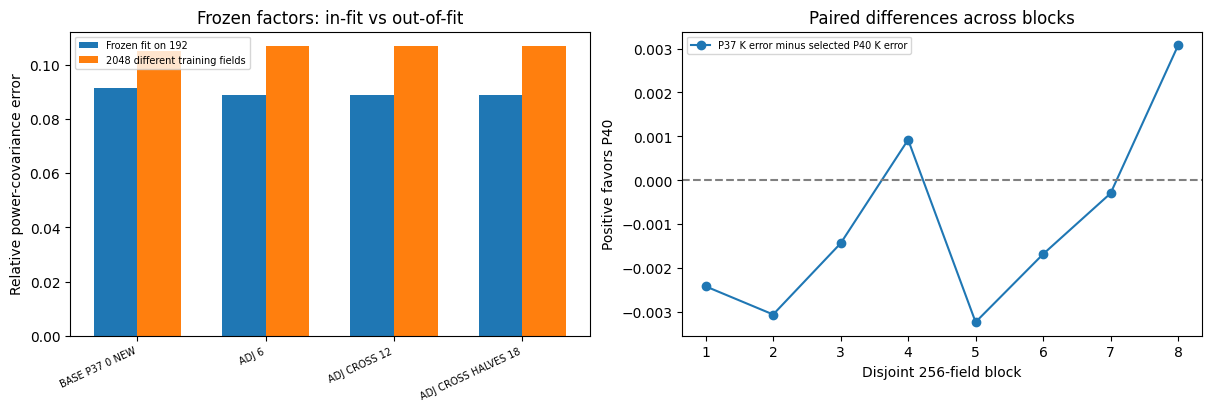

P41 report: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p41_frozen_factor_unused_training_audit_20261103T001904Z_dd1616/result.json
P41 figure: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p41_frozen_factor_unused_training_audit_20261103T001904Z_dd1616/p41_new_training_block_comparison.png
P41 ledger: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p41_frozen_factor_unused_training_audit_20261103T001904Z_dd1616/P41_RESEARCH_LEDGER_ADDENDUM.md
P41 provenance: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p41_frozen_factor_unused_training_audit_20261103T001904Z_dd1616/P41_PROVENANCE_NOTE.json
P41 COMPLETE — no fitting, no seed-1 test read, no previous research evidence changed.


In [28]:

# CELL P41 — Frozen factors on additional original training fields
# Place BELOW completed P40. Run P41 ONLY.
# No retraining, seed-1 test access, or historical overwrites.

from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, subprocess, uuid
import numpy as np
import h5py
import matplotlib.pyplot as plt

ROOT41 = Path(
    '/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1'
)
REPO41 = Path('/content/nasa_clfm_reference')
DATA41 = Path(
    '/content/clfm_snapshot/data/wind/wind_train_data.hdf5'
)
PIN41 = '921e666c8d6060ae13bfd901dcc7f74f819d0eea'
DATA_SHA41 = (
    '676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'
)

PRIOR41 = {
    'P25': ROOT41 / (
        'fidelity_diagnostics/'
        'p25_reusable_generator_20261030T131833Z_6e7149/result.json'
    ),
    'P32': ROOT41 / (
        'fidelity_diagnostics/'
        'p32_source_phase_audit_20261102T162342Z_ac5eae/result.json'
    ),
    'P37': ROOT41 / (
        'fidelity_diagnostics/'
        'p37_analytic_fourth_order_20261102T191024Z_928bf7/result.json'
    ),
    'P38': ROOT41 / (
        'fidelity_diagnostics/'
        'p38_oracle_covariance_family_limit_20261102T191531Z_80f8b4/result.json'
    ),
    'P40': ROOT41 / (
        'fidelity_diagnostics/'
        'p40_structured_overcomplete_rotations_20261102T201630Z_5ee4f1/result.json'
    ),
}

def sha41(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(
            lambda: f.read(8 * 1024 * 1024), b''
        ):
            h.update(block)
    return h.hexdigest()

def rel41(a, b):
    return float(
        np.linalg.norm(a-b) /
        max(np.linalg.norm(b), 1e-300)
    )

def cv41(a):
    a = np.asarray(a, dtype=np.float64)
    return float(a.std(ddof=1) / a.mean())

def pcov41(x):
    p = np.abs(x)**2
    d = p - p.mean(axis=0, keepdims=True)
    return np.einsum(
        'nki,nkj->kij',
        d, d, optimize=True
    ) / (len(x)-1)

def kmoment41(a, c):
    a = np.asarray(a)
    c = np.asarray(c)

    assert a.ndim == 2, f"Expected 2D factor, got {a.shape}"
    assert c.shape == (a.shape[0], a.shape[0])

    p = np.abs(a)**2

    K = np.abs(c)**2 - p @ p.T

    assert np.isfinite(K).all()

    return K.real

# -------------------------------------------------------
# 1. Verify pinned inputs and saved research reports.
# -------------------------------------------------------

assert ROOT41.is_dir()
assert DATA41.is_file()
assert (REPO41 / '.git').is_dir()

assert all(
    p.is_file() for p in PRIOR41.values()
), 'Missing research report. Do not rerun old experiments.'

assert sha41(DATA41) == DATA_SHA41

actual_pin = subprocess.check_output(
    ['git', '-C', str(REPO41), 'rev-parse', 'HEAD'],
    text=True
).strip()

assert actual_pin == PIN41

OLD_SHA41 = {
    name: sha41(path)
    for name, path in PRIOR41.items()
}

REP41 = {
    name: json.loads(path.read_text())
    for name, path in PRIOR41.items()
}

assert all(
    report['status'] == 'completed'
    for report in REP41.values()
)

assert REP41['P37']['fit_n'] == 192
assert REP41['P37']['internal_validation_n'] == 64

assert (
    REP41['P40']['training_selected_model']
    == 'ADJ_CROSS_HALVES_18'
)

for rel, expected in (
    REP41['P32']['pinned_source_sha256'].items()
):
    assert sha41(REPO41 / rel) == expected

# -------------------------------------------------------
# 2. Load FROZEN P40 factors. No parameter updates.
# -------------------------------------------------------

MODEL_PATH41 = Path(
    REP41['P40']['model_package_path']
)

assert MODEL_PATH41.is_file()

MODEL_SHA41 = sha41(MODEL_PATH41)

assert MODEL_SHA41 == (
    REP41['P40']['model_package_sha256']
)

model_keys41 = {
    'BASE_P37_0_NEW': 'p37_paired_base',
    'ADJ_6': 'adj_6',
    'ADJ_CROSS_12': 'adj_cross_12',
    'ADJ_CROSS_HALVES_18': 'adj_cross_halves_18',
}

with np.load(
    MODEL_PATH41, allow_pickle=False
) as package:

    Cfit41 = np.asarray(
        package['fitted_C'],
        dtype=np.complex128
    )

    factors41 = {
        name: np.asarray(
            package[key],
            dtype=np.complex128
        )
        for name, key in model_keys41.items()
    }

    prior_fit_ids41 = np.asarray(
        package['fit_training_indices'],
        dtype=np.int64
    )

    prior_internal_ids41 = np.asarray(
        package['reused_internal_indices'],
        dtype=np.int64
    )

assert Cfit41.shape == (6, 40, 40)

assert all(
    a.shape == (6, 40, 80)
    for a in factors41.values()
)

assert np.array_equal(
    prior_fit_ids41,
    REP41['P37']['fit_indices']
)

assert np.array_equal(
    prior_internal_ids41,
    REP41['P37']['internal_validation_indices']
)

p25_ids41 = np.asarray(
    REP41['P25']['training_indices'], dtype=int
)

assert len(p25_ids41) == 256
assert len(np.unique(p25_ids41)) == 256

assert np.array_equal(
    np.sort(np.r_[
        prior_fit_ids41, prior_internal_ids41
    ]),
    np.sort(p25_ids41)
)

for name, A in factors41.items():

    covariance = (
        A @ A.conj().transpose(0, 2, 1)
    )

    assert np.allclose(
        covariance, Cfit41,
        rtol=1e-10, atol=1e-8
    ), name

Kmodel41 = {
    name: np.stack([
        kmoment41(A[k], Cfit41[k])
        for k in range(6)
    ])
    for name, A in factors41.items()
}

# -------------------------------------------------------
# 3. Reconstruct source analytical K for diagnostics.
#    No candidate fitting uses this information.
# -------------------------------------------------------

with h5py.File(DATA41, 'r') as h5:

    assert len(h5['wind_samples']) == 5000

    xyz41 = np.asarray(
        h5['x_grid'], dtype=float
    )

    fgrid41 = np.asarray(
        h5['input_parameters/freq_grid'],
        dtype=float
    )

    shear41 = float(np.asarray(
        h5['input_parameters/shear_velocity']
    ))

assert xyz41.shape == (100, 3)
assert fgrid41.shape == (128,)

assert np.allclose(
    fgrid41, np.linspace(3/128, 3, 128)
)

assert np.isclose(shear41, 1.9)

z41 = xyz41[:, 2]

mu41 = 2.5 * shear41 * np.log(z41 / .015)

variance41 = (
    6. - 1.1 * np.arctan(
        np.log(.015) + 1.75
    )
) * shear41**2

length41 = (
    300 * (z41/200)**(
        .67 + .05*np.log(shear41)
    )
)

dist41 = np.linalg.norm(
    (
        xyz41[:, None, :] -
        xyz41[None, :, :]
    ) * [3., 3., .5],
    axis=-1
)

Bsrc41 = np.empty(
    (6, 40, 100), dtype=np.float64
)

sel41 = np.r_[
    0:10, 30:40, 60:70, 90:100
]

for ki, k in enumerate(range(1, 7)):

    f = fgrid41[k]

    # Preserve the literal pinned NASA-source behavior.
    auto = (
        variance41 * 6.868 * f *
        (length41 / mu41)
    ) / (
        f * (
            1 + 1.5*f*6.868*length41/mu41
        )**5 / 3
    )

    coh = np.exp(
        -f*dist41 /
        (mu41[:, None] + mu41[None, :])
    )

    S = (
        np.sqrt(
            auto[:, None] * auto[None, :]
        ) * coh
    )

    U, s, _ = np.linalg.svd(
        S, full_matrices=False
    )

    Bsrc41[ki] = (
        U * np.sqrt(s)[None, :]
    )[sel41]

Bsrc41 *= (
    128 *
    np.sqrt(4*(fgrid41[1]-fgrid41[0])) /
    49.
)

Csrc41 = (
    Bsrc41 @
    Bsrc41.transpose(0, 2, 1)
)

Ksrc41 = np.stack([
    kmoment41(Bsrc41[k], Csrc41[k])
    for k in range(6)
])

assert abs(
    rel41(Cfit41, Csrc41) -
    REP41['P40'][
        'fitted_CSD_error_vs_oracle_source'
    ]
) < 1e-8

for row in REP41['P40']['comparison_rows']:

    assert abs(
        rel41(
            Kmodel41[row['model']],
            Ksrc41
        ) -
        row['source_population_K_error']
    ) < 1e-8

# -------------------------------------------------------
# 4. Select 2048 different records from the same
#    ORIGINAL seed-0 training HDF5.
#
#    All 256 P25 records are excluded.
#    No prospective test dataset is accessed.
# -------------------------------------------------------

N41 = 2048
BLOCK41 = 256
seed41 = 410001

complement41 = np.setdiff1d(
    np.arange(5000),
    p25_ids41,
    assume_unique=True
)

assert len(complement41) == 4744

rng41 = np.random.default_rng(seed41)

ids41 = rng41.choice(
    complement41,
    size=N41,
    replace=False
).reshape(
    N41 // BLOCK41,
    BLOCK41
)

assert len(np.unique(ids41)) == N41

assert not np.intersect1d(
    ids41, p25_ids41
).size

# -------------------------------------------------------
# 5. Streaming evaluation: 8 blocks of 256.
#    Never store 2048 complete fields simultaneously.
# -------------------------------------------------------

sum_p41 = np.zeros(
    (6, 40), dtype=np.float64
)

sum_pp41 = np.zeros(
    (6, 40, 40), dtype=np.float64
)

sum_cc41 = np.zeros(
    (6, 40, 40), dtype=np.complex128
)

energy_blocks41 = []
panel_rows41 = []

print(
    'P41 — Evaluating 8 disjoint blocks '
    'from the existing TRAIN HDF5.'
)

with h5py.File(DATA41, 'r') as h5:

    for bi, block_ids in enumerate(ids41):

        raw = np.stack([
            np.asarray(
                h5['wind_samples'][
                    str(int(idx))
                ]['v1'],
                dtype=np.float64
            )[sel41]

            for idx in block_ids
        ])

        assert raw.shape == (
            BLOCK41, 40, 256
        )

        assert np.isfinite(raw).all()

        x = np.fft.rfft(
            raw - raw.mean(
                axis=-1, keepdims=True
            ),
            axis=-1
        )[:, :, 1:7].transpose(
            0, 2, 1
        ) / 49.

        assert x.shape == (
            BLOCK41, 6, 40
        )

        power = np.abs(x)**2

        sum_p41 += power.sum(axis=0)

        sum_pp41 += np.einsum(
            'nki,nkj->kij',
            power, power,
            optimize=True
        )

        sum_cc41 += np.einsum(
            'nki,nkj->kij',
            x, x.conj(),
            optimize=True
        )

        energies = power.mean(
            axis=(1, 2)
        )

        energy_blocks41.append(energies)

        Kpanel = pcov41(x)

        panel = {
            'panel': int(bi+1),
            'n': BLOCK41,
            'source_noise_K':
                rel41(Kpanel, Ksrc41),
            'field_energy_CV':
                cv41(energies)
        }

        for name, km in Kmodel41.items():

            panel[name + '_K_error'] = (
                rel41(km, Kpanel)
            )

        panel_rows41.append(panel)

        print(
            f"Block {bi+1}/8: "
            f"source K sampling error="
            f"{panel['source_noise_K']:.5f}; "
            f"energy CV="
            f"{panel['field_energy_CV']:.5f}"
        )

        del raw, x, power

# -------------------------------------------------------
# 6. Calculate pooled 2048-field covariance correctly.
#    Includes between-block mean effects.
# -------------------------------------------------------

mean_p41 = sum_p41 / N41

Kunused41 = (
    sum_pp41 -
    N41*np.einsum(
        'ki,kj->kij',
        mean_p41, mean_p41
    )
) / (N41-1)

Kunused41 = (
    Kunused41 +
    Kunused41.transpose(0, 2, 1)
) / 2

Cunused41 = sum_cc41 / N41

Cunused41 = (
    Cunused41 +
    Cunused41.conj().transpose(0, 2, 1)
) / 2

energy41 = np.concatenate(
    energy_blocks41
)

assert energy41.shape == (N41,)

assert np.isfinite(Kunused41).all()
assert np.isfinite(Cunused41).all()
assert np.isfinite(energy41).all()

# -------------------------------------------------------
# 7. Compare all previously frozen candidate factors.
# -------------------------------------------------------

rows41 = []

for row in REP41['P40']['comparison_rows']:

    name = row['model']
    km = Kmodel41[name]

    panel_errors = np.asarray([
        r[name+'_K_error']
        for r in panel_rows41
    ])

    rows41.append({
        'model': name,

        'new_parameters':
            row['new_parameter_count'],

        'frozen_training_K_error':
            row['training_K_error'],

        'frozen_reused64_K_error':
            row['reused_64_K_error'],

        'frozen_source_K_error':
            row['source_population_K_error'],

        'unused2048_K_error':
            rel41(km, Kunused41),

        'unused256_panel_mean_K_error':
            float(panel_errors.mean()),

        'unused256_panel_minmax_K_error': [
            float(panel_errors.min()),
            float(panel_errors.max())
        ],

        'analytic_field_energy_CV':
            row['energy_CV_analytic']
    })

base41 = next(
    r for r in rows41
    if r['model'] == 'BASE_P37_0_NEW'
)

selected41 = next(
    r for r in rows41
    if r['model'] == (
        REP41['P40']['training_selected_model']
    )
)

pool_improvement41 = (
    base41['unused2048_K_error'] -
    selected41['unused2048_K_error']
)

paired_panel_delta41 = np.asarray([
    r['BASE_P37_0_NEW_K_error'] -
    r['ADJ_CROSS_HALVES_18_K_error']

    for r in panel_rows41
])

# -------------------------------------------------------
# 8. Print results BEFORE creating artifacts.
# -------------------------------------------------------

print('\n' + '='*94)
print(
    'P41 — FROZEN P40 FACTORS ON '
    '2048 DIFFERENT TRAINING RECORDS'
)
print('='*94)

print(
    'Selected n:', N41,
    '| seed:', seed41,
    '| overlap with P25:',
    np.intersect1d(
        ids41, p25_ids41
    ).size
)

print(
    'Pooled empirical CSD error vs source:',
    rel41(Cunused41, Csrc41)
)

print(
    'Pooled empirical K error vs source:',
    rel41(Kunused41, Ksrc41)
)

print(
    'Pooled observed energy CV:',
    cv41(energy41)
)

print(
    'Source analytical energy CV:',
    REP41['P37']['source_analytic_CV']
)

for r in rows41:

    print(
        f"{r['model']:23s} "
        f"params={r['new_parameters']:2d} "
        f"trainK={r['frozen_training_K_error']:.6f} "
        f"new2048K={r['unused2048_K_error']:.6f} "
        f"sourceK={r['frozen_source_K_error']:.6f} "
        f"CV={r['analytic_field_energy_CV']:.6f}"
    )

print(
    'P40-selected vs P37 pooled improvement '
    '(positive favors P40):',
    pool_improvement41
)

print(
    'Eight paired panel improvements:',
    np.round(
        paired_panel_delta41, 6
    ).tolist()
)

print(
    'Positive panels out of eight:',
    int(np.sum(
        paired_panel_delta41 > 0
    ))
)

# -------------------------------------------------------
# 9. Save only NEW scoped P41 artifacts.
# -------------------------------------------------------

assert sha41(DATA41) == DATA_SHA41
assert sha41(MODEL_PATH41) == MODEL_SHA41

assert all(
    sha41(PRIOR41[k]) == digest
    for k, digest in OLD_SHA41.items()
)

RUN41 = ROOT41/'fidelity_diagnostics'/(
    'p41_frozen_factor_unused_training_audit_'
    + datetime.now(timezone.utc).strftime(
        '%Y%m%dT%H%M%SZ'
    )
    + '_' + uuid.uuid4().hex[:6]
)

assert RUN41.parent.resolve() == (
    ROOT41 / 'fidelity_diagnostics'
).resolve()

RUN41.mkdir(
    parents=True, exist_ok=False
)

REPORT41 = RUN41/'result.json'
FIG41 = RUN41/'p41_new_training_block_comparison.png'
LEDGER41 = RUN41/'P41_RESEARCH_LEDGER_ADDENDUM.md'
PROV41 = RUN41/'P41_PROVENANCE_NOTE.json'

result41 = {
    'experiment':
        'P41_frozen_factors_nonoverlapping_seed0_training_examples',

    'status': 'completed',

    'created_utc':
        datetime.now(timezone.utc).isoformat(),

    'pinned_source_commit': PIN41,
    'trusted_train_sha256': DATA_SHA41,

    'prior_report_sha256': OLD_SHA41,
    'P40_frozen_model_sha256': MODEL_SHA41,

    'selection_protocol': {
        'seed': seed41,
        'n': N41,
        'block_size': BLOCK41,

        'excluded_all_256_P25_indices': True,

        'selected_original_training_indices':
            ids41.reshape(-1).tolist()
    },

    'no_fitting_or_model_reselection': True,

    'pooled_unused_C_error_vs_source':
        rel41(Cunused41, Csrc41),

    'pooled_unused_K_error_vs_source':
        rel41(Kunused41, Ksrc41),

    'pooled_unused_energy_CV':
        cv41(energy41),

    'source_theoretical_energy_CV':
        REP41['P37']['source_analytic_CV'],

    'frozen_model_comparisons': rows41,
    'block_results': panel_rows41,

    'training_selected_model':
        REP41['P40']['training_selected_model'],

    'selected_vs_baseline_pooled_K_improvement':
        pool_improvement41,

    'paired_panel_K_improvements':
        paired_panel_delta41.tolist(),

    'limitations': [
        '2048 records are from original seed-0 TRAIN HDF5, not seed-1 test data.',
        'These records are new to P37/P40 factor fitting, but earlier project models may have used them.',
        'Previous source analyses already informed development; this is not blind confirmation.',
        'Candidates frozen before these records were read; no refitting or parameter tuning.',
        'Eight disjoint panels characterize sampling fluctuations, not confirmatory significance.',
        'Only six Fourier bins and 40 sparse sensors are evaluated.',
        'Known source K is an oracle diagnostic, not a fitting target.',
        'No seed-1 access, new physical regime, old artifact mutation, or November 3 presentation change.'
    ]
}

REPORT41.write_text(
    json.dumps(
        result41,
        indent=2,
        allow_nan=False
    ),
    encoding='utf-8'
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 4),
    constrained_layout=True
)

xx = np.arange(len(rows41))

labels = [
    r['model'].replace('_', ' ')
    for r in rows41
]

axes[0].bar(
    xx-.17,
    [
        r['frozen_training_K_error']
        for r in rows41
    ],
    .34,
    label='Frozen fit on 192'
)

axes[0].bar(
    xx+.17,
    [
        r['unused2048_K_error']
        for r in rows41
    ],
    .34,
    label='2048 different training fields'
)

axes[0].set_xticks(
    xx, labels,
    rotation=25,
    ha='right',
    fontsize=7
)

axes[0].set(
    ylabel='Relative power-covariance error',
    title='Frozen factors: in-fit vs out-of-fit'
)

axes[0].legend(fontsize=7)

axes[1].plot(
    np.arange(1, 9),
    paired_panel_delta41,
    'o-',
    label='P37 K error minus selected P40 K error'
)

axes[1].axhline(
    0,
    linestyle='--',
    color='gray'
)

axes[1].set(
    xlabel='Disjoint 256-field block',
    ylabel='Positive favors P40',
    title='Paired differences across blocks'
)

axes[1].legend(fontsize=7)

fig.savefig(FIG41, dpi=150)
plt.show()
plt.close(fig)

LEDGER41.write_text(
    '# P41 — Frozen P40 factor robustness check\n\n'
    '- Evaluation only: 2048 deterministic training-HDF5 indices outside the P25 256.\n'
    '- Eight disjoint blocks of 256 fields.\n'
    '- Compare the frozen P37 baseline and three P40 rotation models.\n'
    '- Do not use these results to claim untouched test generalization or reselect models.\n'
    '- Source analytical K is diagnostic only.\n'
    '- No test seed 1, retraining, historical overwrites, or November 3 changes.\n',
    encoding='utf-8'
)

ART41 = {
    p.name: sha41(p)
    for p in (
        REPORT41, FIG41, LEDGER41
    )
}

with PROV41.open(
    'x', encoding='utf-8'
) as f:

    json.dump({
        'scope': 'NEW_P41_FOLDER_ONLY',
        'artifact_sha256': ART41,
        'prior_report_sha256': OLD_SHA41,
        'P40_model_sha256': MODEL_SHA41,
        'historical_vault_not_scanned': True
    }, f, indent=2)

assert all(
    sha41(RUN41/name) == digest
    for name, digest in ART41.items()
)

assert all(
    sha41(PRIOR41[k]) == digest
    for k, digest in OLD_SHA41.items()
)

assert sha41(MODEL_PATH41) == MODEL_SHA41

print('P41 report:', REPORT41)
print('P41 figure:', FIG41)
print('P41 ledger:', LEDGER41)
print('P41 provenance:', PROV41)

print(
    'P41 COMPLETE — no fitting, no seed-1 test read, '
    'no previous research evidence changed.'
)


P42 n= 192 paired train/eval K=0.11881/0.12790; rotated train/eval K=0.11561/0.12736
P42 n= 384 paired train/eval K=0.11831/0.11200; rotated train/eval K=0.11651/0.11116
P42 n= 768 paired train/eval K=0.10363/0.10347; rotated train/eval K=0.10314/0.10321
P42 n=1536 paired train/eval K=0.09828/0.10423; rotated train/eval K=0.09753/0.10369

P42 — DATA SCALING / FROZEN ROTATION AUDIT
Excluded P25: 256 | excluded P41: 2048
New fitting fields: 1536 | development evaluation: 1160
Evaluation source C error: 0.014026225413109451 K sampling error: 0.04594402659347756
Evaluation observed CV: 0.04501364490686556 | source theoretical CV: 0.04650441658135235
n= 192 PAIRED_CV    trainK=0.118810 evalK=0.127902 Cerror=0.03454 CV=0.047352
n= 192 ROTATED_18   trainK=0.115611 evalK=0.127363 Cerror=0.03454 CV=0.052307
n= 384 PAIRED_CV    trainK=0.118312 evalK=0.112003 Cerror=0.02727 CV=0.047932
n= 384 ROTATED_18   trainK=0.116513 evalK=0.111159 Cerror=0.02727 CV=0.050117
n= 768 PAIRED_CV    trainK=0.10362

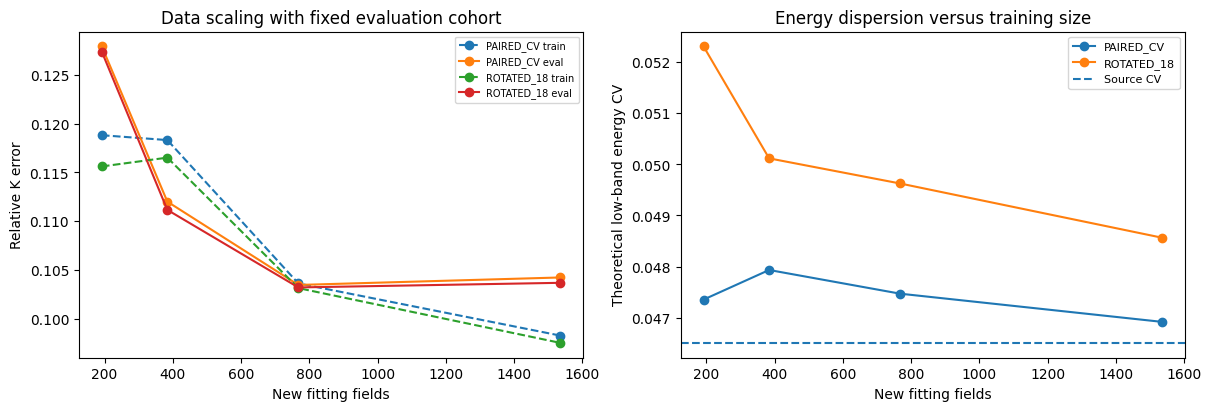

Report: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p42_data_scaling_frozen_factor_20261103T002659Z_2be516/result.json
Model: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p42_data_scaling_frozen_factor_20261103T002659Z_2be516/factors_n1536.npz
Figure: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p42_data_scaling_frozen_factor_20261103T002659Z_2be516/training_size_vs_K_error.png
Ledger: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p42_data_scaling_frozen_factor_20261103T002659Z_2be516/P42_RESEARCH_LEDGER_ADDENDUM.md
Provenance: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p42_data_scaling_frozen_factor_20261103T002659Z_2be516/P42_PROVENANCE_NOTE.json
P42 COMPLETE — no P1-P41 reruns, no prospective test, no historical modifications.


In [29]:

# P42 — Data-scaling audit of source-blind spectral factors
# Run ONLY this cell, directly BELOW completed P41.
# No P1-P41 reruns, no test seed 1, no historical modifications.

from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, subprocess, uuid
import numpy as np
import h5py
import matplotlib.pyplot as plt
from scipy.optimize import minimize

ROOT42 = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
REPO42 = Path('/content/nasa_clfm_reference')
HDF42 = Path('/content/clfm_snapshot/data/wind/wind_train_data.hdf5')
PIN42 = '921e666c8d6060ae13bfd901dcc7f74f819d0eea'
HDF_SHA42 = '676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'

FILES42 = {
 'P25':ROOT42/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149/result.json',
 'P32':ROOT42/'fidelity_diagnostics/p32_source_phase_audit_20261102T162342Z_ac5eae/result.json',
 'P37':ROOT42/'fidelity_diagnostics/p37_analytic_fourth_order_20261102T191024Z_928bf7/result.json',
 'P40':ROOT42/'fidelity_diagnostics/p40_structured_overcomplete_rotations_20261102T201630Z_5ee4f1/result.json',
 'P41':ROOT42/'fidelity_diagnostics/p41_frozen_factor_unused_training_audit_20261103T001904Z_dd1616/result.json',
}

def sha42(p):
 h=hashlib.sha256()
 with Path(p).open('rb') as f:
  for b in iter(lambda:f.read(8*1024*1024),b''):
   h.update(b)
 return h.hexdigest()

def rel42(a,b):
 return float(np.linalg.norm(a-b)/max(np.linalg.norm(b),1e-300))

def cv42(x):
 return float(np.std(x,ddof=1)/np.mean(x))

def csd42(x):
 return np.einsum('nki,nkj->kij',x,x.conj(),optimize=True)/len(x)

def pcov42(x):
 p=np.abs(x)**2
 d=p-p.mean(axis=0,keepdims=True)
 return np.einsum('nki,nkj->kij',d,d,optimize=True)/(len(x)-1)

def kmom42(A,C):
 p=np.abs(A)**2
 return (np.abs(C)**2-
         np.einsum('kia,kja->kij',p,p,optimize=True)).real

def energy_cv_theory42(K,C):
 return float(
  np.sqrt(max(0.,float(K.sum())))/
  np.trace(C,axis1=1,axis2=2).real.sum()
 )

# 1. Verify existing source and evidence.
assert ROOT42.is_dir() and HDF42.is_file() and (REPO42/'.git').is_dir(), (
 'Restore temporary pinned inputs using clean notebook Cell 5b only.'
)
assert all(p.is_file() for p in FILES42.values())
assert sha42(HDF42)==HDF_SHA42
assert subprocess.check_output(
 ['git','-C',str(REPO42),'rev-parse','HEAD'],
 text=True
).strip()==PIN42

HASHES42={k:sha42(p) for k,p in FILES42.items()}
OLD42={k:json.loads(p.read_text()) for k,p in FILES42.items()}

assert all(v['status']=='completed' for v in OLD42.values())
assert OLD42['P37']['fit_n']==192
assert OLD42['P40']['training_selected_model']=='ADJ_CROSS_HALVES_18'
assert OLD42['P41']['selection_protocol']['n']==2048

for path,digest in OLD42['P32']['pinned_source_sha256'].items():
 assert sha42(REPO42/path)==digest

P40_PATH42=Path(OLD42['P40']['model_package_path'])
assert P40_PATH42.is_file()
assert sha42(P40_PATH42)==OLD42['P40']['model_package_sha256']
P40_SHA42=sha42(P40_PATH42)

with np.load(P40_PATH42,allow_pickle=False) as frozen42:
 C_old42=np.array(frozen42['fitted_C'],copy=True)
 A_oldbase42=np.array(frozen42['p37_paired_base'],copy=True)
 A_old18_42=np.array(frozen42['adj_cross_halves_18'],copy=True)

assert C_old42.shape==(6,40,40)
assert A_oldbase42.shape==A_old18_42.shape==(6,40,80)

# 2. Exclude both prior P25 and P41 cohorts.
ids25_42=np.asarray(OLD42['P25']['training_indices'],dtype=int)
ids41_42=np.asarray(
 OLD42['P41']['selection_protocol']['selected_original_training_indices'],
 dtype=int
)

assert ids25_42.shape==(256,)
assert ids41_42.shape==(2048,)
assert len(np.unique(ids25_42))==256
assert len(np.unique(ids41_42))==2048
assert np.intersect1d(ids25_42,ids41_42).size==0

remaining42=np.setdiff1d(
 np.arange(5000),np.r_[ids25_42,ids41_42]
)
assert len(remaining42)==2696

rng42=np.random.default_rng(420001)
perm42=rng42.permutation(remaining42)

fit_ids42=perm42[:1536]
eval_ids42=perm42[1536:]

assert len(eval_ids42)==1160
assert np.intersect1d(fit_ids42,eval_ids42).size==0

SIZES42=(192,384,768,1536)
sel42=np.r_[0:10,30:40,60:70,90:100]

# 3. Load only the newly assigned seed-0 training records.
with h5py.File(HDF42,'r') as h5:
 assert len(h5['wind_samples'])==5000
 xyz42=np.asarray(h5['x_grid'],dtype=float)
 freq42=np.asarray(h5['input_parameters/freq_grid'],dtype=float)
 shear42=float(np.asarray(
  h5['input_parameters/shear_velocity']
 ))
 xraw42=np.stack([
  np.asarray(
   h5['wind_samples'][str(int(i))]['v1'],dtype=float
  )[sel42]
  for i in np.r_[fit_ids42,eval_ids42]
 ])

assert xraw42.shape==(2696,40,256)
assert np.isfinite(xraw42).all()
assert xyz42.shape==(100,3)
assert np.allclose(freq42,np.linspace(3/128,3,128))
assert abs(shear42-1.9)<1e-12

Fx42=np.fft.rfft(
 xraw42-xraw42.mean(axis=-1,keepdims=True),
 axis=-1
)[:,:,1:7].transpose(0,2,1)/49.

allfit42=Fx42[:1536]
evaluation42=Fx42[1536:]
del xraw42,Fx42

K_eval42=pcov42(evaluation42)
C_eval42=csd42(evaluation42)
eval_energy42=(np.abs(evaluation42)**2).mean(axis=(1,2))

assert np.isfinite(K_eval42).all()

# 4. Reuse P40's fixed, covariance-preserving rotation architecture.
PAIR42={
 'ADJACENT':
  [(j,j+1) for j in range(0,40,2)]+
  [(40+j,41+j) for j in range(0,40,2)],
 'CROSS':
  [(j,40+39-j) for j in range(40)],
 'HALVES':
  [(j,j+20) for j in range(20)]+
  [(40+j,60+j) for j in range(20)]
}

for pair in PAIR42.values():
 assert len(pair)==40
 assert sorted(j for a,b in pair for j in (a,b))==list(range(80))

LAYERS42=('ADJACENT','CROSS','HALVES')
REG42=0.002
BOUND42=0.35

def rotate42(A,angles):
 out=A.copy()
 for ang,name in zip(angles,LAYERS42):
  c,s=np.cos(ang),np.sin(ang)
  for a,b in PAIR42[name]:
   left=out[:,a].copy()
   right=out[:,b].copy()
   out[:,a]=c*left+s*right
   out[:,b]=-s*left+c*right
 return out

# 5. Fit paired covariance and six energy angles from each training prefix.
def fit_pair42(X):
 C=csd42(X)
 C=(C+C.conj().transpose(0,2,1))/2

 L=np.empty((6,40,40),dtype=np.complex128)
 evs=np.empty((6,40),dtype=float)

 for k in range(6):
  eig,U=np.linalg.eigh(C[k])
  assert eig.min()>-1e-6
  piv=np.argmax(np.abs(U),axis=0)
  U=U*np.exp(
   -1j*np.angle(U[piv,np.arange(40)])
  )[None,:]
  eig=np.maximum(eig,0)
  L[k]=U*np.sqrt(eig)[None,:]
  evs[k]=eig

 Ktrain=pcov42(X)
 en=(np.abs(X)**2).mean(axis=2)
 binCV=np.array([cv42(en[:,k]) for k in range(6)])
 trace=np.trace(C,axis1=1,axis2=2).real

 T=np.einsum(
  'kia,kja->kij',
  np.abs(L)**2,np.abs(L)**2,optimize=True
 ).real

 beta=(binCV*trace)**2/T.sum(axis=(1,2))

 assert np.all((beta>=0)&(beta<=.5)), (
  'Paired family cannot match training CV at this size',
  beta.tolist()
 )

 angle=.5*np.arcsin(np.sqrt(2*beta))
 A=np.concatenate([
  L*np.cos(angle)[:,None,None],
  L*np.sin(angle)[:,None,None]
 ],axis=2)

 assert np.allclose(
  A@A.conj().transpose(0,2,1),C,
  atol=1e-8,rtol=1e-10
 )
 return C,Ktrain,A,beta

# 6. Fit paired and rotated candidates across nested sample sizes.
ROWS42=[]
FACTORS42={}
OPTIM42={}

for n42 in SIZES42:
 Cn,Kn,Apaired,betas=fit_pair42(allfit42[:n42])

 Arot=np.empty_like(Apaired)
 angles=np.empty((6,3))
 statuses=[]

 for k in range(6):
  initial=Apaired[k]
  target=Kn[k]
  base_norm=max(float(np.sum(target*target)),1e-300)

  def objective(v):
   test=rotate42(initial,v)
   p=np.abs(test)**2
   Km=np.abs(Cn[k])**2-p@p.T
   return float(
    np.sum((Km.real-target)**2)/base_norm+
    REG42*np.sum(v*v)
   )

  sol=minimize(
   objective,np.zeros(3),
   method='L-BFGS-B',
   bounds=[(-BOUND42,BOUND42)]*3,
   options={
    'maxiter':100,
    'ftol':1e-12,
    'gtol':1e-9
   }
  )

  assert np.isfinite(sol.fun)
  assert np.all(np.isfinite(sol.x))
  assert sol.fun<=objective(np.zeros(3))+1e-7

  Arot[k]=rotate42(initial,sol.x)
  angles[k]=sol.x

  statuses.append({
   'success':bool(sol.success),
   'iterations':int(sol.nit),
   'message':str(sol.message)
  })

 assert np.allclose(
  Arot@Arot.conj().transpose(0,2,1),Cn,
  atol=1e-8,rtol=1e-10
 )

 for label,A in (
  ('PAIRED_CV',Apaired),
  ('ROTATED_18',Arot)
 ):
  K=kmom42(A,Cn)
  ROWS42.append({
   'training_n':n42,
   'model':label,
   'train_K_error':rel42(K,Kn),
   'evaluation1160_K_error':rel42(K,K_eval42),
   'evaluation1160_CSD_error':rel42(Cn,C_eval42),
   'energy_CV_theory':energy_cv_theory42(K,Cn),
   'energy_CV_evaluation1160':cv42(eval_energy42),
   'beta_per_bin':betas.tolist(),
   'rotations_deg':(
    None if label=='PAIRED_CV'
    else np.degrees(angles).tolist()
   )
  })

 if n42==1536:
  FACTORS42={
   'fitted_C':Cn,
   'paired':Apaired,
   'rotated_18':Arot,
   'beta':betas,
   'angles':angles
  }

 OPTIM42[str(n42)]=statuses

 arow=next(
  r for r in ROWS42
  if r['training_n']==n42 and r['model']=='PAIRED_CV'
 )
 brow=next(
  r for r in ROWS42
  if r['training_n']==n42 and r['model']=='ROTATED_18'
 )

 print(
  f'P42 n={n42:4d} '
  f'paired train/eval K='
  f'{arow["train_K_error"]:.5f}/'
  f'{arow["evaluation1160_K_error"]:.5f}; '
  f'rotated train/eval K='
  f'{brow["train_K_error"]:.5f}/'
  f'{brow["evaluation1160_K_error"]:.5f}'
 )

# 7. Compare previously frozen historical models.
FROZEN42={}

for label,A in (
 ('FROZEN_P37',A_oldbase42),
 ('FROZEN_P40_18',A_old18_42)
):
 K=kmom42(A,C_old42)
 FROZEN42[label]={
  'evaluation1160_K_error':rel42(K,K_eval42),
  'energy_CV_theory':energy_cv_theory42(K,C_old42)
 }

# 8. Reconstruct source analytical control AFTER all fits.
z=xyz42[:,2]
mu=2.5*shear42*np.log(z/.015)

var=(6.-1.1*np.arctan(np.log(.015)+1.75))*shear42**2
length=300*(z/200)**(.67+.05*np.log(shear42))

dist=np.linalg.norm(
 (xyz42[:,None,:]-xyz42[None,:,:])*[3.,3.,.5],
 axis=-1
)

Bsource=np.empty((6,40,100))

for ik,k in enumerate(range(1,7)):
 f=freq42[k]

 # Exact expression from the pinned NASA code.
 auto=(
  var*6.868*f*(length/mu)
 )/(
  f*(1+1.5*f*6.868*length/mu)**5/3
 )

 coh=np.exp(
  -f*dist/(mu[:,None]+mu[None,:])
 )

 S=np.sqrt(auto[:,None]*auto[None,:])*coh
 U,s,_=np.linalg.svd(S,full_matrices=False)

 Bsource[ik]=(U*np.sqrt(s)[None,:])[sel42]

Bsource*=128*np.sqrt(4*(freq42[1]-freq42[0]))/49

Csource=Bsource@Bsource.transpose(0,2,1)
Ksource=kmom42(Bsource,Csource)

# Post-fit source assessment for n=1536 candidates only.
for label,A in (
 ('PAIRED_CV',FACTORS42['paired']),
 ('ROTATED_18',FACTORS42['rotated_18'])
):
 K=kmom42(A,FACTORS42['fitted_C'])
 FACTORS42[label+'_source_K_error']=rel42(K,Ksource)

noise42=rel42(K_eval42,Ksource)

# 9. Print before writing evidence.
print('\n'+'='*92)
print('P42 — DATA SCALING / FROZEN ROTATION AUDIT')
print('='*92)

print(
 'Excluded P25:',len(ids25_42),
 '| excluded P41:',len(ids41_42)
)

print(
 'New fitting fields:',len(fit_ids42),
 '| development evaluation:',len(eval_ids42)
)

print(
 'Evaluation source C error:',
 rel42(C_eval42,Csource),
 'K sampling error:',noise42
)

print(
 'Evaluation observed CV:',cv42(eval_energy42),
 '| source theoretical CV:',
 energy_cv_theory42(Ksource,Csource)
)

for r in ROWS42:
 print(
  f'n={r["training_n"]:4d} {r["model"]:12s} '
  f'trainK={r["train_K_error"]:.6f} '
  f'evalK={r["evaluation1160_K_error"]:.6f} '
  f'Cerror={r["evaluation1160_CSD_error"]:.5f} '
  f'CV={r["energy_CV_theory"]:.6f}'
 )

print(
 'Frozen historical candidate evaluation:',
 FROZEN42
)

print(
 'n1536 source K error paired/rotated:',
 FACTORS42['PAIRED_CV_source_K_error'],
 FACTORS42['ROTATED_18_source_K_error']
)

# 10. New unique evidence folder, never overwrite old results.
assert sha42(HDF42)==HDF_SHA42
assert sha42(P40_PATH42)==P40_SHA42
assert all(
 sha42(FILES42[k])==v for k,v in HASHES42.items()
)

RUN42=ROOT42/'fidelity_diagnostics'/(
 'p42_data_scaling_frozen_factor_'
 +datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
 +'_'+uuid.uuid4().hex[:6]
)

assert RUN42.parent.resolve()==(
 ROOT42/'fidelity_diagnostics'
).resolve()

RUN42.mkdir(parents=True,exist_ok=False)

REPORT42=RUN42/'result.json'
MODEL42=RUN42/'factors_n1536.npz'
FIG42=RUN42/'training_size_vs_K_error.png'
LEDGER42=RUN42/'P42_RESEARCH_LEDGER_ADDENDUM.md'
PROV42=RUN42/'P42_PROVENANCE_NOTE.json'

np.savez_compressed(
 MODEL42,
 fit_indices=fit_ids42,
 evaluation_indices=eval_ids42,
 sensor_indices=sel42,
 frequency_bins=np.arange(1,7),
 fitted_C=FACTORS42['fitted_C'],
 paired_factor=FACTORS42['paired'],
 rotated_factor=FACTORS42['rotated_18'],
 beta=FACTORS42['beta'],
 angles=FACTORS42['angles']
)

with np.load(MODEL42,allow_pickle=False) as chk:
 for key in ('paired_factor','rotated_factor'):
  A=chk[key]
  assert np.allclose(
   A@A.conj().transpose(0,2,1),
   chk['fitted_C'],
   atol=1e-8,rtol=1e-10
  )

RESULT42={
 'experiment':'P42_data_scaling_of_source_blind_80phase_rotation',
 'status':'completed',
 'created_utc':datetime.now(timezone.utc).isoformat(),
 'pinned_commit':PIN42,
 'training_hdf5_sha256':HDF_SHA42,
 'prior_reports_sha256':HASHES42,
 'prior_P40_model_sha256':P40_SHA42,
 'excluded_P25_count':len(ids25_42),
 'excluded_P41_count':len(ids41_42),
 'permutation_seed':420001,
 'fit_sizes':list(SIZES42),
 'fit_indices':fit_ids42.tolist(),
 'evaluation_indices':eval_ids42.tolist(),
 'evaluation_n':len(eval_ids42),
 'model_counts':{
  'PAIRED_CV':6,
  'ROTATED_18':24
 },
 'optimization_regularization':REG42,
 'rotation_bound_radians':BOUND42,
 'optimization_status':OPTIM42,
 'development_rows':ROWS42,
 'historical_frozen_baselines':FROZEN42,
 'evaluation_source_C_error':rel42(C_eval42,Csource),
 'evaluation_source_K_error':noise42,
 'evaluation_energy_CV':cv42(eval_energy42),
 'source_theoretical_energy_CV':
  energy_cv_theory42(Ksource,Csource),
 'n1536_source_K_errors_posthoc':{
  'paired':FACTORS42['PAIRED_CV_source_K_error'],
  'rotated_18':FACTORS42['ROTATED_18_source_K_error']
 },
 'model_package_path':str(MODEL42),
 'model_package_sha256':sha42(MODEL42),
 'limitations':[
  'All 2696 records belong to the original seed-0 training HDF5.',
  'Neither P25 nor P41 indices were used in P42 fitting or evaluation.',
  'Earlier project development studied this distribution. Evaluation is developmental.',
  'Nested sample sizes mean comparisons are correlated.',
  'A single fixed partition does not quantify split variability.',
  'Six paired angles fit training CV; rotations fit training power covariance.',
  'Rotated model has six paired angles plus 18 additional angles.',
  'NASA source K used after fitting for retrospective assessment only.',
  'Models cover 40 sensors and six Fourier bins, not complete trajectories.',
  'No seed-1 test dataset or November 3 presentation modifications.'
 ]
}

REPORT42.write_text(
 json.dumps(RESULT42,indent=2,allow_nan=False),
 encoding='utf-8'
)

fig,axs=plt.subplots(
 1,2,figsize=(12,4),constrained_layout=True
)

for label in ('PAIRED_CV','ROTATED_18'):
 rows=[r for r in ROWS42 if r['model']==label]

 axs[0].plot(
  [r['training_n'] for r in rows],
  [r['train_K_error'] for r in rows],
  'o--',label=label+' train'
 )

 axs[0].plot(
  [r['training_n'] for r in rows],
  [r['evaluation1160_K_error'] for r in rows],
  'o-',label=label+' eval'
 )

 axs[1].plot(
  [r['training_n'] for r in rows],
  [r['energy_CV_theory'] for r in rows],
  'o-',label=label
 )

axs[0].set(
 xlabel='New fitting fields',
 ylabel='Relative K error',
 title='Data scaling with fixed evaluation cohort'
)
axs[0].legend(fontsize=7)

axs[1].axhline(
 energy_cv_theory42(Ksource,Csource),
 linestyle='--',
 label='Source CV'
)

axs[1].set(
 xlabel='New fitting fields',
 ylabel='Theoretical low-band energy CV',
 title='Energy dispersion versus training size'
)
axs[1].legend(fontsize=8)

fig.savefig(FIG42,dpi=150)
plt.show()
plt.close(fig)

LEDGER42.write_text(
 '# P42 — Training sample scaling for fixed phase-factor family\n\n'
 '- Original P25 and P41 records excluded before selecting new indices.\n'
 '- Remaining 2696 seed-0 training fields split into 1536 fit and 1160 development evaluation.\n'
 '- Source-blind paired and 18-rotation models refitted at four sample sizes.\n'
 '- Historical P37 and P40 models remain frozen.\n'
 '- Source analytical K used after fitting only.\n'
 '- This is not untouched test validation or a full-field generator.\n'
 '- P1-P41 and the November 3 presentation are unchanged.\n',
 encoding='utf-8'
)

ART42={
 p.name:sha42(p)
 for p in (REPORT42,MODEL42,FIG42,LEDGER42)
}

with PROV42.open('x',encoding='utf-8') as f:
 json.dump({
  'scope':'P42_NEW_FOLDER_ONLY',
  'artifacts_sha256':ART42,
  'prior_input_report_sha256':HASHES42,
  'P40_model_sha256':P40_SHA42,
  'historical_vault_not_scanned':True
 },f,indent=2)

assert all(
 sha42(RUN42/name)==digest
 for name,digest in ART42.items()
)
assert all(
 sha42(FILES42[k])==v
 for k,v in HASHES42.items()
)

print('Report:',REPORT42)
print('Model:',MODEL42)
print('Figure:',FIG42)
print('Ledger:',LEDGER42)
print('Provenance:',PROV42)

print(
 'P42 COMPLETE — no P1-P41 reruns, '
 'no prospective test, no historical modifications.'
)


P43 — EIGENMODE-ADAPTIVE PHASE SPLITTING
1536 P42 fit fields, 1160 reused development fields.
Reserved seed-1 test NOT read.
Source analytical lowband CV: 0.04650441658135235
Fitted CSD vs source: 0.011205771722599895
Training per-bin energy CV: [0.073425, 0.09835, 0.118909, 0.134676, 0.148142, 0.167871]
Scalar beta by bin: [0.006586, 0.013255, 0.021856, 0.031053, 0.041069, 0.057656]
FOUR_GROUPS accepted optimizations: 6 /6
PER_MODE accepted optimizations: 6 /6
P42_PAIRED       params=  6 trainK=0.098276 reused1160K=0.104235 sourceK=0.085343 CV=0.046916
P42_ROTATED_18   params= 24 trainK=0.097530 reused1160K=0.103687 sourceK=0.085901 CV=0.048563
FOUR_GROUPS      params= 24 trainK=0.098276 reused1160K=0.104235 sourceK=0.085343 CV=0.046916
PER_MODE         params=240 trainK=0.080086 reused1160K=0.087978 sourceK=0.065340 CV=0.046916


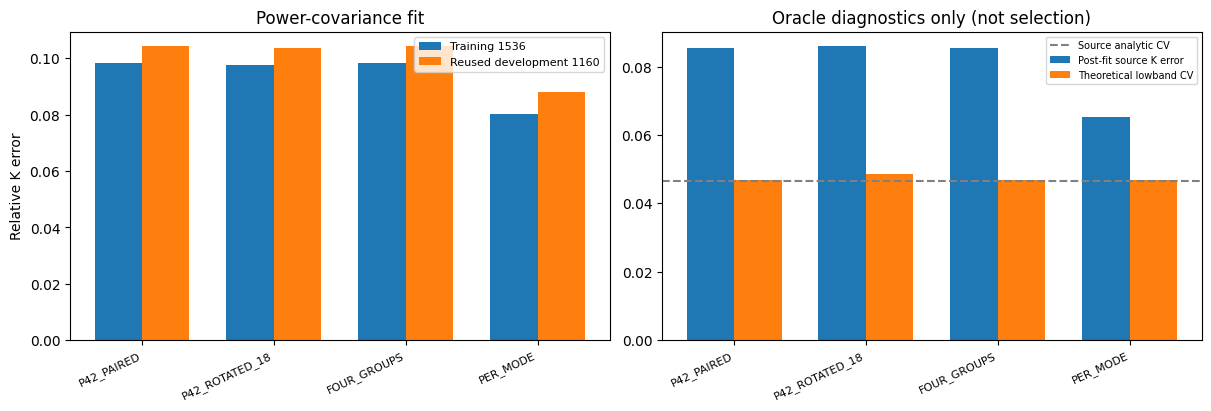

P43 report: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p43_eigenmode_phase_splitting_20261103T005500Z_e7bb27/result.json
P43 model: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p43_eigenmode_phase_splitting_20261103T005500Z_e7bb27/source_blind_mode_adaptive_factors.npz
P43 figure: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p43_eigenmode_phase_splitting_20261103T005500Z_e7bb27/mode_adaptive_comparison.png
P43 ledger: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p43_eigenmode_phase_splitting_20261103T005500Z_e7bb27/P43_RESEARCH_LEDGER_ADDENDUM.md
P43 provenance: /content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1/fidelity_diagnostics/p43_eigenmode_phase_splitting_20261103T005500Z_e7bb27/P43_PROVENANCE_NOTE.json
P43 COMPLETE — reused development only, no seed-1 read or older evidence altered.


In [30]:

# CELL P43 — Source-blind eigenmode-adaptive paired-phase model
# Paste below completed P42 in the CLEAN Colab continuation notebook.
# Run ONLY P43. No historical reruns or seed-1 test access.

from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, subprocess, uuid
import numpy as np
import h5py
import matplotlib.pyplot as plt
from scipy.optimize import minimize

ROOT43 = Path('/content/drive/MyDrive/CLFM_Research_Results/physicsnemo_day1')
REPO43 = Path('/content/nasa_clfm_reference')
HDF43 = Path('/content/clfm_snapshot/data/wind/wind_train_data.hdf5')
PIN43 = '921e666c8d6060ae13bfd901dcc7f74f819d0eea'
TRAIN_SHA43 = '676a802837ca8c7bfb52f1d312bfb800a9534bedd5427bf24f26800d25aab941'

PRIOR43 = {
    'P25': ROOT43/'fidelity_diagnostics/p25_reusable_generator_20261030T131833Z_6e7149/result.json',
    'P32': ROOT43/'fidelity_diagnostics/p32_source_phase_audit_20261102T162342Z_ac5eae/result.json',
    'P41': ROOT43/'fidelity_diagnostics/p41_frozen_factor_unused_training_audit_20261103T001904Z_dd1616/result.json',
    'P42': ROOT43/'fidelity_diagnostics/p42_data_scaling_frozen_factor_20261103T002659Z_2be516/result.json',
}

def sha43(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as f:
        for chunk in iter(lambda: f.read(8*1024*1024), b''):
            h.update(chunk)
    return h.hexdigest()

def rel43(a, b):
    return float(
        np.linalg.norm(a-b) /
        max(np.linalg.norm(b), 1e-300)
    )

def cv43(x):
    return float(np.std(x, ddof=1)/np.mean(x))

def csd43(x):
    return np.einsum(
        'nki,nkj->kij', x, x.conj(), optimize=True
    ) / len(x)

def power_cov43(x):
    p = np.abs(x)**2
    d = p-p.mean(axis=0, keepdims=True)
    return np.einsum(
        'nki,nkj->kij', d, d, optimize=True
    ) / (len(x)-1)

def kmoment43(A, C):
    p = np.abs(A)**2
    return (
        np.abs(C)**2 -
        np.einsum('kia,kja->kij', p, p, optimize=True)
    ).real

def energy_cv43(K, C):
    return float(
        np.sqrt(max(0., float(np.sum(K)))) /
        np.trace(C, axis1=1, axis2=2).real.sum()
    )

# 1 — Verify pinned inputs and previously saved evidence.

assert (
    ROOT43.is_dir()
    and HDF43.is_file()
    and (REPO43/'.git').is_dir()
), 'Restore only temporary pinned inputs using clean notebook Cell 5b.'

assert all(p.is_file() for p in PRIOR43.values())
assert sha43(HDF43) == TRAIN_SHA43

assert subprocess.check_output(
    ['git', '-C', str(REPO43), 'rev-parse', 'HEAD'],
    text=True
).strip() == PIN43

ORIGINAL_SHA43 = {
    k: sha43(p) for k, p in PRIOR43.items()
}

OLD43 = {
    k: json.loads(p.read_text())
    for k, p in PRIOR43.items()
}

assert all(rep['status'] == 'completed' for rep in OLD43.values())

assert OLD43['P42']['evaluation_n'] == 1160
assert OLD43['P42']['fit_sizes'] == [192,384,768,1536]
assert OLD43['P41']['selection_protocol']['n'] == 2048

for rel, digest in OLD43['P32']['pinned_source_sha256'].items():
    assert sha43(REPO43/rel) == digest

P42_MODEL43 = Path(OLD43['P42']['model_package_path'])

assert P42_MODEL43.is_file()
assert sha43(P42_MODEL43) == OLD43['P42']['model_package_sha256']

SHA_P42_MODEL43 = sha43(P42_MODEL43)

with np.load(P42_MODEL43, allow_pickle=False) as z:
    FIT_IDS43 = np.asarray(z['fit_indices'], dtype=int)
    EVAL_IDS43 = np.asarray(z['evaluation_indices'], dtype=int)
    Cfit43 = np.asarray(z['fitted_C'], dtype=np.complex128)
    FPAIR43 = np.asarray(z['paired_factor'], dtype=np.complex128)
    FROT43 = np.asarray(z['rotated_factor'], dtype=np.complex128)
    SEL43 = np.asarray(z['sensor_indices'], dtype=int)

assert FIT_IDS43.shape == (1536,)
assert EVAL_IDS43.shape == (1160,)

assert np.array_equal(
    FIT_IDS43,
    np.asarray(OLD43['P42']['fit_indices'], dtype=int)
)

assert np.array_equal(
    EVAL_IDS43,
    np.asarray(OLD43['P42']['evaluation_indices'], dtype=int)
)

assert np.array_equal(
    SEL43, np.r_[0:10,30:40,60:70,90:100]
)

assert np.intersect1d(FIT_IDS43,EVAL_IDS43).size == 0
assert np.unique(np.r_[FIT_IDS43,EVAL_IDS43]).size == 2696
assert Cfit43.shape == (6,40,40)
assert FPAIR43.shape == FROT43.shape == (6,40,80)

assert np.allclose(
    FPAIR43 @ FPAIR43.conj().transpose(0,2,1),
    Cfit43, atol=1e-8, rtol=1e-10
)

# 2 — Recover P42 training and reused development spectra.

with h5py.File(HDF43, 'r') as f:
    assert len(f['wind_samples']) == 5000

    COORD43 = np.asarray(f['x_grid'], dtype=float)
    FREQ43 = np.asarray(
        f['input_parameters/freq_grid'], dtype=float
    )
    SHEAR43 = float(np.asarray(
        f['input_parameters/shear_velocity']
    ))

    fields43 = np.stack([
        np.asarray(
            f['wind_samples'][str(int(i))]['v1'],
            dtype=np.float64
        )[SEL43]
        for i in np.r_[FIT_IDS43,EVAL_IDS43]
    ])

assert fields43.shape == (2696,40,256)
assert np.isfinite(fields43).all()
assert COORD43.shape == (100,3)
assert FREQ43.shape == (128,)
assert np.allclose(FREQ43,np.linspace(3/128,3,128))
assert abs(SHEAR43-1.9) < 1e-12

spec43 = np.fft.rfft(
    fields43-fields43.mean(axis=-1,keepdims=True),
    axis=-1
)[:,:,1:7].transpose(0,2,1)/49.

fit43, eval43 = spec43[:1536],spec43[1536:]
del fields43,spec43

assert rel43(csd43(fit43),Cfit43) < 1e-9

Ktrain43 = power_cov43(fit43)
Keval43 = power_cov43(eval43)

observed_cv43 = cv43(
    (np.abs(eval43)**2).mean(axis=(1,2))
)

# 3 — Construct source-blind eigenbasis and moment constraints.
#
# Each eigenmode j is split into:
# cos(theta_j)*L_j and sin(theta_j)*L_j.
#
# Define beta_j = 2*cos(theta_j)^2*sin(theta_j)^2.
#
# K = K_rank40 + sum_j beta_j * D_j.
#
# Enforce exact per-frequency TRAINING energy variance
# with eigenvalue-squared weighted beta equality.

L43 = np.empty((6,40,40),dtype=np.complex128)
EIG43 = np.empty((6,40),dtype=float)

for k in range(6):
    eig,U = np.linalg.eigh(Cfit43[k])
    assert eig.min() > -1e-6

    eig = np.maximum(eig,0.)
    piv = np.argmax(np.abs(U),axis=0)

    U = U*np.exp(
        -1j*np.angle(U[piv,np.arange(40)])
    )[None,:]

    L43[k] = U*np.sqrt(eig)[None,:]
    EIG43[k] = eig

assert np.allclose(
    L43@L43.conj().transpose(0,2,1),
    Cfit43,atol=1e-8,rtol=1e-10
)

train_cv_per_bin43 = np.array([
    cv43((np.abs(fit43[:,k,:])**2).mean(axis=1))
    for k in range(6)
])

traces43 = np.trace(
    Cfit43,axis1=1,axis2=2
).real

weights43 = EIG43**2

beta_scalar43 = (
    (train_cv_per_bin43*traces43)**2 /
    weights43.sum(axis=1)
)

assert np.all(np.isfinite(beta_scalar43))
assert np.all(
    (beta_scalar43>=0)&(beta_scalar43<=.5)
)

# Four eigenvalue groups, each containing ten sorted modes.
GROUP43 = np.repeat(np.arange(4),10)
REG43 = 1e-4

def fit_mode43(Lk,Ck,target,beta0,group_count):
    P = np.abs(Lk)**2
    D = np.einsum(
        'im,jm->ijm',P,P,optimize=True
    ).reshape(1600,40)

    if group_count == 4:
        indicator = np.eye(4)[GROUP43]
    else:
        assert group_count == 40
        indicator = np.eye(40)

    design = D@indicator

    K0 = (
        np.abs(Ck)**2-P@P.T
    ).real

    scale = max(
        float(np.linalg.norm(target)),1e-300
    )

    Z = design/scale
    rhs = (target-K0).reshape(-1)/scale

    power_weights = np.sum(D,axis=0)
    group_weights = power_weights@indicator

    w = group_weights/max(
        float(np.sum(group_weights)),1e-300
    )

    x0 = np.full(
        group_count,beta0,dtype=float
    )

    def objective(x):
        residual = Z@x-rhs
        delta = x-x0

        value = float(
            residual@residual +
            REG43*(delta@delta)
        )

        gradient = 2*(
            Z.T@residual +
            REG43*delta
        )

        return value,gradient

    constraint = {
        'type':'eq',
        'fun':lambda x:float(w@(x-x0)),
        'jac':lambda x:w
    }

    res = minimize(
        objective,
        x0,
        method='SLSQP',
        jac=True,
        bounds=[(0.,.5)]*group_count,
        constraints=[constraint],
        options={
            'maxiter':250,
            'ftol':1e-12,
            'disp':False
        }
    )

    good = (
        np.all(np.isfinite(res.x))
        and np.max(np.abs(res.x))<=.5000001
        and np.min(res.x)>=-1e-7
        and abs(float(w@(res.x-x0)))<1e-8
        and objective(res.x)[0]
            <= objective(x0)[0]+1e-10
    )

    # Numerically unsafe fits revert to the verified scalar
    # baseline and are explicitly reported as not accepted.
    chosen = (
        np.clip(res.x,0.,.5)
        if good else x0.copy()
    )

    beta = indicator@chosen

    actual_cv_num = float(
        np.sum(power_weights*beta)
    )
    target_cv_num = float(
        beta0*np.sum(power_weights)
    )

    assert (
        abs(actual_cv_num-target_cv_num) /
        max(target_cv_num,1e-300)
    ) < 1e-7

    return beta,{
        'optimizer_success':bool(res.success),
        'accepted_improvement':bool(good),
        'iterations':int(getattr(res,'nit',0)),
        'message':str(res.message),
        'baseline_objective':objective(x0)[0],
        'final_objective':objective(chosen)[0]
    }

BETAS43 = {}
FITS43 = {}

for label,groups in [
    ('FOUR_GROUPS',4),
    ('PER_MODE',40)
]:
    gathered = []
    logs = []

    for k in range(6):
        beta,log = fit_mode43(
            L43[k],
            Cfit43[k],
            Ktrain43[k],
            float(beta_scalar43[k]),
            groups
        )

        gathered.append(beta)
        logs.append(log)

    BETAS43[label] = np.asarray(gathered)
    FITS43[label] = logs

# 4 — Build covariance-preserving 80-phase factors.

def build43(beta):
    theta = .5*np.arcsin(
        np.sqrt(2*np.clip(beta,0.,.5))
    )

    A = np.concatenate([
        L43*np.cos(theta)[:,None,:],
        L43*np.sin(theta)[:,None,:]
    ],axis=2)

    assert A.shape == (6,40,80)

    assert np.allclose(
        A@A.conj().transpose(0,2,1),
        Cfit43,atol=1e-8,rtol=1e-10
    )

    return A

FACTORS43 = {
    'P42_PAIRED':FPAIR43,
    'P42_ROTATED_18':FROT43,
    'FOUR_GROUPS':build43(BETAS43['FOUR_GROUPS']),
    'PER_MODE':build43(BETAS43['PER_MODE'])
}

KMODELS43 = {
    name:kmoment43(A,Cfit43)
    for name,A in FACTORS43.items()
}

p42_pair_cv43 = next(
    x['energy_CV_theory']
    for x in OLD43['P42']['development_rows']
    if x['training_n']==1536
    and x['model']=='PAIRED_CV'
)

assert abs(
    energy_cv43(KMODELS43['P42_PAIRED'],Cfit43)
    -p42_pair_cv43
) < 1e-8

# 5 — Source analytical oracle AFTER fitting only.
# Source quantities never enter the optimization objective.

source43_z = COORD43[:,2]

source43_mu = (
    2.5*SHEAR43*np.log(source43_z/.015)
)

source43_var = (
    6.-1.1*np.arctan(np.log(.015)+1.75)
)*SHEAR43**2

source43_length = (
    300*(source43_z/200)**(
        .67+.05*np.log(SHEAR43)
    )
)

source43_dist = np.linalg.norm(
    (COORD43[:,None,:]-COORD43[None,:,:])
    *[3.,3.,.5],
    axis=-1
)

BSRC43 = np.empty((6,40,100),dtype=float)

for i,k in enumerate(range(1,7)):
    freq = FREQ43[k]

    # Preserve the pinned NASA source's literal
    # fifth-power-divided-by-three expression.
    auto = (
        source43_var*6.868*freq*
        (source43_length/source43_mu)
    ) / (
        freq*(
            1+1.5*freq*6.868*
            source43_length/source43_mu
        )**5/3
    )

    coh = np.exp(
        -freq*source43_dist/
        (source43_mu[:,None]+source43_mu[None,:])
    )

    S = np.sqrt(
        auto[:,None]*auto[None,:]
    )*coh

    U,s,_ = np.linalg.svd(
        S,full_matrices=False
    )

    BSRC43[i] = (
        U*np.sqrt(s)[None,:]
    )[SEL43]

BSRC43 *= (
    128*np.sqrt(4*(FREQ43[1]-FREQ43[0]))/49.
)

CSRC43 = (
    BSRC43@BSRC43.transpose(0,2,1)
)

KSRC43 = kmoment43(BSRC43,CSRC43)

assert abs(
    rel43(Keval43,KSRC43) -
    OLD43['P42']['evaluation_source_K_error']
) < 1e-8

assert abs(
    rel43(
        KMODELS43['P42_PAIRED'],KSRC43
    ) -
    OLD43['P42'][
        'n1536_source_K_errors_posthoc'
    ]['paired']
) < 1e-8

assert abs(
    rel43(
        KMODELS43['P42_ROTATED_18'],KSRC43
    ) -
    OLD43['P42'][
        'n1536_source_K_errors_posthoc'
    ]['rotated_18']
) < 1e-8

# 6 — Quantitative comparisons.

ROWS43 = []

for name,K in KMODELS43.items():
    ROWS43.append(dict(
        model=name,

        free_beta_parameters={
            'P42_PAIRED':6,
            'P42_ROTATED_18':24,
            'FOUR_GROUPS':24,
            'PER_MODE':240
        }[name],

        training_K_error=rel43(K,Ktrain43),

        reused1160_development_K_error=rel43(
            K,Keval43
        ),

        oracle_source_population_K_error=rel43(
            K,KSRC43
        ),

        theoretical_lowband_energy_CV=energy_cv43(
            K,Cfit43
        ),

        source_lowband_energy_CV=energy_cv43(
            KSRC43,CSRC43
        ),

        CSD_relative_error_vs_source=rel43(
            Cfit43,CSRC43
        )
    ))

print('='*96)
print('P43 — EIGENMODE-ADAPTIVE PHASE SPLITTING')
print('='*96)

print(
    '1536 P42 fit fields, 1160 reused development fields.'
)

print(
    'Reserved seed-1 test NOT read.'
)

print(
    'Source analytical lowband CV:',
    energy_cv43(KSRC43,CSRC43)
)

print(
    'Fitted CSD vs source:',
    rel43(Cfit43,CSRC43)
)

print(
    'Training per-bin energy CV:',
    np.round(train_cv_per_bin43,6).tolist()
)

print(
    'Scalar beta by bin:',
    np.round(beta_scalar43,6).tolist()
)

for name in ('FOUR_GROUPS','PER_MODE'):
    print(
        name,
        'accepted optimizations:',
        sum(
            x['accepted_improvement']
            for x in FITS43[name]
        ),
        '/6'
    )

for r in ROWS43:
    print(
        f"{r['model']:16s} "
        f"params={r['free_beta_parameters']:3d} "
        f"trainK={r['training_K_error']:.6f} "
        f"reused1160K={r['reused1160_development_K_error']:.6f} "
        f"sourceK={r['oracle_source_population_K_error']:.6f} "
        f"CV={r['theoretical_lowband_energy_CV']:.6f}"
    )

# 7 — New scoped research evidence only.

assert sha43(HDF43)==TRAIN_SHA43
assert sha43(P42_MODEL43)==SHA_P42_MODEL43

assert all(
    sha43(PRIOR43[k])==v
    for k,v in ORIGINAL_SHA43.items()
)

RUN43 = ROOT43/'fidelity_diagnostics'/(
    'p43_eigenmode_phase_splitting_'
    +datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    +'_'+uuid.uuid4().hex[:6]
)

assert RUN43.parent.resolve()==(
    ROOT43/'fidelity_diagnostics'
).resolve()

RUN43.mkdir(
    parents=True,exist_ok=False
)

REPORT43 = RUN43/'result.json'
MODEL43 = RUN43/'source_blind_mode_adaptive_factors.npz'
FIG43 = RUN43/'mode_adaptive_comparison.png'
LEDGER43 = RUN43/'P43_RESEARCH_LEDGER_ADDENDUM.md'
PROV43 = RUN43/'P43_PROVENANCE_NOTE.json'

np.savez_compressed(
    MODEL43,
    fitted_C=Cfit43,
    sensor_indices=SEL43,
    fft_bins=np.arange(1,7),
    fit_indices=FIT_IDS43,
    reused_development_indices=EVAL_IDS43,
    p42_paired_factor=FPAIR43,
    p42_rotated_factor=FROT43,
    four_group_factor=FACTORS43['FOUR_GROUPS'],
    per_mode_factor=FACTORS43['PER_MODE'],
    four_group_beta=BETAS43['FOUR_GROUPS'],
    per_mode_beta=BETAS43['PER_MODE'],
    scalar_beta=beta_scalar43
)

with np.load(MODEL43,allow_pickle=False) as package:
    for key in ('four_group_factor','per_mode_factor'):
        A=package[key]

        assert A.shape==(6,40,80)

        assert np.allclose(
            A@A.conj().transpose(0,2,1),
            Cfit43,atol=1e-8,rtol=1e-10
        )

record43 = {
    'experiment':
        'P43_source_blind_eigenmode_adaptive_energy_constrained_phase_splitting',

    'status':'completed',
    'created_utc':datetime.now(timezone.utc).isoformat(),

    'pinned_commit':PIN43,
    'training_HDF5_SHA256':TRAIN_SHA43,
    'previous_report_SHA256':ORIGINAL_SHA43,
    'P42_model_SHA256':SHA_P42_MODEL43,

    'fitting_fields':1536,
    'reused_development_fields':1160,
    'training_split_reused_from_P42':True,

    'energy_constraint':
        'exact per-frequency training CV via eigenvalue-squared weighted beta equality',

    'beta_bounds':[0,0.5],
    'regularization':REG43,

    'four_group_membership_sorted_eigenvalues':
        GROUP43.tolist(),

    'baseline_beta':beta_scalar43.tolist(),

    'optimization_logs':FITS43,
    'comparisons':ROWS43,

    'model_file':str(MODEL43),
    'model_SHA256':sha43(MODEL43),

    'limitations':[
        'The 1160 development records were already evaluated in P42 and are NOT untouched confirmation.',
        'All 2696 fields come from the original seed-0 training HDF5, not an independent physical regime.',
        'Phase splitting covers only 40 sensors and Fourier bins 1-6, not a full wind series.',
        'Energy CV matches the fitting cohort by constraint, not independent validation.',
        'Source CSD and K are used after fitting only as retrospective diagnostics.',
        'Two model capacities fixed before evaluating; no evaluation-driven hyperparameter selection.',
        'Eigenmode-specific beta does not constitute a learned 100-phase source factor.',
        'No seed-1 test file read and no P1-P42 or November 3 modifications.'
    ]
}

REPORT43.write_text(
    json.dumps(record43,indent=2,allow_nan=False),
    encoding='utf-8'
)

fig,axes = plt.subplots(
    1,2,figsize=(12,4),
    constrained_layout=True
)

loc = np.arange(len(ROWS43))
labels = [r['model'] for r in ROWS43]

axes[0].bar(
    loc-.18,
    [r['training_K_error'] for r in ROWS43],
    .36,
    label='Training 1536'
)

axes[0].bar(
    loc+.18,
    [r['reused1160_development_K_error'] for r in ROWS43],
    .36,
    label='Reused development 1160'
)

axes[0].set_xticks(
    loc,labels,
    rotation=25,ha='right',fontsize=8
)

axes[0].set(
    title='Power-covariance fit',
    ylabel='Relative K error'
)

axes[0].legend(fontsize=8)

axes[1].bar(
    loc-.18,
    [r['oracle_source_population_K_error'] for r in ROWS43],
    .36,
    label='Post-fit source K error'
)

axes[1].bar(
    loc+.18,
    [r['theoretical_lowband_energy_CV'] for r in ROWS43],
    .36,
    label='Theoretical lowband CV'
)

axes[1].axhline(
    energy_cv43(KSRC43,CSRC43),
    linestyle='--',
    color='gray',
    label='Source analytic CV'
)

axes[1].set_xticks(
    loc,labels,
    rotation=25,ha='right',fontsize=8
)

axes[1].set(
    title='Oracle diagnostics only (not selection)'
)

axes[1].legend(fontsize=7)

fig.savefig(FIG43,dpi=150)
plt.show()
plt.close(fig)

LEDGER43.write_text(
    '# P43 — Eigenmode-adaptive paired phases\n\n'
    '- P42 paired source K error: 0.085343 vs rotated 0.085901.\n'
    '- P43 tests heterogeneous eigenmode phase splitting instead of additional Givens rotations.\n'
    '- Four groups per frequency: 24 nominal beta parameters.\n'
    '- Forty eigenmodes per frequency: 240 nominal beta parameters.\n'
    '- Both preserve P42 fitted CSD and training per-frequency energy CV.\n'
    '- Fit uses 1536 fields and a reused 1160-field development comparison.\n'
    '- Source oracle calculated after fitting only.\n'
    '- No P1-P42 writes, seed-1 test access, or November 3 changes.\n',
    encoding='utf-8'
)

ART43 = {
    p.name:sha43(p)
    for p in (
        REPORT43,MODEL43,FIG43,LEDGER43
    )
}

with PROV43.open('x',encoding='utf-8') as f:
    json.dump({
        'scope':'P43_NEW_FOLDER_ONLY',
        'artifacts_SHA256':ART43,
        'inputs_SHA256':ORIGINAL_SHA43,
        'P42_model_SHA256':SHA_P42_MODEL43,
        'legacy_vault_not_scanned':True
    },f,indent=2)

assert all(
    sha43(RUN43/name)==digest
    for name,digest in ART43.items()
)

assert all(
    sha43(PRIOR43[k])==v
    for k,v in ORIGINAL_SHA43.items()
)

assert sha43(P42_MODEL43)==SHA_P42_MODEL43

print('P43 report:',REPORT43)
print('P43 model:',MODEL43)
print('P43 figure:',FIG43)
print('P43 ledger:',LEDGER43)
print('P43 provenance:',PROV43)

print(
    'P43 COMPLETE — reused development only, '
    'no seed-1 read or older evidence altered.'
)
